# F1 Podium Prediction

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.
**Grain (one prediction = one row):** one driver entering one race → unique (`raceId`, `driverId`).
**Data:** Kaggle / Ergast *Formula 1 World Championship (1950–2024)*, 14 relational CSVs.

# 1. Data Audit

This section **only looks** at the data. Nothing is cleaned or modified. The only files written are the anomaly reports in 1.12 (new files in `outputs/anomalies/`).

Ground rules:
- **Raw files stay immutable.** The CSVs are read straight from `Dataset.zip` (or the Kaggle input folder); nothing is extracted, and nothing is written next to the raw data.
  We fingerprint every file (SHA-256) now and re-check it at the end of the section (1.13).
- **Everything is loaded as text first** (`dtype=str`, `keep_default_na=False`), so pandas cannot silently convert placeholders
  like `\N`, `""` or `"NA"` into `NaN`, or guess types for us. We want to *see* every raw value before deciding what it means.

## 1.0 Setup and raw loading

In [1]:
import hashlib
import io
import os
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SENTINEL = "\\N"  # the literal two characters backslash + N used by Ergast for "missing"

TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
    "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
    "sprint_results", "seasons", "status",
]

# Where the raw data lives: an env var override, the Kaggle mount, or the local zip / folder.
CANDIDATE_SOURCES = [
    os.environ.get("F1_DATA"),
    "/kaggle/input/formula-1-world-championship-1950-2020",
    "../Dataset.zip", "Dataset.zip", "../Dataset", "Dataset", "data/raw",
]


def find_data_source():
    for cand in filter(None, CANDIDATE_SOURCES):
        p = Path(cand)
        if p.is_file() and zipfile.is_zipfile(p):
            return p
        if p.is_dir() and (p / "results.csv").exists():
            return p
    for p in Path("/kaggle/input").glob("*/results.csv"):  # any Kaggle dataset slug
        return p.parent
    raise FileNotFoundError("Raw F1 data not found; set the F1_DATA environment variable.")


DATA_SOURCE = find_data_source()


def read_raw_bytes(table):
    """Return the untouched bytes of one raw CSV (read-only, never extracted to disk)."""
    if DATA_SOURCE.is_file():
        with zipfile.ZipFile(DATA_SOURCE) as zf:
            return zf.read(f"{table}.csv")
    return (DATA_SOURCE / f"{table}.csv").read_bytes()


print("Raw data source:", DATA_SOURCE.resolve())

Raw data source: D:\semster 9\ACL Project\ACL-2\Dataset


In [2]:
RAW_BYTES = {t: read_raw_bytes(t) for t in TABLES}
RAW_FINGERPRINT = {t: hashlib.sha256(b).hexdigest() for t, b in RAW_BYTES.items()}

# RAW: every value kept exactly as written in the file (all strings, nothing becomes NaN).
RAW = {t: pd.read_csv(io.BytesIO(b), dtype=str, keep_default_na=False, na_filter=False)
       for t, b in RAW_BYTES.items()}

# NAIVE: what plain pd.read_csv() would give us; only used to show what pandas guesses.
NAIVE = {t: pd.read_csv(io.BytesIO(b), low_memory=False) for t, b in RAW_BYTES.items()}

print(f"Loaded {len(RAW)} tables; fingerprints recorded.")

Loaded 14 tables; fingerprints recorded.


**Why load twice?** `RAW` is our source of truth: every cell is the exact string from the file.
`NAIVE` is only there for comparison: it shows what pandas would *silently* do by default. By default pandas turns `""`, `"NA"`, `"null"`, etc. into `NaN`,
but it does **not** recognise `\N`, so a numeric column containing `\N` becomes text (`object`). Either way we'd lose track of which placeholder was used.

## 1.1 Table overview: shape, columns, dtypes, samples

In [3]:
overview = pd.DataFrame({
    "rows": {t: d.shape[0] for t, d in RAW.items()},
    "columns": {t: d.shape[1] for t, d in RAW.items()},
    "file size (MB)": {t: round(len(RAW_BYTES[t]) / 1e6, 2) for t in TABLES},
}).sort_values("rows", ascending=False)
display(overview)

,rows,columns,file size (MB)
lap_times,589081,6,17.62
driver_standings,34863,7,0.88
results,26759,18,1.72
constructor_standings,13391,7,0.32
constructor_results,12625,5,0.22
pit_stops,11371,7,0.44
qualifying,10494,9,0.47
races,1125,18,0.16
drivers,861,9,0.09
sprint_results,360,16,0.02


In [4]:
def describe_table(name):
    raw, naive = RAW[name], NAIVE[name]
    summary = pd.DataFrame({
        "raw dtype": raw.dtypes.astype(str),
        "naive pandas dtype": naive.dtypes.astype(str),
        "n_unique": raw.nunique(),
        "first value": raw.iloc[0],
    })
    display(Markdown(f"### `{name}` - {raw.shape[0]:,} rows x {raw.shape[1]} columns"))
    display(summary)
    display(raw.sample(3, random_state=42))


for t in TABLES:
    describe_table(t)

### `circuits` - 77 rows x 9 columns

,raw dtype,naive pandas dtype,n_unique,first value
circuitId,object,int64,77,1
circuitRef,object,object,77,albert_park
name,object,object,77,Albert Park Grand Prix Circuit
location,object,object,75,Melbourne
country,object,object,35,Australia
lat,object,float64,77,-37.8497
lng,object,float64,77,144.968
alt,object,int64,66,10
url,object,object,77,http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.9517,29.405,130,http://en.wikipedia.org/wiki/Istanbul_Park
35,36,jacarepagua,Autódromo Internacional Nelson Piquet,Rio de Janeiro,Brazil,-22.9756,-43.395,1126,http://en.wikipedia.org/wiki/Aut%C3%B3dromo_Internaciona...
10,11,hungaroring,Hungaroring,Budapest,Hungary,47.5789,19.2486,264,http://en.wikipedia.org/wiki/Hungaroring


### `constructors` - 212 rows x 5 columns

,raw dtype,naive pandas dtype,n_unique,first value
constructorId,object,int64,212,1
constructorRef,object,object,212,mclaren
name,object,object,212,McLaren
nationality,object,object,24,British
url,object,object,175,http://en.wikipedia.org/wiki/McLaren


...

,raw dtype,naive pandas dtype,n_unique,first value
year,object,int64,75,2009
url,object,object,75,http://en.wikipedia.org/wiki/2009_Formula_One_season


,year,url
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_season
63,2013,http://en.wikipedia.org/wiki/2013_Formula_One_season
10,1999,http://en.wikipedia.org/wiki/1999_Formula_One_season


### `status` - 139 rows x 2 columns

,raw dtype,naive pandas dtype,n_unique,first value
statusId,object,int64,139,1
status,object,object,139,Finished


,statusId,status
135,138,Debris
66,67,Wheel bearing
31,32,Fuel pressure


**What this shows.** All 14 tables loaded. `lap_times` (~589k rows) is by far the largest. `results` (~26.8k rows) is the table closest to our grain.
`raw dtype` is always `object` because we forced text. The interesting column is **`naive pandas dtype`**:
- Columns that look numeric but come out as `object` (e.g. `results.position`, `results.milliseconds`, `results.fastestLap`, `drivers.number`) contain a non-numeric placeholder. That placeholder is `\N` (see 1.2).
- Columns that really are dates or durations (`races.date`, `qualifying.q1`, `lap_times.time`, ...) are `object` too. pandas doesn't parse them by default, so they need **semantic typing** (1.3).

**Why it matters.** If we trusted the default load, numeric features would arrive as strings. A model would then either crash or treat them as categories.

## 1.2 Sentinels and placeholder values

For every column we count:
- `\N`: the Ergast missing-value sentinel.
- empty strings `""` and whitespace-only strings.
- values with leading/trailing spaces (they break joins and group-bys silently).
- other common "missing" tokens (`NA`, `N/A`, `null`, `None`, `nan`, `-`, `?`).

In [5]:
NA_TOKENS = {"NA", "N/A", "n/a", "na", "null", "NULL", "None", "none", "nan", "NaN", "-", "--", "?"}

rows = []
for t, df in RAW.items():
    for col in df.columns:
        s = df[col]
        stripped = s.str.strip()
        counts = {
            "\\N": int((s == SENTINEL).sum()),
            "empty": int((s == "").sum()),
            "whitespace-only": int(((stripped == "") & (s != "")).sum()),
            "padded (leading/trailing space)": int(((s != stripped) & (stripped != "")).sum()),
            "other NA token": int(s.isin(NA_TOKENS).sum()),
        }
        if any(counts.values()):
            rows.append({"table": t, "column": col, "rows": len(s), **counts})

placeholder_report = pd.DataFrame(rows)
placeholder_report["% \\N"] = (100 * placeholder_report["\\N"] / placeholder_report["rows"]).round(1)
placeholder_report = placeholder_report.sort_values(["table", "% \\N"], ascending=[True, False]).reset_index(drop=True)
display(placeholder_report)

clean_tables = sorted(set(TABLES) - set(placeholder_report["table"]))
print("Tables with no placeholder of any kind:", clean_tables)

,table,column,rows,\N,empty,whitespace-only,padded (leading/trailing space),other NA token,% \N
0,constructor_results,status,12625,12608,0,0,0,0,99.9
1,drivers,number,861,802,0,0,0,0,93.1
2,drivers,code,861,757,0,0,0,0,87.9
3,drivers,nationality,861,0,0,0,1,0,0.0
4,qualifying,q3,10494,6819,46,0,0,0,65.0
5,qualifying,q2,10494,4625,22,0,0,0,44.1
6,qualifying,q1,10494,156,0,0,0,0,1.5
7,races,sprint_time,1125,1110,0,0,0,0,98.7
8,races,sprint_date,1125,1107,0,0,0,0,98.4
9,races,fp3_time,1125,1072,0,0,0,0,95.3


Tables with no placeholder of any kind: ['circuits', 'constructor_standings', 'constructors', 'driver_standings', 'lap_times', 'pit_stops', 'seasons', 'status']


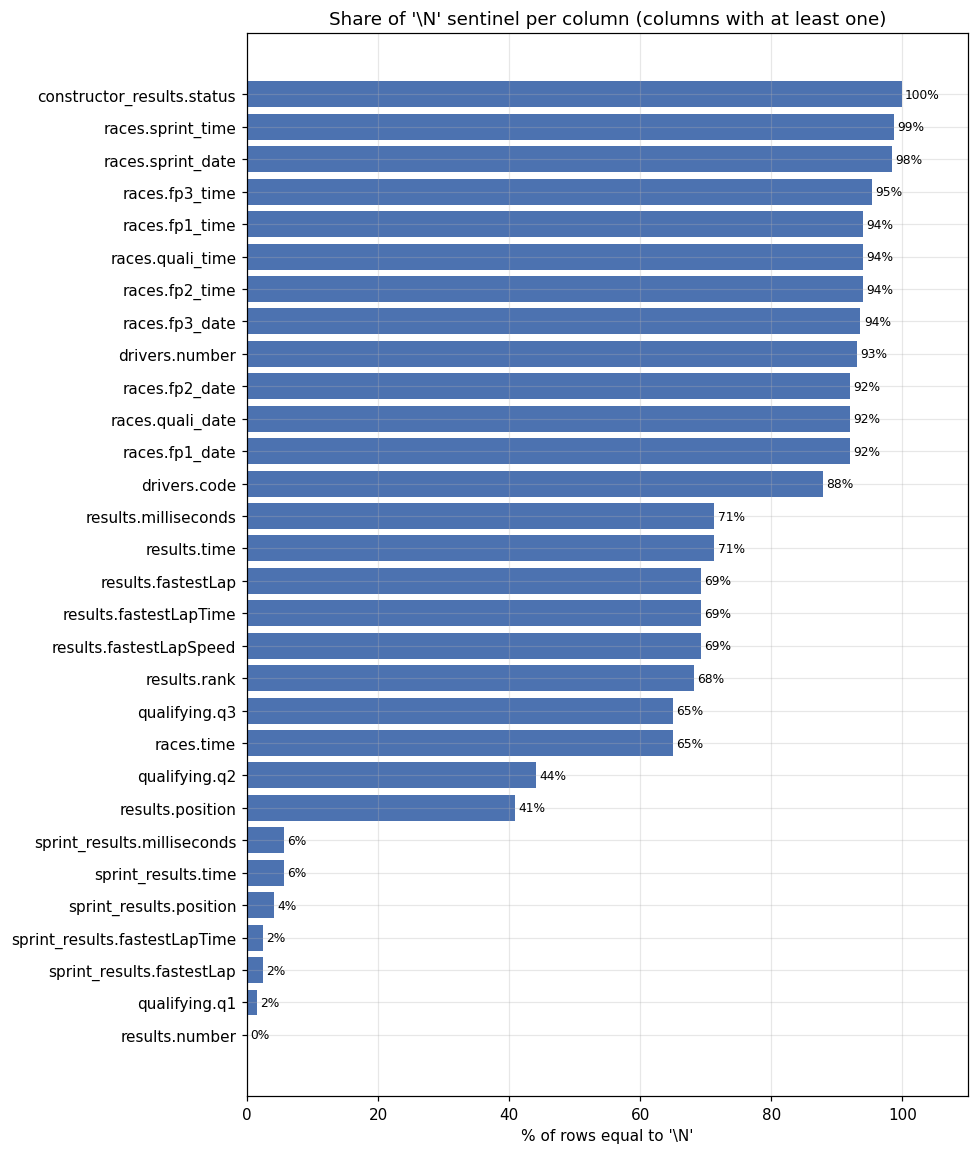

In [6]:
plot_df = placeholder_report[placeholder_report["\\N"] > 0].copy()
plot_df["label"] = plot_df["table"] + "." + plot_df["column"]
plot_df = plot_df.sort_values("% \\N")

fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot_df) + 1))
ax.barh(plot_df["label"], plot_df["% \\N"], color="#4C72B0")
for y, v in enumerate(plot_df["% \\N"]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel(r"% of rows equal to '\N'")
ax.set_title(r"Share of '\N' sentinel per column (columns with at least one)")
ax.set_xlim(0, 110)
plt.tight_layout()
plt.show()

### 1.2.1 Zeros that may be placeholders

`\N` is not the only way "unknown" is encoded. Some numeric columns use `0` where 0 is not a real value (there is no grid slot 0, no position 0).

In [7]:
zero_checks = [
    ("results", "grid"), ("sprint_results", "grid"), ("qualifying", "position"),
    ("results", "positionOrder"), ("results", "number"), ("qualifying", "number"),
    ("results", "laps"), ("circuits", "alt"),
]
zero_report = pd.DataFrame([
    {"table": t, "column": c, "n_zero": int((RAW[t][c] == "0").sum()),
     "% zero": round(100 * (RAW[t][c] == "0").mean(), 2)}
    for t, c in zero_checks
])
display(zero_report)

,table,column,n_zero,% zero
0,results,grid,1638,6.12
1,sprint_results,grid,11,3.06
2,qualifying,position,0,0.00
3,results,positionOrder,0,0.00
4,results,number,34,0.13
5,qualifying,number,15,0.14
6,results,laps,2532,9.46
7,circuits,alt,2,2.60


### 1.2.2 Inconsistent labels (matter for joins on text)

Question 2 (home-country podiums) needs to match a **driver nationality** to a **circuit country**. Both are free text, so we check how they're spelled.

In [8]:
nat = RAW["drivers"]["nationality"]
country = RAW["circuits"]["country"]

print("Driver nationalities with leading/trailing spaces:", sorted(nat[nat != nat.str.strip()].unique()))
print("\nCircuit countries:", sorted(country.unique()))
print("\nDriver nationalities:", sorted(nat.str.strip().unique()))

direct_matches = sorted(set(nat.str.strip()) & set(country))
print("\nNationality strings that literally equal a circuit country:", direct_matches)

Driver nationalities with leading/trailing spaces: ['Argentinian ']

Circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']

Driver nationalities: ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 

**What this means.**
- `\N` appears in exactly the columns we'd expect to be "not applicable" or "not recorded". Examples: `results.position` (~41%, drivers who weren't classified), `results.time/milliseconds` (~71%, only finishers on the lead lap get a time), `fastestLap*` (~69%, only recorded since 2004), `qualifying.q2/q3` (only drivers who advanced to Q2/Q3), `races.fp*/quali_*/sprint_*` (session schedule only recorded recently), `drivers.number/code` (permanent numbers/codes are a modern thing).
  So **`\N` is mostly "doesn't exist" rather than "lost"**. That changes how we treat it: a missing Q3 time means "eliminated earlier", which is information, not noise.
- **Inconsistent sentinel:** `qualifying.q2/q3` also contain **empty strings** (not `\N`) in some recent rows. A cleaner that only replaces `\N` would miss them, so both must map to missing.
- **`0` as placeholder:** `results.grid = 0` (~6% of rows) is not a real slot (explained in 1.8).
- **Text labels don't line up:** `'Argentinian '` has a trailing space (and `Argentine` also exists). Nationalities are demonyms (`British`, `American`) while countries are names (`UK`, `USA` **and** `United States`). Almost no nationality equals a country string literally, so Q2 needs an explicit nationality → country mapping.

**Why it matters.** Mis-handled placeholders become fake values (e.g. `0` grid read as "pole position", which is better than P1!) or silently drop rows from joins.

## 1.3 Semantic typing: dates, times, durations

For each temporal column we show the **value shapes** (every digit replaced by `9`, so `1:27.452` → `9:99.999`), example raw values, and the target type.
Then we **test-parse** each column in memory (not saved) and count values that fail to parse. That way the conversion rule is proven, not assumed.

In [9]:
def is_missing(s):
    return (s == SENTINEL) | (s.str.strip() == "")


def value_shapes(s, top=4):
    shapes = s[~is_missing(s)].str.replace(r"\d", "9", regex=True).value_counts()
    return ", ".join(f"{k} ({v:,})" for k, v in shapes.head(top).items()) + (" ..." if len(shapes) > top else "")


def duration_to_seconds(v):
    """'h:mm:ss.sss' | 'm:ss.sss' | 'ss.sss' -> float seconds (NaN if not parseable)."""
    try:
        secs = 0.0
        for part in v.split(":"):
            secs = secs * 60 + float(part)
        return secs
    except (ValueError, AttributeError):
        return np.nan


def parse_failures(s, kind):
    present = s[~is_missing(s)]
    if kind == "date":
        parsed = pd.to_datetime(present, format="%Y-%m-%d", errors="coerce")
    elif kind == "clock":
        parsed = pd.to_datetime(present, format="%H:%M:%S", errors="coerce")
    elif kind == "duration":
        parsed = present.map(duration_to_seconds)
    elif kind == "number":
        parsed = pd.to_numeric(present, errors="coerce")
    else:
        return np.nan
    return int(parsed.isna().sum())


SEMANTIC = [
    # table, column, parse kind, target type, note
    ("races", "date", "date", "datetime64 (date)", "race day"),
    ("races", "time", "clock", "time of day -> combine with date (UTC)", "start time; only recorded from ~2005"),
    ("races", "quali_date", "date", "datetime64 (date)", "session schedule, recent seasons only"),
    ("races", "quali_time", "clock", "time of day", "session schedule, recent seasons only"),
    ("races", "fp1_date", "date", "datetime64 (date)", "same pattern for fp2/fp3/sprint"),
    ("drivers", "dob", "date", "datetime64 (date)", "for driver age at race"),
    ("qualifying", "q1", "duration", "float seconds", "lap time m:ss.sss"),
    ("qualifying", "q2", "duration", "float seconds", "missing = eliminated in Q1 / format"),
    ("qualifying", "q3", "duration", "float seconds", "missing = eliminated in Q2 / format"),
    ("results", "time", "mixed", "DO NOT PARSE -> use milliseconds", "winner: total time; others: '+gap'"),
    ("results", "milliseconds", "number", "Int64 milliseconds", "total race time, finishers only"),
    ("results", "fastestLapTime", "duration", "float seconds", "post-race info"),
    ("results", "fastestLapSpeed", "number", "float km/h", "post-race info"),
    ("sprint_results", "time", "mixed", "DO NOT PARSE -> use milliseconds", "same format as results.time"),
    ("sprint_results", "fastestLapTime", "duration", "float seconds", ""),
    ("lap_times", "time", "duration", "float seconds", "also has milliseconds column"),
    ("pit_stops", "time", "clock", "time of day (local)", "wall-clock time of the stop"),
    ("pit_stops", "duration", "duration", "float seconds", "some > 60 s written as m:ss.sss"),
]

typing_report = pd.DataFrame([
    {
        "table.column": f"{t}.{c}",
        "non-missing": int((~is_missing(RAW[t][c])).sum()),
        "value shapes (count)": value_shapes(RAW[t][c]),
        "examples": " | ".join(RAW[t][c][~is_missing(RAW[t][c])].drop_duplicates().head(3)),
        "target type": target,
        "parse failures": parse_failures(RAW[t][c], kind),
        "note": note,
    }
    for t, c, kind, target, note in SEMANTIC
])
display(typing_report)

,table.column,non-missing,value shapes (count),examples,target type,parse failures,note
0,races.date,1125,"9999-99-99 (1,125)",2009-03-29 | 2009-04-05 | 2009-04-19,datetime64 (date),0.0,race day
1,races.time,394,99:99:99 (394),06:00:00 | 09:00:00 | 07:00:00,time of day -> combine with date (UTC),0.0,start time; only recorded from ~2005
2,races.quali_date,90,9999-99-99 (90),2021-04-17 | 2022-03-19 | 2021-03-27,datetime64 (date),0.0,"session schedule, recent seasons only"
3,races.quali_time,68,99:99:99 (68),15:00:00 | 17:00:00 | 06:00:00,time of day,0.0,"session schedule, recent seasons only"
4,races.fp1_date,90,9999-99-99 (90),2021-04-16 | 2022-03-18 | 2021-03-26,datetime64 (date),0.0,same pattern for fp2/fp3/sprint
5,drivers.dob,861,9999-99-99 (861),1985-01-07 | 1977-05-10 | 1985-06-27,datetime64 (date),0.0,for driver age at race
6,qualifying.q1,10338,"9:99.999 (10,337), 99:99.999 (1)",1:26.572 | 1:26.103 | 1:25.664,float seconds,0.0,lap time m:ss.sss
7,qualifying.q2,5847,"9:99.999 (5,847)",1:25.187 | 1:25.315 | 1:25.452,float seconds,0.0,missing = eliminated in Q1 / format
8,qualifying.q3,3629,"9:99.999 (3,629)",1:26.714 | 1:26.869 | 1:27.079,float seconds,0.0,missing = eliminated in Q2 / format
9,results.time,7680,"+99.999 (2,973), +9:99.999 (1,614), 9:99:99.999 (765), +...",1:34:50.616 | +5.478 | +8.163,DO NOT PARSE -> use milliseconds,NaN,winner: total time; others: '+gap'


**Cross-check:** `lap_times`, `pit_stops` and `results` carry a `milliseconds` column next to the text time. If our parser is right, both must agree.

In [10]:
checks = []
for t, text_col in [("lap_times", "time"), ("pit_stops", "duration")]:
    d = RAW[t]
    ok = ~is_missing(d[text_col]) & ~is_missing(d["milliseconds"])
    parsed_ms = d.loc[ok, text_col].map(duration_to_seconds) * 1000
    diff = (parsed_ms - pd.to_numeric(d.loc[ok, "milliseconds"])).abs()
    checks.append({"column": f"{t}.{text_col}", "rows compared": int(ok.sum()),
                   "max |parsed - milliseconds| (ms)": round(diff.max(), 3),
                   "rows differing by > 1 ms": int((diff > 1).sum())})

# results.time only equals milliseconds for the winner (absolute time); everyone else has a '+gap'.
r = RAW["results"]
has_time = ~is_missing(r["time"])
checks.append({"column": "results.time", "rows compared": int(has_time.sum()),
               "max |parsed - milliseconds| (ms)": np.nan,
               "rows differing by > 1 ms": int(r.loc[has_time, "time"].str.startswith("+").sum())})
display(pd.DataFrame(checks))
print("results.time rows starting with '+' are gaps to the winner, not race times.")

,column,rows compared,max |parsed - milliseconds| (ms),rows differing by > 1 ms
0,lap_times.time,589081,0.0,0
1,pit_stops.duration,11371,0.0,0
2,results.time,7680,NaN,6552


results.time rows starting with '+' are gaps to the winner, not race times.


### 1.3.1 Numeric columns stored as text

Every column where **all non-missing values parse as numbers** should become numeric. If it has missing values, it should use a nullable type (`Int64` / `float`), so the missing ones stay missing instead of becoming `0`.

In [11]:
num_rows = []
for t, df in RAW.items():
    for col in df.columns:
        s = df[col]
        present = s[~is_missing(s)]
        if present.empty:
            continue
        as_num = pd.to_numeric(present, errors="coerce")
        if as_num.notna().all():
            is_int = bool((as_num == np.floor(as_num)).all())
            n_missing = int(is_missing(s).sum())
            num_rows.append({"table": t, "column": col, "naive dtype": str(NAIVE[t][col].dtype),
                             "missing": n_missing,
                             "proposed": ("Int64" if is_int else "float64") + (" (nullable)" if n_missing else "")})

numeric_report = pd.DataFrame(num_rows)
print(f"{len(numeric_report)} columns are purely numeric apart from placeholders.")
display(numeric_report[numeric_report["naive dtype"] == "object"]
        .rename(columns={"naive dtype": "naive dtype (wrong)"}))

73 columns are purely numeric apart from placeholders.


,table,column,naive dtype (wrong),missing,proposed
16,drivers,number,object,802,Int64 (nullable)
31,results,number,object,6,Int64 (nullable)
33,results,position,object,10953,Int64 (nullable)
37,results,milliseconds,object,19079,Int64 (nullable)
38,results,fastestLap,object,18507,Int64 (nullable)
39,results,rank,object,18249,Int64 (nullable)
40,results,fastestLapSpeed,object,18507,float64 (nullable)
64,sprint_results,position,object,15,Int64 (nullable)
68,sprint_results,milliseconds,object,20,Int64 (nullable)
69,sprint_results,fastestLap,object,9,Int64 (nullable)


**What this means.**
- **Dates** (`races.date`, `drivers.dob`, session dates) are clean `YYYY-MM-DD`, with 0 parse failures. They become real dates, so we can sort races chronologically (essential for "past races only" features) and compute driver age.
- **Lap and qualifying times** (`m:ss.sss`) become **seconds as float**, which makes them comparable and usable as numbers. Some `pit_stops.duration` values over a minute are written `m:ss.sss` (red-flag stoppages), and a few lap times use `h:mm:ss.sss`. That's why the parser handles 1–3 parts instead of assuming one format. The milliseconds cross-check shows the parser reproduces the official milliseconds exactly.
- **`results.time` must not be parsed as a duration.** For the winner it's the total race time, for everyone else it's a gap (`+5.478`). The same column mixes two meanings. `milliseconds` is the consistent version, and it's post-race anyway.
- The numeric list shows which ID/count columns are text only because of `\N`.

**Why it matters.** Correct types are the precondition for everything else: chronological ordering for leakage-safe features, numeric features for the models, and correct joins on ID columns.

## 1.4 Primary-key check

For each table we test the **surrogate key** (the `...Id` column) and the **natural key** (what the row *means*, e.g. "one driver in one race").
A valid key is **unique** and **non-null** (no `\N` / empty).

In [12]:
KEYS = [
    # table, key columns, key kind
    ("circuits", ["circuitId"], "surrogate"), ("circuits", ["circuitRef"], "natural"),
    ("constructors", ["constructorId"], "surrogate"), ("constructors", ["constructorRef"], "natural"),
    ("drivers", ["driverId"], "surrogate"), ("drivers", ["driverRef"], "natural"),
    ("seasons", ["year"], "natural"),
    ("status", ["statusId"], "surrogate"),
    ("races", ["raceId"], "surrogate"), ("races", ["year", "round"], "natural"),
    ("results", ["resultId"], "surrogate"), ("results", ["raceId", "driverId"], "natural (our grain)"),
    ("qualifying", ["qualifyId"], "surrogate"), ("qualifying", ["raceId", "driverId"], "natural"),
    ("sprint_results", ["resultId"], "surrogate"), ("sprint_results", ["raceId", "driverId"], "natural"),
    ("driver_standings", ["driverStandingsId"], "surrogate"), ("driver_standings", ["raceId", "driverId"], "natural"),
    ("constructor_standings", ["constructorStandingsId"], "surrogate"), ("constructor_standings", ["raceId", "constructorId"], "natural"),
    ("constructor_results", ["constructorResultsId"], "surrogate"), ("constructor_results", ["raceId", "constructorId"], "natural"),
    ("lap_times", ["raceId", "driverId", "lap"], "natural (no surrogate)"),
    ("pit_stops", ["raceId", "driverId", "stop"], "natural (no surrogate)"),
]

pk_rows = []
for t, key, kind in KEYS:
    d = RAW[t]
    n_null = int(d[key].apply(is_missing).any(axis=1).sum())
    n_dup_rows = int(d.duplicated(key, keep=False).sum())
    pk_rows.append({"table": t, "key": " + ".join(key), "kind": kind, "rows": len(d),
                    "null keys": n_null, "rows in duplicated keys": n_dup_rows,
                    "valid PK": n_null == 0 and n_dup_rows == 0})

pk_report = pd.DataFrame(pk_rows)
display(pk_report.style.apply(
    lambda row: ["background-color: #f8d7da" if not row["valid PK"] else "" for _ in row], axis=1))

,table,key,kind,rows,null keys,rows in duplicated keys,valid PK
0,circuits,circuitId,surrogate,77,0,0,True
1,circuits,circuitRef,natural,77,0,0,True
2,constructors,constructorId,surrogate,212,0,0,True
3,constructors,constructorRef,natural,212,0,0,True
4,drivers,driverId,surrogate,861,0,0,True
5,drivers,driverRef,natural,861,0,0,True
6,seasons,year,natural,75,0,0,True
7,status,statusId,surrogate,139,0,0,True
8,races,raceId,surrogate,1125,0,0,True
9,races,year + round,natural,1125,0,0,True


**What this means.** Every surrogate `...Id` key is unique and non-null, so the tables are internally consistent.
The **only key that fails is `results (raceId, driverId)`**: the same driver appears more than once in the same race. That's exactly our modeling grain, so it must be fixed (see 1.6).
`qualifying` and `driver_standings` *are* unique per (raceId, driverId), so joining them onto `results` won't multiply rows.

**Why it matters.** If a join key isn't unique on the "one" side, a join silently duplicates rows. Duplicated rows inflate the dataset, bias the model, and can leak the same race into train and test.

## 1.5 Foreign-key check

For every foreign key we count child values that **don't exist** in the parent table (orphans). We also check the reverse direction where it matters (parents with no children).

In [13]:
FKS = [
    # child table, child column, parent table, parent column
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
]

fk_rows = []
for child, ccol, parent, pcol in FKS:
    vals = RAW[child][ccol]
    missing = is_missing(vals)
    orphan = ~missing & ~vals.isin(RAW[parent][pcol])
    fk_rows.append({"FK": f"{child}.{ccol} -> {parent}.{pcol}", "rows": len(vals),
                    "null FK": int(missing.sum()), "orphans": int(orphan.sum()),
                    "orphan examples": ", ".join(vals[orphan].unique()[:5])})
fk_report = pd.DataFrame(fk_rows)
display(fk_report)
print("All foreign keys reconcile:", bool((fk_report["orphans"] == 0).all()))

,FK,rows,null FK,orphans,orphan examples
0,races.circuitId -> circuits.circuitId,1125,0,0,
1,races.year -> seasons.year,1125,0,0,
2,results.raceId -> races.raceId,26759,0,0,
3,results.driverId -> drivers.driverId,26759,0,0,
4,results.constructorId -> constructors.constructorId,26759,0,0,
5,results.statusId -> status.statusId,26759,0,0,
6,qualifying.raceId -> races.raceId,10494,0,0,
7,qualifying.driverId -> drivers.driverId,10494,0,0,
8,qualifying.constructorId -> constructors.constructorId,10494,0,0,
9,sprint_results.raceId -> races.raceId,360,0,0,


All foreign keys reconcile: True


In [14]:
# Reverse direction + cross-table consistency checks.
res, quali, races = RAW["results"], RAW["qualifying"], RAW["races"]

races_without_results = races[~races["raceId"].isin(res["raceId"])]
q_keys = quali.set_index(["raceId", "driverId"]).index
r_keys = res.set_index(["raceId", "driverId"]).index
quali_without_result = int((~q_keys.isin(r_keys)).sum())

# Same driver, same race: does qualifying list the same constructor as results?
both = res.merge(quali, on=["raceId", "driverId"], suffixes=("_res", "_q"))
team_mismatch = both[both["constructorId_res"] != both["constructorId_q"]]

print(f"Races with no results rows:           {len(races_without_results)}")
print(f"Qualifying rows with no results row:  {quali_without_result}")
print(f"Drivers never appearing in results:   {int((~RAW['drivers']['driverId'].isin(res['driverId'])).sum())}")
print(f"results vs qualifying constructorId mismatches: {len(team_mismatch)}")
display(team_mismatch.merge(races[["raceId", "year", "name"]], on="raceId")
        [["raceId", "year", "name", "driverId", "constructorId_res", "constructorId_q", "position_q", "grid"]])

Races with no results rows:           0
Qualifying rows with no results row:  0
Drivers never appearing in results:   0
results vs qualifying constructorId mismatches: 10


,raceId,year,name,driverId,constructorId_res,constructorId_q,position_q,grid
0,937,2015,Belgian Grand Prix,833,209,206,20,17
1,937,2015,Belgian Grand Prix,829,209,206,19,15
2,941,2015,Russian Grand Prix,833,209,206,19,18
3,941,2015,Russian Grand Prix,829,209,206,18,17
4,942,2015,United States Grand Prix,834,209,206,18,17
5,942,2015,United States Grand Prix,829,209,206,19,19
6,943,2015,Mexican Grand Prix,834,209,206,18,16
7,943,2015,Mexican Grand Prix,829,209,206,19,17
8,944,2015,Brazilian Grand Prix,829,209,206,19,18
9,944,2015,Brazilian Grand Prix,834,209,206,18,17


**What this means.** Every foreign key resolves (0 orphans). Every race has results and every qualifying row has a matching result, so a **left join from `results`** loses nothing.
The one soft inconsistency is a handful of rows where `qualifying` and `results` list a *different constructor* for the same driver in the same race (data-entry quirks). When we need the constructor, we'll take it from `results`, the table that defines the grain.

**Why it matters.** Orphan keys would make inner joins silently drop rows, or left joins produce unexplained NaNs. Here we can join safely, and any NaN after a join means "not recorded", not "broken link".

## 1.6 Duplicate (raceId, driverId) pairs in `results`

In [15]:
drivers = RAW["drivers"].assign(driver=lambda d: d["forename"] + " " + d["surname"])[["driverId", "driver"]]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = (res[dup_mask]
        .merge(races[["raceId", "year", "name"]], on="raceId")
        .merge(drivers, on="driverId")
        .merge(RAW["status"], on="statusId")
        .sort_values(["raceId", "driverId", "resultId"]))

pairs = dups.groupby(["raceId", "driverId"])
print(f"Duplicated rows: {len(dups)}  |  distinct (raceId, driverId) pairs: {pairs.ngroups}  "
      f"|  share of results: {100 * len(dups) / len(res):.2f}%")
print("Rows per duplicated pair:", pairs.size().value_counts().sort_index().to_dict())
print("Constructors per duplicated pair:", pairs["constructorId"].nunique().value_counts().sort_index().to_dict())
print("Years:", f"{dups['year'].min()}-{dups['year'].max()}")

Duplicated rows: 176  |  distinct (raceId, driverId) pairs: 85  |  share of results: 0.66%
Rows per duplicated pair: {2: 79, 3: 6}
Constructors per duplicated pair: {1: 69, 2: 15, 3: 1}
Years: 1950-1978


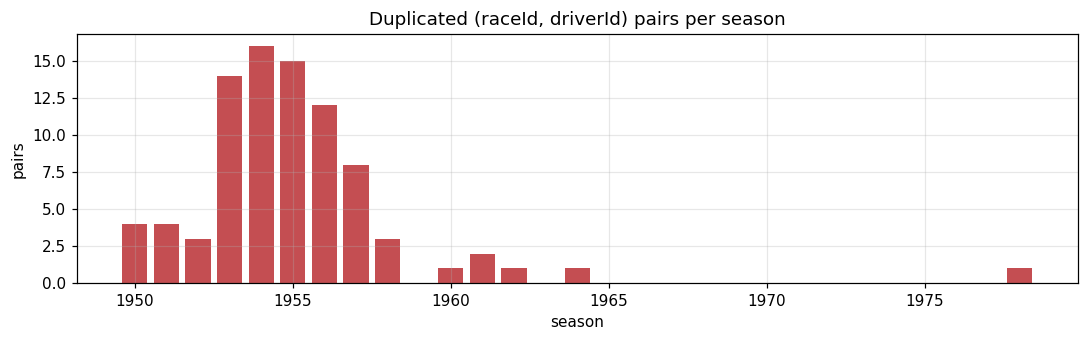

,year,name,pairs,rows
0,1950,French Grand Prix,1,2
1,1950,Indianapolis 500,1,2
2,1950,Italian Grand Prix,2,4
3,1951,French Grand Prix,3,6
4,1951,Italian Grand Prix,1,2
5,1952,Dutch Grand Prix,1,2
6,1952,French Grand Prix,1,2
7,1952,Swiss Grand Prix,1,2
12,1953,Swiss Grand Prix,2,4
11,1953,Indianapolis 500,8,18


In [16]:
per_year = dups.groupby("year").apply(lambda g: g.groupby(["raceId", "driverId"]).ngroups, include_groups=False)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(per_year.index.astype(int), per_year.values, color="#C44E52")
ax.set_title("Duplicated (raceId, driverId) pairs per season")
ax.set_xlabel("season")
ax.set_ylabel("pairs")
plt.tight_layout()
plt.show()

display(dups.groupby(["year", "name"]).agg(pairs=("driverId", lambda s: s.nunique()), rows=("resultId", "size"))
        .reset_index().sort_values("year"))

A few complete examples (all original columns), chosen to show the different kinds of duplicate:

In [17]:
def show_pair(race_id, driver_id):
    d = dups[(dups["raceId"] == race_id) & (dups["driverId"] == driver_id)]
    display(Markdown(f"**{d['year'].iat[0]} {d['name'].iat[0]} - {d['driver'].iat[0]}**"))
    display(d[list(res.columns) + ["status"]])


# Pick one example of each kind found in the data.
kinds = pairs.agg(n_constructors=("constructorId", "nunique"),
                  any_podium=("positionOrder", lambda s: (s.astype(int) <= 3).any()),
                  all_no_start=("grid", lambda s: (s == "0").all())).reset_index()
examples = [
    kinds[(kinds["n_constructors"] == 1) & kinds["any_podium"]].iloc[0],    # shared drive that reached the podium
    kinds[(kinds["n_constructors"] == 1) & ~kinds["any_podium"]].iloc[0],   # shared drive, no podium
    kinds[kinds["n_constructors"] > 1].iloc[0],                              # two different teams' cars
    kinds[kinds["all_no_start"]].iloc[-1],                                   # entries that never started
]
for ex in examples:
    show_pair(ex["raceId"], ex["driverId"])

**1960 Argentine Grand Prix - Stirling Moss**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
8,18083,746,475,170,36,1,\N,R,17,0,40,\N,\N,\N,\N,\N,\N,22,Suspension
173,22372,746,475,170,38,8,3,3,3,0,80,+36.9,8306400,\N,\N,\N,\N,1,Finished


**1964 United States Grand Prix - Jim Clark**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
2,17363,717,373,172,1,1,7,7,7,0,102,\N,\N,\N,\N,\N,\N,60,Out of fuel
175,24304,717,373,172,2,1,\N,R,12,0,54,\N,\N,\N,\N,\N,\N,98,Injection


**1978 Italian Grand Prix - Harald Ertl**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
0,13189,540,229,54,10,0,\N,F,26,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify
1,13192,540,229,57,23,0,\N,F,29,0,0,\N,\N,\N,\N,\N,\N,97,Did not prequalify


**1958 Monaco Grand Prix - Ron Flockhart**

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,status
9,18510,766,541,87,22,0,\N,F,17,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify
10,18520,766,541,66,10,0,\N,F,27,0,0,\N,\N,\N,\N,\N,\N,81,Did not qualify


**Effect on the target:** if duplicates are left in, a race can have more than 3 "podium" rows.

In [18]:
po = res.assign(positionOrder=res["positionOrder"].astype(int))
podium_rows = po[po["positionOrder"] <= 3].groupby("raceId").size()
odd = podium_rows[podium_rows != 3]
print("Races by number of rows with positionOrder <= 3:", podium_rows.value_counts().sort_index().to_dict())
dup_races = set(dups["raceId"])
print(f"Races with != 3 podium rows: {len(odd)}, of which contain duplicated pairs: {sum(r in dup_races for r in odd.index)}")
print("positionOrder values repeated within a race:", int(po.duplicated(["raceId", "positionOrder"]).sum()))

Races by number of rows with positionOrder <= 3: {3: 1107, 4: 16, 5: 1, 7: 1}
Races with != 3 podium rows: 18, of which contain duplicated pairs: 16
positionOrder values repeated within a race: 123


The 2 races with too many podium rows but **no** duplicated pair point to a second kind of shared drive. **Different drivers** share one car, so each driver appears only once,
but both are credited with the same `positionOrder`. Checking for repeated (`raceId`, `positionOrder`) finds these:

In [19]:
shared_pos = (po[po.duplicated(["raceId", "positionOrder"], keep=False)]
              .merge(races[["raceId", "year", "name"]], on="raceId")
              .merge(drivers, on="driverId"))
shared_pos["same driver twice"] = shared_pos.duplicated(["raceId", "driverId"], keep=False)
print(f"Rows sharing a positionOrder with another row in the same race: {len(shared_pos)} "
      f"(years {shared_pos['year'].min()}-{shared_pos['year'].max()})")
print("  of which are the same driver twice (already covered above):", int(shared_pos["same driver twice"].sum()))
print("  of which are different drivers sharing one result:", int((~shared_pos["same driver twice"]).sum()))

example_races = odd.index[~odd.index.isin(list(dup_races))]
display(shared_pos[shared_pos["raceId"].isin(example_races) & (shared_pos["positionOrder"] <= 3)]
        [["year", "name", "driver", "constructorId", "number", "grid", "positionOrder", "points", "laps"]]
        .sort_values(["year", "positionOrder"]))

Rows sharing a positionOrder with another row in the same race: 228 (years 1950-1964)
  of which are the same driver twice (already covered above): 62
  of which are different drivers sharing one result: 166


,year,name,driver,constructorId,number,grid,positionOrder,points,laps
92,1951,Indianapolis 500,Jack McGrath,113,9,3,3,2,200
113,1951,Indianapolis 500,Manny Ayulo,113,9,3,3,2,200
43,1955,Indianapolis 500,Tony Bettenhausen,113,10,2,2,3,200
189,1955,Indianapolis 500,Paul Russo,113,10,2,2,3,200


**What this means.**
- There are **85 duplicated pairs (176 rows, ~0.7% of results)**. Most pairs have 2 rows and a few have 3. They concentrate in **1950–1958**, with a small tail into the 1960s and one case in 1978. There are none after 1978.
- Most are **shared drives**: the same constructor, with two drivers credited for one car. That's why a race can show 4–7 rows with `positionOrder <= 3` and why `positionOrder` repeats within a race: the shared result is credited to every driver of that car.
- A minority are **different constructors**: a driver entered in two cars, or took over a team-mate's car. Some are entries that never started at all (`grid = 0`, e.g. *Did not qualify* / *Withdrew* twice).
- There is also a **second kind of shared drive** that the (raceId, driverId) check can't see: two *different* drivers credited with one car's result (e.g. the 1951 and 1955 Indianapolis 500). These rows aren't duplicates for our grain, since each driver appears once. They do mean a race can legitimately have **more than 3 podium-labelled drivers** even after de-duplication. That matches the official record (both drivers are credited) and only affects 1950-1964.

**Options for which row to keep (not chosen yet):**

| Rule | How | Pros | Cons |
|---|---|---|---|
| A. Best result | keep the row with the lowest `positionOrder` | Target = "did this driver get podium credit at all", matches the official record | The kept row's `grid`/car may be one the driver **didn't start in**. Its pre-race features then describe another car (subtle leakage: the row was chosen *because* of its outcome) |
| B. Starting entry | keep the row the driver actually **started** in. In practice: the lowest `resultId`, as a proxy for the starting car, plus a short list of verified overrides (2.6) | Selection uses only pre-race info, so features and target describe the same car. Consistent with the cutoff | May label a driver "no podium" even though he shared a podium car later in the race. The proxy can be wrong for a few pairs |
| C. Hybrid | features from the starting entry, target = podium in **any** of his rows | Keeps the official credit and pre-race-consistent features | Mixes two rows into one, which is harder to explain and test |
| D. Drop all duplicated pairs | remove these 176 rows | Simplest, no arbitrary choice | Loses data (small), and removes some genuine podiums from 1950s races |

Practical note: these rows are all from 1950-1978, so they never reach a 2003+ model. They do reach an all-years model and the data-engineering questions that use all seasons, and the brief requires a documented rule.

## 1.7 Qualifying coverage by season

For each season: what % of `results` rows have a matching `qualifying` row (same raceId + driverId)?
We also show the % of races with *any* qualifying data (to separate "whole race missing" from "some drivers missing"), and the % of rows with a usable `grid` (> 0) for comparison.

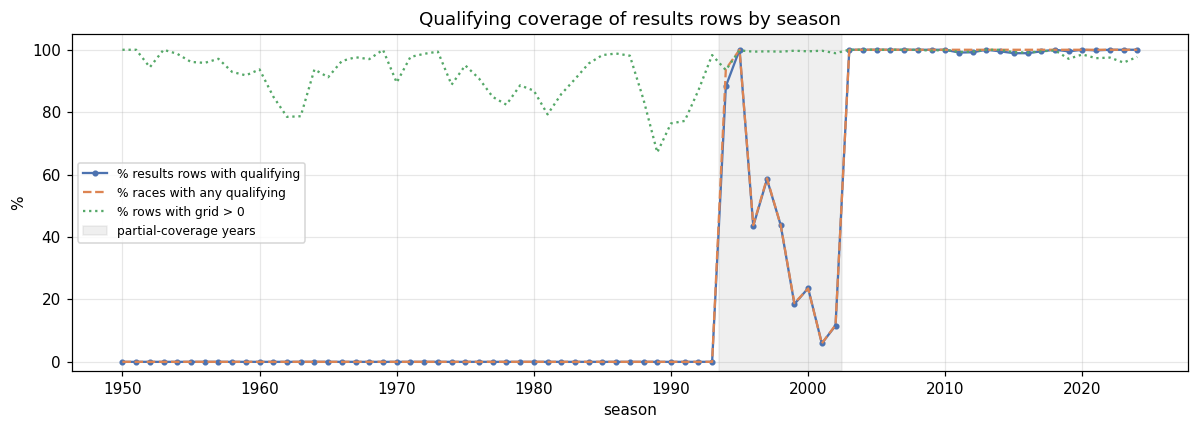

,% results rows with qualifying,% races with any qualifying,% rows with grid > 0
year,,,
1990,0.0,0.0,76.4
1991,0.0,0.0,77.2
1992,0.0,0.0,87.0
1993,0.0,0.0,98.3
1994,88.3,93.8,93.5
1995,100.0,100.0,99.8
1996,43.5,43.8,99.4
1997,58.5,58.8,99.5
1998,43.8,43.8,99.4


First season of continuous ~full coverage: 2003


In [20]:
rq = (res[["raceId", "driverId", "grid"]]
      .merge(quali[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
             on=["raceId", "driverId"], how="left")
      .merge(races[["raceId", "year"]], on="raceId"))
rq["year"] = rq["year"].astype(int)
rq["has_quali"] = rq["quali_pos"].notna()

coverage = pd.DataFrame({
    "% results rows with qualifying": 100 * rq.groupby("year")["has_quali"].mean(),
    "% races with any qualifying": 100 * rq.groupby(["year", "raceId"])["has_quali"].any().groupby("year").mean(),
    "% rows with grid > 0": 100 * (rq["grid"] != "0").groupby(rq["year"]).mean(),
}).round(1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(coverage.index, coverage.iloc[:, 0], marker="o", ms=3, label=coverage.columns[0], color="#4C72B0")
ax.plot(coverage.index, coverage.iloc[:, 1], ls="--", label=coverage.columns[1], color="#DD8452")
ax.plot(coverage.index, coverage.iloc[:, 2], ls=":", label=coverage.columns[2], color="#55A868")
ax.axvspan(1993.5, 2002.5, color="grey", alpha=0.12, label="partial-coverage years")
ax.set_ylim(-3, 105)
ax.set_ylabel("%")
ax.set_xlabel("season")
ax.set_title("Qualifying coverage of results rows by season")
ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

display(coverage.loc[1990:2006])
first_full = coverage.index[(coverage.iloc[:, 0] >= 98) & (coverage.index > 2002)].min()
print("First season of continuous ~full coverage:", first_full)

**What this means.**
- **1950–1993: 0% coverage.** The `qualifying` table simply doesn't exist for those seasons.
- **1994–2002: patchy.** 1994–95 are nearly complete, but 1996–2002 only cover some races (whole races missing, the dashed line), dropping as low as ~6% of rows in 2001.
- **2003 onward: ~100%** (tiny gaps are drivers with no qualifying entry).
- Meanwhile `grid` (dotted line) is available in almost every season.

**Why it matters.** Qualifying features (position, gap to pole, Q1/Q2/Q3 times) are only usable from 2003 (or 1994 if we accept gaps). Our options are: (a) restrict the modeling table to ≥ 2003; (b) use all years but rely on `grid` and treat qualifying as missing (with a "has qualifying" flag); (c) impute. A model trained across eras would also learn "qualifying missing ⇒ old era", which is a known limitation the brief explicitly asks us to discuss (qualifying-coverage drift).

## 1.8 Qualifying position vs. `grid`

`qualifying.position` = where the driver qualified. `results.grid` = where they actually **started**. They can differ (penalties, pit-lane starts, other drivers' penalties). Compared on rows that have both.

Rows with both values:         10,494
grid == qualifying position:   76.1%
grid == 0 (among these rows):  87
Among grid > 0: started further back 5.1%, further forward 18.2%


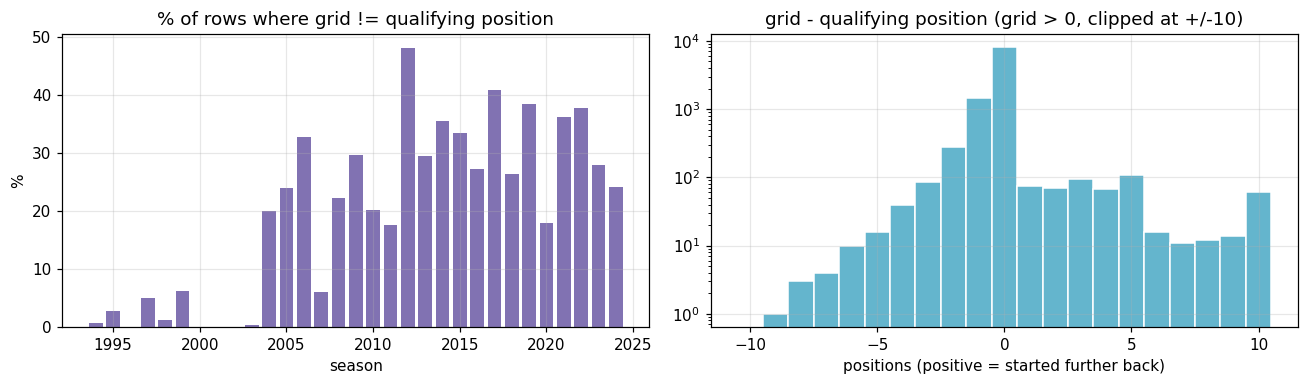

In [21]:
both = rq[rq["has_quali"]].copy()
both["grid_n"] = both["grid"].astype(int)
both["quali_n"] = both["quali_pos"].astype(int)
both["grid_minus_quali"] = both["grid_n"] - both["quali_n"]
started_from_grid = both[both["grid_n"] > 0]

print(f"Rows with both values:         {len(both):,}")
print(f"grid == qualifying position:   {100 * (both['grid_minus_quali'] == 0).mean():.1f}%")
print(f"grid == 0 (among these rows):  {int((both['grid_n'] == 0).sum())}")
print(f"Among grid > 0: started further back {100 * (started_from_grid['grid_minus_quali'] > 0).mean():.1f}%, "
      f"further forward {100 * (started_from_grid['grid_minus_quali'] < 0).mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
diff_by_year = 100 * (both["grid_minus_quali"] != 0).groupby(both["year"]).mean()
axes[0].bar(diff_by_year.index, diff_by_year.values, color="#8172B2")
axes[0].set_title("% of rows where grid != qualifying position")
axes[0].set_xlabel("season")
axes[0].set_ylabel("%")

clipped = started_from_grid["grid_minus_quali"].clip(-10, 10)
axes[1].hist(clipped, bins=np.arange(-10.5, 11.5, 1), color="#64B5CD", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("grid - qualifying position (grid > 0, clipped at +/-10)")
axes[1].set_xlabel("positions (positive = started further back)")
plt.tight_layout()
plt.show()

In [22]:
# What does grid = 0 mean? Look at the race status of those rows, split by whether they have a qualifying row.
g0 = (res[res["grid"] == "0"]
      .merge(RAW["status"], on="statusId")
      .merge(races[["raceId", "year"]], on="raceId")
      .merge(quali[["raceId", "driverId"]], on=["raceId", "driverId"], how="left", indicator=True))
g0["in_qualifying"] = g0.pop("_merge") == "both"
g0["era"] = np.where(g0["year"].astype(int) < 1994, "1950-1993", "1994-2024")

print(f"Total results rows with grid = 0: {len(g0):,}")
display(g0.groupby("era").size().rename("rows").to_frame())
for era, d in g0.groupby("era"):
    display(Markdown(f"**{era}: top statuses for grid = 0**"))
    display(d["status"].value_counts().head(8).to_frame("rows"))
display(Markdown("**grid = 0 rows that DO have a qualifying row: did they race?**"))
display(g0[g0["in_qualifying"]]["status"].value_counts().head(8).to_frame("rows"))

Total results rows with grid = 0: 1,638


,rows
era,
1950-1993,1508
1994-2024,130


**1950-1993: top statuses for grid = 0**

,rows
status,
Did not qualify,978
Did not prequalify,331
Withdrew,158
Accident,16
Excluded,6
Disqualified,6
Engine,5
Injury,2


**1994-2024: top statuses for grid = 0**

,rows
status,
Did not qualify,35
+1 Lap,27
Finished,22
+2 Laps,7
Injury,6
Withdrew,6
Accident,4
Collision damage,3


**grid = 0 rows that DO have a qualifying row: did they race?**

,rows
status,
+1 Lap,26
Finished,22
+2 Laps,7
Did not qualify,5
Accident,4
Withdrew,4
Collision damage,3
Injury,2


**What this means.**
- On rows with both values, about **3 in 4 match**. The rest differ, and the difference is common in the modern era (often 20–45% of rows per season) because of grid penalties (engine/gearbox changes, impeding, etc.) and their knock-on effect on everyone else. **Qualifying position is not the starting position.**
- **`grid = 0` means "no grid slot"**, and it has two different meanings:
  - **Before ~1994:** mostly *Did not qualify / Did not prequalify / Withdrew*. These drivers **never started the race**, but they still have a `results` row (with a `positionOrder`!).
  - **Modern era (with a qualifying row):** mostly *Finished / +N Laps*. The driver **started from the pit lane** (e.g. after car changes under parc fermé). They raced, just from behind the last slot.
- So `grid = 0` must **never** be read as a number "better than pole".

**Why it matters.**
- For Q1 (front-row conversion) we must decide whether "front row" means **qualified** P1–P2 or **started** P1–P2. The brief asks us to distinguish them.
- For the model, `grid` is valid pre-race info (it's known at lights out) and is likely our strongest feature. It needs recoding: pit-lane start → a value behind the last grid slot plus a flag, not `0`.
- Rows of drivers who **never started** (DNQ/DNPQ/withdrew) arguably aren't "a driver entering a race" in the prediction sense. Keeping them adds easy negatives that inflate scores. This is a decision for the cleaning plan.

## 1.9 Join map: which tables, which keys

**Modeling table (grain = one row per raceId + driverId)**, built from `results` as the spine (left joins, so no driver-race is dropped):

| Join | Key(s) | What it brings | Unique on the right side? (1.4) |
|---|---|---|---|
| `results` ← `races` | `raceId` | year, round, date, circuitId (chronological ordering) | yes |
| `races` ← `circuits` | `circuitId` | circuit identity, country | yes |
| `results` ← `qualifying` | `raceId`, `driverId` | qualifying position, Q1/Q2/Q3 times | yes |
| `results` ← `drivers` | `driverId` | dob (age), nationality | yes |
| `results` ← `constructors` | `constructorId` | team identity | yes |
| `results` ← `driver_standings` of the **previous race** | `driverId` + previous `raceId` of the same season | points/position/wins *before* this race | yes |
| `results` ← `constructor_standings` of the **previous race** | `constructorId` + previous `raceId` | team form before this race | yes |
| `results` ← `sprint_results` (optional) | `raceId`, `driverId` | sprint finish (sprint runs *before* the GP, 2021+) | yes |
| past `results` (self-join on earlier races) | `driverId` / `constructorId`, date < race date | rolling form: recent podium rate, average finish | built by us |

**Data-engineering questions**

| Question | Tables | Keys |
|---|---|---|
| Q1 Front-row → podium by circuit, pre/post 2014 | `results` + `qualifying` + `races` + `circuits` | `raceId`+`driverId` (quali), `raceId` (races), `circuitId` (circuits) |
| Q2 Home-country podium effect, controlling for grid | `results` + `races` + `circuits` + `drivers` (+ a nationality→country mapping we create) | `raceId`, `circuitId`, `driverId` |
| Q3 Constructor mechanical-retirement rates 2014–21 vs 2022–24 | `results` + `status` + `races` + `constructors` | `statusId`, `raceId` (year), `constructorId` |

For Q3 we'll need to classify `status` values into mechanical / accident / driver / regulation / finished. Here is what actually occurs in 2014–2024:

In [23]:
status_recent = (res.merge(races[["raceId", "year"]], on="raceId")
                 .loc[lambda d: d["year"].astype(int) >= 2014]
                 .merge(RAW["status"], on="statusId")["status"].value_counts())
print(f"{len(status_recent)} distinct status values in 2014-2024:")
display(status_recent.to_frame("rows").T)

66 distinct status values in 2014-2024:


status,Finished,+1 Lap,+2 Laps,Collision,Accident,Engine,Collision damage,Retired,Brakes,Power Unit,Gearbox,Suspension,+3 Laps,Hydraulics,Withdrew,Electrical,Power loss,Wheel,Spun off,Disqualified,Oil leak,Overheating,Water pressure,Puncture,Mechanical,Turbo,+4 Laps,Exhaust,Fuel pressure,Battery,...,Radiator,Wheel nut,Illness,Transmission,Rear wing,Oil pressure,Steering,Fuel leak,+8 Laps,Clutch,Technical,Vibrations,Throttle,+6 Laps,Driveshaft,Damage,Fuel system,Drivetrain,Brake duct,Excluded,Seat,Spark plugs,Debris,+5 Laps,Out of fuel,Cooling system,Water pump,Fuel pump,Differential,+7 Laps
rows,2403,1178,208,150,85,81,59,50,49,42,42,25,24,15,14,14,13,11,11,11,10,8,7,7,7,6,6,5,5,5,...,3,3,3,3,3,2,2,2,2,2,2,2,2,2,2,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1


**What this means.** The modeling table only needs **one-to-one left joins on keys we've verified are unique**, so the grain can't blow up. The time-dependent tables (standings, past results) must be joined to the **previous** race, not the current one (see 1.10).
The status list shows many specific failure causes (`Engine`, `Gearbox`, `Power Unit`, `Hydraulics`, ...) mixed with crash (`Accident`, `Collision`), driver and regulation (`Disqualified`) labels. Q3's answer depends on an explicit, documented mapping.

## 1.10 Leakage and irrelevant columns

The test for every candidate feature is: **would we know this value after qualifying, before lights out?**

In [24]:
leakage = pd.DataFrame([
    ("results", "position, positionText, positionOrder", "LEAK (this is the target)", "finishing result of the race we predict"),
    ("results", "points", "LEAK", "awarded after the race"),
    ("results", "laps", "LEAK", "laps completed: known only at the end (low laps = DNF)"),
    ("results", "statusId / status", "LEAK", "Finished / Engine / Accident: outcome of the race"),
    ("results", "time, milliseconds", "LEAK", "race duration / gap to winner"),
    ("results", "fastestLap, rank, fastestLapTime, fastestLapSpeed", "LEAK", "measured during the race"),
    ("lap_times", "all (current race)", "LEAK", "recorded during the race"),
    ("pit_stops", "all (current race)", "LEAK", "recorded during the race"),
    ("driver_standings", "points, position, wins @ current raceId", "LEAK", "standings AFTER this race -> must use the previous race's row"),
    ("constructor_standings", "points, position, wins @ current raceId", "LEAK", "same: use previous race"),
    ("constructor_results", "points, status @ current raceId", "LEAK", "constructor points from this race"),
    ("results", "grid", "OK", "starting slot, known at lights out (needs grid=0 recoding)"),
    ("qualifying", "position, q1, q2, q3", "OK", "qualifying happens before the race"),
    ("sprint_results", "position, grid, points (2021+)", "OK with care", "sprint is held before the GP; only exists for ~18 weekends"),
    ("races", "year, round, circuitId, date", "OK", "schedule is known in advance"),
    ("drivers / constructors / circuits", "ids, dob, nationality, country", "OK", "static attributes"),
    ("past results / standings", "rolling form over EARLIER races", "OK if strictly lagged", "must exclude the current race (shift by one race)"),
    ("all", "url, circuitRef, driverRef, constructorRef, name strings", "IRRELEVANT", "identifiers/links, no predictive signal beyond the Id"),
    ("races", "fp1-3 / quali / sprint date & time", "IRRELEVANT", ">90% missing, schedule metadata only"),
    ("drivers", "number, code", "IRRELEVANT", "mostly missing, just labels"),
    ("circuits", "lat, lng, alt", "LOW VALUE", "static location, circuit Id already captures it"),
    ("seasons", "url", "IRRELEVANT", "only a link"),
], columns=["table", "columns", "verdict", "reason"])
display(leakage)

,table,columns,verdict,reason
0,results,"position, positionText, positionOrder",LEAK (this is the target),finishing result of the race we predict
1,results,points,LEAK,awarded after the race
2,results,laps,LEAK,laps completed: known only at the end (low laps = DNF)
3,results,statusId / status,LEAK,Finished / Engine / Accident: outcome of the race
4,results,"time, milliseconds",LEAK,race duration / gap to winner
5,results,"fastestLap, rank, fastestLapTime, fastestLapSpeed",LEAK,measured during the race
6,lap_times,all (current race),LEAK,recorded during the race
7,pit_stops,all (current race),LEAK,recorded during the race
8,driver_standings,"points, position, wins @ current raceId",LEAK,standings AFTER this race -> must use the previous race'...
9,constructor_standings,"points, position, wins @ current raceId",LEAK,same: use previous race


**Why it matters.** Leakage is the biggest risk in this project: `laps`, `status` or same-race `points` would give near-perfect scores that are useless in practice.
The subtle one is **standings**. `driver_standings` for a `raceId` includes the points *from that race*, so it looks like "season context" but contains the answer. Any form/standings feature must come from **strictly earlier races**.

## 1.11 Cleaning plan (approved, applied in section 2)

Ordered by priority: grain and leakage first (they decide correctness), then typing, then convenience. Every step works on **copies**; the raw files stay untouched.

| # | Step | Evidence | Decision you need to make |
|---|---|---|---|
| 1 | **Fix the grain**: one row per (`raceId`, `driverId`) in `results` | 1.4, 1.6: 85 duplicated pairs, races with > 3 "podiums" | Choose rule A/B/C/D (1.6), and whether to accept > 3 podium drivers per race from cross-driver shared drives (1950-1964) |
| 2 | **Define who is "entering a race"**: decide whether to drop rows that never started (grid = 0 with DNQ / DNPQ / Withdrew) | 1.8 | Keep or drop non-starters |
| 3 | **Sentinels → missing**: replace `\N` **and** empty/whitespace strings with `NaN` everywhere; strip padded text (`'Argentinian '`) | 1.2 | – |
| 4 | **Numeric typing**: IDs/counts → `Int64` (nullable), points/speeds → float | 1.3.1 | – |
| 5 | **Semantic typing**: dates → `datetime64`; q1/q2/q3, lap times, pit durations, fastest laps → float seconds; race date + time → timestamp; **don't parse `results.time`** (use `milliseconds`) | 1.3 + ms cross-check | – |
| 6 | **Recode `grid = 0`**: pit-lane start → a value behind the last grid slot + `pit_lane_start` flag; never keep `0` as a number | 1.8 | Exact recoding value |
| 7 | **Choose the modeling window**: 2003+ (full qualifying), 1994+ with gaps, or all years with missing-qualifying handling | 1.7 | Window |
| 8 | **Leakage guard**: drop or quarantine every post-race column (1.10); build standings and form features from the **previous** race only | 1.10 | – |
| 9 | **Label harmonisation for Q2**: nationality → country mapping (`British`→`UK`, `American`→`USA`/`United States`, ...), unify `USA`/`United States` | 1.2.2 | Treatment of dual nationalities (`American-Italian`, `East German`) |
| 10 | **Status taxonomy for Q3**: map each status to mechanical / accident / driver / regulation / finished | 1.9 | Borderline labels (`Retired`, `Puncture`, `Damage`, `Debris`) |
| 11 | **Re-run the audit checks on the cleaned copies** (PK unique, FK reconcile, no `\N`, types correct) plus a before/after EDA, as the brief requires | – | – |

## 1.12 Export: duplicates and anomalies per table

Every row-level problem found above is collected and written to **one CSV per raw table** in `outputs/anomalies/`, so it can be inspected outside the notebook (Excel, a reviewer, the report).
These are new files; the raw CSVs are not touched (verified again in 1.13).

Each output row is **one raw row + one anomaly** (a row with two problems appears twice):
- `csv_line`: line number in the original CSV (header = line 1), to find the row in the raw file.
- `anomaly_type` / `anomaly_detail`: what is wrong and why it was flagged.
- then all original columns, exactly as written in the raw file.

`_summary.csv` lists the count per table and anomaly type, including tables with nothing flagged.

Checks applied (all derived from sections 1.2–1.8):

| Anomaly type | Tables | Source |
|---|---|---|
| duplicate key | any table whose natural key repeats | 1.4 / 1.6 |
| shared result (different drivers) | results | 1.6 |
| race has > 3 podium rows | results | 1.6 |
| grid = 0 (no grid slot) | results, sprint_results | 1.2.1 / 1.8 |
| constructor differs from results / qualifying | results, qualifying | 1.5 |
| empty-string sentinel (not `\N`) | any | 1.2 |
| padded text | any | 1.2 |
| label synonym | circuits.country, drivers.nationality | 1.2.2 |
| duration outlier (pit stop ≥ 60 s, lap ≥ 10 min, qualifying lap ≥ 5 min) | pit_stops, lap_times, qualifying | 1.3 |
| unusual status value | constructor_results | 1.2 |
| non-numeric positionText | driver/constructor standings | sanity check |
| missing car number | results | 1.2 |

In [25]:
ANOMALY_DIR = Path("outputs/anomalies")
ANOMALY_DIR.mkdir(parents=True, exist_ok=True)
for old in ANOMALY_DIR.glob("*.csv"):  # only our own generated reports live here
    old.unlink()

found = {t: [] for t in TABLES}


def flag(table, mask, kind, detail):
    """Record the raw rows selected by `mask` under one anomaly type."""
    rows = RAW[table].loc[mask].copy()
    if rows.empty:
        return
    if isinstance(detail, pd.Series):
        detail = detail.loc[rows.index]
    rows.insert(0, "anomaly_detail", detail)
    rows.insert(0, "anomaly_type", kind)
    rows.insert(0, "csv_line", rows.index + 2)  # header is line 1
    found[table].append(rows)


status_name = RAW["results"]["statusId"].map(dict(zip(RAW["status"]["statusId"], RAW["status"]["status"])))

# --- generic checks on every table --------------------------------------------------------
for t, df in RAW.items():
    for col in df.columns:
        s, stripped = df[col], df[col].str.strip()
        flag(t, stripped == "", "empty-string sentinel", f"{col} is empty instead of \\N")
        flag(t, (s != stripped) & (stripped != ""), "padded text", f"{col} has leading/trailing spaces: '" + s + "'")

for t, key, kind in KEYS:
    d = RAW[t]
    n = d.groupby(key)[key[0]].transform("size")
    flag(t, n > 1, "duplicate key", f"{' + '.join(key)} shared by " + n.astype(str) + " rows")

# --- results / sprint_results ---------------------------------------------------------------
r = RAW["results"]
same_driver_twice = r.duplicated(["raceId", "driverId"], keep=False)
shared_pos = r.duplicated(["raceId", "positionOrder"], keep=False) & ~same_driver_twice
flag("results", shared_pos, "shared result (different drivers)",
     "positionOrder " + r["positionOrder"] + " also credited to another driver in this race")

po_int = r["positionOrder"].astype(int)
podiums_per_race = (po_int <= 3).groupby(r["raceId"]).transform("sum")
flag("results", (po_int <= 3) & (podiums_per_race > 3), "race has > 3 podium rows",
     "race has " + podiums_per_race.astype(str) + " rows with positionOrder <= 3")

flag("results", r["grid"] == "0", "grid = 0 (no grid slot)", "status: " + status_name)
flag("sprint_results", RAW["sprint_results"]["grid"] == "0", "grid = 0 (no grid slot)", "pit-lane / no-grid sprint start")
flag("results", r["number"] == SENTINEL, "missing car number", "number is \\N")

# results vs qualifying: same driver, same race, different constructor (flag the row in both tables)
pair = (r.reset_index().merge(RAW["qualifying"].reset_index(), on=["raceId", "driverId"], suffixes=("_r", "_q"))
        .loc[lambda d: d["constructorId_r"] != d["constructorId_q"]])
flag("results", r.index.isin(pair["index_r"]), "constructor differs from qualifying",
     pd.Series("qualifying constructorId " + pair["constructorId_q"].values, index=pair["index_r"].values))
flag("qualifying", RAW["qualifying"].index.isin(pair["index_q"]), "constructor differs from results",
     pd.Series("results constructorId " + pair["constructorId_r"].values, index=pair["index_q"].values))

# --- duration outliers ----------------------------------------------------------------------
pit_s = RAW["pit_stops"]["duration"].map(duration_to_seconds)
flag("pit_stops", pit_s >= 60, "duration outlier", "pit stop of " + pit_s.round(1).astype(str) + " s (likely red flag / repair)")
lap_s = pd.to_numeric(RAW["lap_times"]["milliseconds"]) / 1000
flag("lap_times", lap_s >= 600, "duration outlier", "lap of " + (lap_s / 60).round(1).astype(str) + " min (likely red flag / safety car)")
for q in ["q1", "q2", "q3"]:
    q_s = RAW["qualifying"][q].map(duration_to_seconds)
    flag("qualifying", q_s >= 300, "duration outlier", f"{q} lap of " + q_s.round(1).astype(str) + " s")

# --- categorical oddities --------------------------------------------------------------------
cr = RAW["constructor_results"]
flag("constructor_results", cr["status"] != SENTINEL, "unusual status value",
     "status = '" + cr["status"] + "' (all other rows are \\N)")
for t in ["driver_standings", "constructor_standings"]:
    pt = RAW[t]["positionText"]
    flag(t, ~pt.str.isdigit(), "non-numeric positionText", "positionText = '" + pt + "'")

LABEL_SYNONYMS = {("circuits", "country"): [{"USA", "United States"}],
                  ("drivers", "nationality"): [{"Argentine", "Argentinian"}]}
for (t, col), groups in LABEL_SYNONYMS.items():
    values = RAW[t][col].str.strip()
    for group in groups:
        flag(t, values.isin(group), "label synonym", f"{col} '" + values + "' has a synonym in " + str(sorted(group)))

# --- write one CSV per table + a summary ------------------------------------------------------
summary_rows = []
for t in TABLES:
    if found[t]:
        out = pd.concat(found[t]).sort_values(["csv_line", "anomaly_type"])
        out.to_csv(ANOMALY_DIR / f"{t}_anomalies.csv", index=False)
        summary_rows += [{"table": t, "anomaly_type": k, "rows": v}
                         for k, v in out["anomaly_type"].value_counts().items()]
    else:
        summary_rows.append({"table": t, "anomaly_type": "(none found)", "rows": 0})

anomaly_summary = pd.DataFrame(summary_rows)
anomaly_summary.to_csv(ANOMALY_DIR / "_summary.csv", index=False)

print("Written to", ANOMALY_DIR.resolve())
for f in sorted(ANOMALY_DIR.glob("*.csv")):
    print(f"  {f.name:40s} {sum(1 for _ in open(f, encoding='utf-8')) - 1:>6,} rows")
display(anomaly_summary)

Written to D:\semster 9\ACL Project\ACL-2\outputs\anomalies
  _summary.csv                                 22 rows
  circuits_anomalies.csv                       12 rows
  constructor_results_anomalies.csv            17 rows
  constructor_standings_anomalies.csv          17 rows
  driver_standings_anomalies.csv                1 rows
  drivers_anomalies.csv                        26 rows
  lap_times_anomalies.csv                     626 rows
  pit_stops_anomalies.csv                     517 rows
  qualifying_anomalies.csv                     79 rows
  results_anomalies.csv                     2,021 rows
  sprint_results_anomalies.csv                 11 rows


,table,anomaly_type,rows
0,circuits,label synonym,12
1,constructors,(none found),0
2,constructor_results,unusual status value,17
3,constructor_standings,non-numeric positionText,17
4,drivers,label synonym,25
5,drivers,padded text,1
6,driver_standings,non-numeric positionText,1
7,races,(none found),0
8,results,grid = 0 (no grid slot),1638
9,results,duplicate key,176


**What this gives you.** Each file is a concrete, row-level list of what the cleaning step (1.11) has to deal with, with the exact line in the raw CSV. For example:
- `results_anomalies.csv` holds the 176 duplicate rows (1.6), the cross-driver shared drives, the races with too many podium rows and all `grid = 0` rows, each with its race status.
- `qualifying_anomalies.csv` holds the empty-string sentinels and the constructor mismatches.

Some of these are **real data quirks to fix** (duplicates, empty strings, padded text, synonyms). Others are **legitimate but unusual values to handle deliberately** (long pit stops under red flags, pit-lane starts). The anomaly type says which is which, and the reports make it easy to show the evaluator exactly which rows each cleaning rule touches.

## 1.13 Raw-data immutability check

In [26]:
after = {t: hashlib.sha256(read_raw_bytes(t)).hexdigest() for t in TABLES}
unchanged = all(after[t] == RAW_FINGERPRINT[t] for t in TABLES)
assert unchanged, "A raw file changed during the audit!"
print(f"All {len(TABLES)} raw files are byte-identical to when they were loaded (SHA-256).")

All 14 raw files are byte-identical to when they were loaded (SHA-256).


# 2. Data Cleaning

Everything here works on **copies** (`CLEAN`) of the raw tables. `RAW` and the files on disk are never changed (re-verified in 2.12).

Decisions taken (evidence in section 1):

| Decision | Choice | Why |
|---|---|---|
| Duplicate (raceId, driverId) | **Rule B**: keep the row with the **lowest `resultId`**, as a proxy for the car the driver started in, plus 3 verified overrides where the proxy is wrong | the row is chosen without looking at the result, so features and target describe the same car (1.6, 2.6) |
| Non-starters | **removed**: non-start status (DNQ, DNPQ, Withdrew, 107%) with 0 laps, or no grid slot and 0 laps | they never took the start, so they aren't a "driver entering the race" and would be easy fake negatives (1.8) |
| Indianapolis 500 (1950–1960) | **removed** from the cleaned results (kept aside only for a Q2 robustness check) | a separate American race inside the championship: its own drivers and cars, a 33-car oval field; it distorts Q2 and an all-years model (2.6.1) |
| `grid = 0` (pit-lane start) | that race's last grid slot + 1, plus a `pit_lane_start` flag | 0 would look *better* than pole (1.8) |
| Modeling window | `model_base` = **2003+**; every pre-2003 row is cleaned too (`results_full`) | qualifying coverage is ~100% only from 2003 (1.7). A later all-years model version (missing qualifying left as NaN + a flag) needs the older rows clean as well |
| Standings | use the standings **after the previous round**, never the current race | same-race standings already contain the result (1.10, proven in 2.10.2) |
| Unused / deferred tables | `seasons`, `lap_times`, `pit_stops`, `constructor_results` not used; `sprint_results` cleaned but deferred | one-line reason per table in 2.1 |

## 2.1 Working copies, sentinels and text

In [27]:
# Tables not carried into CLEAN at all.
UNUSED_TABLES = {
    "seasons": "not used: it only lists the years already in races.year (plus a Wikipedia url)",
    "lap_times": "not used as features: recorded during the race (post-race information, 1.10)",
    "pit_stops": "not used as features: recorded during the race (post-race information, 1.10)",
}
# Tables cleaned (so their keys are re-validated in 2.10) but not used by the questions or the current models.
DEFERRED_TABLES = {
    "constructor_results": "not used: per-race team points are already in results and constructor_standings; "
                           "its status column is 99.9% empty",
    "sprint_results": "cleaned but not used in the current models; to be tested later as an optional feature "
                      "(sprint finish + has_sprint flag)",
}
CLEAN = {t: RAW[t].copy() for t in TABLES if t not in UNUSED_TABLES}
cleaning_log = []


def log_step(step, table, before, after, note=""):
    cleaning_log.append({"step": step, "table": table, "rows before": before, "rows after": after,
                         "rows removed": before - after, "note": note})


counts = {"\\N -> NaN": 0, "empty / whitespace-only -> NaN": 0, "leading/trailing spaces stripped": 0}
for t, df in CLEAN.items():
    stripped = df.apply(lambda s: s.str.strip())
    counts["\\N -> NaN"] += int((stripped == SENTINEL).sum().sum())
    counts["empty / whitespace-only -> NaN"] += int((stripped == "").sum().sum())
    counts["leading/trailing spaces stripped"] += int(((df != stripped) & (stripped != "")).sum().sum())
    CLEAN[t] = stripped.mask(stripped.isin([SENTINEL, ""]))  # both placeholder spellings become real missing values

display(pd.DataFrame([(t, "not carried", why) for t, why in UNUSED_TABLES.items()]
                     + [(t, "cleaned, not used", why) for t, why in DEFERRED_TABLES.items()],
                     columns=["table", "status", "reason"]))
display(pd.Series(counts, name="cells").to_frame())

,table,status,reason
0,seasons,not carried,not used: it only lists the years already in races.year ...
1,lap_times,not carried,not used as features: recorded during the race (post-rac...
2,pit_stops,not carried,not used as features: recorded during the race (post-rac...
3,constructor_results,"cleaned, not used",not used: per-race team points are already in results an...
4,sprint_results,"cleaned, not used",cleaned but not used in the current models; to be tested...


,cells
\N -> NaN,160076
empty / whitespace-only -> NaN,68
leading/trailing spaces stripped,1


In [28]:
# Encoding check: is there any mis-decoded text ("web-scraping" mojibake) to repair?
MOJIBAKE = ["Ã", "Â", "â€", "�"]
hits = {f"{t}.{c}": int(df[c].dropna().str.contains("|".join(MOJIBAKE)).sum())
        for t, df in CLEAN.items() for c in df.select_dtypes("object")}
print("Cells with mojibake markers:", sum(hits.values()))
accented = CLEAN["drivers"].loc[~CLEAN["drivers"]["surname"].map(str.isascii), ["forename", "surname"]].head(5)
print("Accented names decode correctly, e.g.:")
display(accented)

Cells with mojibake markers: 0
Accented names decode correctly, e.g.:


,forename,surname
7,Kimi,Räikkönen
47,Marc,Gené
56,Mika,Häkkinen
97,Jean-Denis,Délétraz
108,Jyrki,Järvilehto


**What this did.** `\N` **and** empty strings are now both real missing values (`NaN`), so later steps can't confuse a placeholder with data. Stray spaces are gone (`'Argentinian '` → `'Argentinian'`).
**Unused and deferred tables (one line each, see the table above):**
- `seasons`: not used; it only lists the years already in `races.year`.
- `lap_times`, `pit_stops`: not used as features; they are recorded during the race.
- `constructor_results`: not used; its per-race team points are already in `results` and `constructor_standings`, and its `status` column is 99.9% empty. It is still cleaned so its keys are checked in 2.10.
- `sprint_results`: cleaned but not used in the current models; to be tested later as an optional feature (sprint finish + `has_sprint` flag).

**Encoding:** there is nothing to fix. No cell contains mis-decoded characters, and accented names (e.g. *Räikkönen*) read correctly because the files are valid UTF-8. We document the check instead of "repairing" text that isn't broken.

## 2.2 Columns removed

In [29]:
DROP_COLUMNS = [
    ("circuits", ["circuitRef", "lat", "lng", "alt", "url"], "identifier / link / static geography: circuitId + country carry this"),
    ("constructors", ["url"], "link only"),
    ("drivers", ["number", "code", "url"], "number/code 88-93% missing and only labels; url is a link"),
    ("races", ["url", "fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time",
               "quali_date", "quali_time", "sprint_date", "sprint_time"], "session schedule >90% missing; link"),
    ("qualifying", ["constructorId"], "10 rows disagree with results; results is the source of truth for the team (1.5)"),
    ("results", ["position", "positionText", "time"], "position/positionText repeat positionOrder; time mixes total time and gaps (1.3)"),
    ("sprint_results", ["position", "positionText", "time"], "same as results"),
    ("driver_standings", ["positionText"], "text copy of position, with letter codes ('D')"),
    ("constructor_standings", ["positionText"], "text copy of position, with letter codes ('E')"),
    ("constructor_results", ["status"], "99.9% missing ('D' in 17 rows)"),
]
for t, cols, _ in DROP_COLUMNS:
    CLEAN[t] = CLEAN[t].drop(columns=cols)

display(pd.DataFrame([(t, ", ".join(c), why) for t, c, why in DROP_COLUMNS],
                     columns=["table", "dropped columns", "reason"]))

,table,dropped columns,reason
0,circuits,"circuitRef, lat, lng, alt, url",identifier / link / static geography: circuitId + countr...
1,constructors,url,link only
2,drivers,"number, code, url",number/code 88-93% missing and only labels; url is a link
3,races,"url, fp1_date, fp1_time, fp2_date, fp2_time, fp3_date, f...",session schedule >90% missing; link
4,qualifying,constructorId,10 rows disagree with results; results is the source of ...
5,results,"position, positionText, time",position/positionText repeat positionOrder; time mixes t...
6,sprint_results,"position, positionText, time",same as results
7,driver_standings,positionText,"text copy of position, with letter codes ('D')"
8,constructor_standings,positionText,"text copy of position, with letter codes ('E')"
9,constructor_results,status,99.9% missing ('D' in 17 rows)


**Why these and not more.** Each dropped column is either a link/identifier, mostly empty, a duplicate of another column, or inconsistent with the table that owns the information.
Post-race columns of `results` (`points`, `laps`, `statusId`, ...) are **not** dropped here: the data-engineering questions need them (Q3 uses status). They are kept out of the **modeling** table instead (2.9).

## 2.3 Types: numbers, dates, durations

In [30]:
def to_numeric_if_possible(s):
    """Text column whose non-missing values are all numbers -> Int64 (nullable) or float64."""
    if s.dtype != object or s.dropna().empty:
        return s
    num = pd.to_numeric(s.dropna(), errors="coerce")
    if num.isna().any():
        return s
    full = pd.to_numeric(s)
    return full.astype("Int64") if (num == np.floor(num)).all() else full.astype("float64")


for t in CLEAN:
    CLEAN[t] = CLEAN[t].apply(to_numeric_if_possible)

# Points are always float, even where every value happens to be whole (sprint points: 8, 7, ... 1).
CLEAN["sprint_results"]["points"] = CLEAN["sprint_results"]["points"].astype("float64")

# Dates (and race start as a timestamp where the start time is recorded)
races_c = CLEAN["races"]
races_c["start_utc"] = pd.to_datetime(races_c["date"] + " " + races_c["time"], format="%Y-%m-%d %H:%M:%S")
races_c["date"] = pd.to_datetime(races_c["date"], format="%Y-%m-%d")
CLEAN["races"] = races_c.drop(columns="time")
CLEAN["drivers"]["dob"] = pd.to_datetime(CLEAN["drivers"]["dob"], format="%Y-%m-%d")

# Lap-time strings -> seconds (parser validated against milliseconds in 1.3)
DURATIONS = {"qualifying": ["q1", "q2", "q3"], "results": ["fastestLapTime"], "sprint_results": ["fastestLapTime"]}
for t, cols in DURATIONS.items():
    for c in cols:
        CLEAN[t][f"{c}_sec"] = CLEAN[t][c].map(duration_to_seconds)
    CLEAN[t] = CLEAN[t].drop(columns=cols)

dtype_summary = pd.DataFrame([{"table": t, "dtype": str(d), "column": c}
                              for t, df in CLEAN.items() for c, d in df.dtypes.items()])
display(dtype_summary.groupby(["table", "dtype"])["column"].apply(", ".join).unstack(fill_value=""))

dtype,Int64,datetime64[ns],float64,object
table,,,,
circuits,circuitId,,,"name, location, country"
constructor_results,"constructorResultsId, raceId, constructorId",,points,
constructor_standings,"constructorStandingsId, raceId, constructorId, position,...",,points,
constructors,constructorId,,,"constructorRef, name, nationality"
driver_standings,"driverStandingsId, raceId, driverId, position, wins",,points,
drivers,driverId,dob,,"driverRef, forename, surname, nationality"
qualifying,"qualifyId, raceId, driverId, number, position",,"q1_sec, q2_sec, q3_sec",
races,"raceId, year, round, circuitId","date, start_utc",,name
results,"resultId, raceId, driverId, constructorId, number, grid,...",,"points, fastestLapSpeed, fastestLapTime_sec",


**What this did.** Every column that only holds numbers is now numeric. Columns with gaps use the **nullable** `Int64` type, so a missing value stays missing instead of becoming 0 or forcing floats.
Dates are real dates (needed to order races in time), and lap times are seconds (`q1_sec`, ...), so they can be compared and averaged.
The only text columns left are genuine labels (names, nationality, country, status).
`sprint_results.points` holds only whole numbers, so the automatic typing made it an integer. It is set to float like `results.points`, so the two can be added or compared without a type mismatch.

## 2.4 Labels: countries and nationalities (for Q2)

In [31]:
CLEAN["circuits"]["country"] = CLEAN["circuits"]["country"].replace({"United States": "USA"})
CLEAN["drivers"]["nationality"] = CLEAN["drivers"]["nationality"].replace({"Argentinian": "Argentine"})

# Demonym -> the country spelling used in circuits.country.
# Dual nationalities take the first one listed; East German -> Germany (circuits are listed under Germany).
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentine-Italian": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia",
    "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands", "East German": "Germany",
    "Finnish": "Finland", "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Rhodesia",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
CLEAN["drivers"]["home_country"] = CLEAN["drivers"]["nationality"].map(NATIONALITY_TO_COUNTRY)
unmapped = sorted(CLEAN["drivers"].loc[CLEAN["drivers"]["home_country"].isna(), "nationality"].unique())
assert not unmapped, f"unmapped nationalities: {unmapped}"

circuit_countries = set(CLEAN["circuits"]["country"])
home_countries = set(CLEAN["drivers"]["home_country"])
print("Circuit countries:", len(circuit_countries))
print("Circuit countries with at least one home driver:", len(circuit_countries & home_countries))
print("Circuit countries with no driver from there:", sorted(circuit_countries - home_countries))

Circuit countries: 34
Circuit countries with at least one home driver: 25
Circuit countries with no driver from there: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']


**What this did.** Before, **no** nationality string matched a circuit country (1.2.2). Now every driver has a `home_country` in the same vocabulary as `circuits.country`, so Q2 becomes a simple equality test (`home_country == circuit country`).
Choices to defend: dual nationalities use the first one listed (the nationality the driver raced under), and *East German* maps to *Germany*.

## 2.5 Status taxonomy (for Q3 and the non-starter rule)

Every status is mapped to exactly one of **six categories**: finished, mechanical, accident, regulation, driver, unclear. The brief defines a **mechanical retirement** as a car component failing on its own, excluding crashes, the driver, and regulation decisions.
Statuses whose cause can't be told from the label go to **unclear** instead of being guessed.

The **non-starter rule** in 2.6 doesn't use these categories. It has its own list of statuses that mean "never took the start" (`NON_START_STATUSES`).

In [32]:
import re

# Statuses that mean the car never took the start (used by the non-starter rule in 2.6, together with laps == 0).
NON_START_STATUSES = {"Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"}

STATUS_GROUPS = {
    # failed to qualify, or excluded / disqualified by the rules
    "regulation": {"Disqualified", "Excluded", "Underweight", "Not classified",
                   "Did not qualify", "Did not prequalify", "107% Rule"},
    "accident": {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident"},
    "driver": {"Injury", "Injured", "Illness", "Driver unwell", "Physical", "Eye injury"},
    # cause can't be told from the label: often contact or a pit error, a symptom rather than a part, or no cause given
    "unclear": {"Retired", "Withdrew", "Out of fuel", "Damage", "Debris", "Puncture", "Tyre puncture", "Tyre",
                "Not restarted", "Stalled", "Safety concerns", "Safety", "Fuel rig", "Refuelling",
                "Wheel", "Wheel nut", "Front wing", "Rear wing", "Broken wing", "Undertray", "Vibrations"},
    # a part of the car that fails on its own
    "mechanical": {
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
        "Differential", "Overheating", "Mechanical", "Driver Seat", "Driveshaft", "Fuel pressure", "Water pressure",
        "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak",
        "Wheel rim", "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire",
        "Pneumatics", "Handling", "Fire", "Wheel bearing", "Fuel system", "Oil line", "Launch control",
        "Fuel", "Power loss", "Drivetrain", "Ignition", "Chassis", "Battery", "Halfshaft", "Crankshaft",
        "Alternator", "Safety belt", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo", "CV joint",
        "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto", "Supercharger",
        "Power Unit", "ERS", "Brake duct", "Seat", "Cooling system",
    },
}
STATUS_CATEGORIES = ["finished", "mechanical", "accident", "regulation", "driver", "unclear"]
all_listed = [s for names in STATUS_GROUPS.values() for s in names]
assert len(all_listed) == len(set(all_listed)), "a status is listed in two categories"


def status_category(name):
    if name == "Finished" or re.fullmatch(r"\+\d+ Laps?", name):
        return "finished"
    return next((cat for cat, names in STATUS_GROUPS.items() if name in names), None)


CLEAN["status"]["status_category"] = CLEAN["status"]["status"].map(status_category)
unmapped = CLEAN["status"].loc[CLEAN["status"]["status_category"].isna(), "status"].tolist()
assert not unmapped, f"unmapped statuses: {unmapped}"
assert set(CLEAN["status"]["status_category"]) == set(STATUS_CATEGORIES)

display(CLEAN["status"].groupby("status_category")["status"]
        .agg(n_statuses="size", statuses=lambda s: ", ".join(sorted(s)[:12]) + (" ..." if len(s) > 12 else ""))
        .loc[STATUS_CATEGORIES])

,n_statuses,statuses
status_category,,
finished,34,"+1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps..."
mechanical,66,"Alternator, Axle, Battery, Brake duct, Brakes, CV joint,..."
accident,5,"Accident, Collision, Collision damage, Fatal accident, S..."
regulation,7,"107% Rule, Did not prequalify, Did not qualify, Disquali..."
driver,6,"Driver unwell, Eye injury, Illness, Injured, Injury, Phy..."
unclear,21,"Broken wing, Damage, Debris, Front wing, Fuel rig, Not r..."


**What this did.** All 139 statuses have exactly one of the six categories, and the code asserts that none is missed or listed twice. `+N Laps` counts as *finished* (the car was running at the end, just lapped).

**What changed and why (after review):** the assignment is now consistent.
- **mechanical** holds only parts that fail on their own (engine, gearbox, hydraulics, brakes, suspension, electrical, ...), plus `Technical` and `Seat`.
- **unclear** now also holds `Wheel`, `Rear wing`, `Undertray` and `Vibrations`. They join `Wheel nut` and `Front wing`, which were already there: these are often caused by contact or a pit-stop error, or are a symptom rather than a failed part. `Retired`, `Out of fuel` and `Withdrew` (during the race) give no cause, so they are *unclear* too.
- The old extra group *did not start* is gone. `Did not qualify`, `Did not prequalify` and `107% Rule` are **regulation** outcomes; `Withdrew` is *unclear*. The non-starter rule keeps its own status list, so it is unaffected.

**Note for Q3:** the constructor ranking is reported twice, **strict** (mechanical only) and **broad** (mechanical + unclear). A team that ranks high in both is unreliable whichever way the borderline statuses are counted.

## 2.6 `results`: target, non-starters, duplicates, grid

Order matters. The **target is created first** from the official classification, before any row is removed. Then come non-starters, then duplicates, then the grid recoding.

In [33]:
res_c = CLEAN["results"].merge(CLEAN["status"], on="statusId", how="left", validate="many_to_one")
res_c["podium"] = (res_c["positionOrder"] <= 3).astype("int8")   # target: positionOrder <= 3

# --- Non-starters --------------------------------------------------------------------------------
by_status = res_c["status"].isin(NON_START_STATUSES) & (res_c["laps"] == 0)
no_slot = (res_c["grid"] == 0) & (res_c["laps"] == 0)
non_starter = by_status | no_slot

reason = np.select([by_status, no_slot], ["non-start status, 0 laps", "no grid slot, 0 laps (other status)"], "kept")
display(pd.crosstab(reason, np.where(res_c["grid"] == 0, "grid = 0", "grid > 0"), margins=True))

print("Why the rule uses laps = 0 and not grid = 0: drivers who withdrew while holding a grid slot, e.g. the 2005 US GP:")
usgp05 = CLEAN["races"].query("year == 2005 and name == 'United States Grand Prix'")["raceId"]
display(res_c[res_c["raceId"].isin(usgp05) & by_status]
        .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId")[["surname", "grid", "laps", "status"]].head(6))
print("Pit-lane starters kept (grid = 0, laps > 0):", int(((res_c["grid"] == 0) & (res_c["laps"] > 0)).sum()))

n = len(res_c)
res_c = res_c[~non_starter].copy()
log_step("remove non-starters", "results", n, len(res_c), "non-start status with 0 laps, or grid = 0 with 0 laps")

col_0,grid = 0,grid > 0,All
row_0,,,
kept,72,25042,25114
"no grid slot, 0 laps (other status)",56,0,56
"non-start status, 0 laps",1510,79,1589
All,1638,25121,26759


Why the rule uses laps = 0 and not grid = 0: drivers who withdrew while holding a grid slot, e.g. the 2005 US GP:


,surname,grid,laps,status
0,Trulli,1,0,Withdrew
1,Räikkönen,2,0,Withdrew
2,Button,3,0,Withdrew
3,Fisichella,4,0,Withdrew
4,Alonso,6,0,Withdrew
5,Sato,8,0,Withdrew


Pit-lane starters kept (grid = 0, laps > 0): 72


In [34]:
# --- Duplicates: rule B ----------------------------------------------------------------------------
# Keep the row with the lowest resultId, as a proxy for the car the driver started in.
# Verified overrides: pairs where the proxy is known to keep the car the driver took over mid-race.
# In each case the proxy's row is an exact copy (car, grid, laps, finish) of another driver's only row,
# i.e. that car was the other driver's start.
RULE_B_OVERRIDES = pd.DataFrame([
    (1951, "French Grand Prix", "Ascari", 19935,
     "started car 12 from grid 3 (gearbox, lap 10), then took over González's car 14; the car-14 row copies González's row 20187"),
    (1954, "Belgian Grand Prix", "González", 19276,
     "started car 6 from grid 2 (engine, lap 1), then took over Hawthorn's car 10; the car-10 row copies Hawthorn's row 20238"),
    (1961, "British Grand Prix", "Moss", 17964,
     "started car 28 from grid 5 (brakes, lap 44), then took over Fairman's car 26; the car-26 row copies Fairman's row 20299"),
], columns=["year", "race", "driver", "keep resultId", "why"])

n = len(res_c)
dups = res_c[res_c.duplicated(["raceId", "driverId"], keep=False)]
dup_pairs = int(res_c.duplicated(["raceId", "driverId"]).sum())
both_started = dups.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).all())
print(f"Duplicated pairs after removing non-starters: {len(both_started)}; "
      f"pairs where both rows have grid > 0: {int(both_started.sum())} -> grid can't tell the rows apart")

# Each override must be one of the duplicated rows, for the named driver and race.
ov = (RULE_B_OVERRIDES.merge(dups[["resultId", "raceId", "driverId"]], left_on="keep resultId", right_on="resultId", how="left")
      .merge(CLEAN["races"][["raceId", "year", "name"]], on="raceId", how="left", suffixes=("", "_race"))
      .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId", how="left"))
assert ov["resultId"].notna().all() and (ov["year"] == ov["year_race"]).all() and (ov["race"] == ov["name"]).all() \
    and (ov["driver"] == ov["surname"]).all(), "an override does not match a duplicated pair"

proxy_choice = dups.sort_values("resultId").drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])["resultId"]
RULE_B_OVERRIDES["proxy would keep"] = [proxy_choice.loc[(r, d)] for r, d in zip(ov["raceId"], ov["driverId"])]
display(RULE_B_OVERRIDES[["year", "race", "driver", "proxy would keep", "keep resultId", "why"]])

podium_any = res_c.groupby(["raceId", "driverId"])["podium"].transform("max")
res_c = (res_c.assign(_not_override=~res_c["resultId"].isin(RULE_B_OVERRIDES["keep resultId"]))
         .sort_values(["raceId", "driverId", "_not_override", "resultId"])   # override first, then lowest resultId
         .drop_duplicates(["raceId", "driverId"], keep="first")
         .drop(columns="_not_override"))
lost = res_c[res_c["podium"] < podium_any.loc[res_c.index]].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
log_step("rule B: one row per driver per race", "results", n, len(res_c), f"{dup_pairs} extra rows")
print(f"Duplicate rows removed: {n - len(res_c)}")
print(f"Drivers whose shared-drive podium is not credited under rule B: {len(lost)} "
      f"(seasons {lost['year'].min()}-{lost['year'].max()}, outside the 2003+ window)")

french51 = CLEAN["races"].query("year == 1951 and name == 'French Grand Prix'")["raceId"]
print("1951 French GP, podium rows after rule B + override:")
display(res_c[res_c["raceId"].isin(french51) & (res_c["podium"] == 1)]
        .merge(CLEAN["drivers"][["driverId", "surname"]], on="driverId")
        .sort_values("positionOrder")[["surname", "resultId", "number", "grid", "positionOrder", "status"]])

# --- grid = 0 (pit-lane start) -> that race's last slot + 1, with a flag -------------------------
def recode_pit_lane(df):
    df = df.copy()
    df["pit_lane_start"] = df["grid"] == 0
    last_slot = df.groupby("raceId")["grid"].transform("max")
    df.loc[df["pit_lane_start"], "grid"] = last_slot[df["pit_lane_start"]] + 1
    return df


res_c = recode_pit_lane(res_c)
CLEAN["sprint_results"] = recode_pit_lane(CLEAN["sprint_results"])
print("Pit-lane starts recoded:", int(res_c["pit_lane_start"].sum()), "in results,",
      int(CLEAN["sprint_results"]["pit_lane_start"].sum()), "in sprint_results")
print("Smallest grid value now:", int(res_c["grid"].min()))
CLEAN["results"] = res_c

Duplicated pairs after removing non-starters: 82; pairs where both rows have grid > 0: 82 -> grid can't tell the rows apart


,year,race,driver,proxy would keep,keep resultId,why
0,1951,French Grand Prix,Ascari,19919,19935,"started car 12 from grid 3 (gearbox, lap 10), then took ..."
1,1954,Belgian Grand Prix,González,19268,19276,"started car 6 from grid 2 (engine, lap 1), then took ove..."
2,1961,British Grand Prix,Moss,17962,17964,"started car 28 from grid 5 (brakes, lap 44), then took o..."


Duplicate rows removed: 88
Drivers whose shared-drive podium is not credited under rule B: 17 (seasons 1950-1960, outside the 2003+ window)
1951 French GP, podium rows after rule B + override:


,surname,resultId,number,grid,positionOrder,status
2,Fagioli,19918,8,7,1,Finished
0,González,20187,14,6,2,Finished
1,Villoresi,19920,10,4,3,+3 Laps


Pit-lane starts recoded: 72 in results, 11 in sprint_results


Smallest grid value now: 1


**What this did.**
- **Target first:** `podium` is computed from `positionOrder` before anything is dropped, so cleaning can't change who finished on the podium.
- **Non-starters:** the rule tests **laps = 0**, not `grid = 0`, for the non-start statuses. The 2005 US GP shows why: 14 drivers withdrew before the start *while holding grid slots* (several near the front). With a `grid = 0` test they would stay in the 2003+ data as "started from P3, no podium", which is false. Rows with no grid slot *and* no laps are also removed (crashed in warm-up, injured, excluded before the start).
  Pit-lane starters (`grid = 0` but laps > 0) **raced**, so they stay.
- **Rule B (reworded after review):** keep the row with the **lowest `resultId`**, as a proxy for the car the driver started in. In this dataset the extra (takeover) rows were mostly added later: in 70 of the 85 raw pairs, one row has a `resultId` below 20,000 and the other one above it. `grid` can't decide: in every remaining pair **both** rows have grid > 0, because the second row carries the grid slot of the car's original driver. The rule never looks at the result, so features and target describe the same car. The cost is that a few 1950s drivers lose podium credit from a car they took over mid-race.
- **Verified overrides:** in 3 pairs the proxy is known to be wrong. Its row is an exact copy of another driver's only row (same car, grid, laps and finish), so that car was the other driver's start. For those pairs we keep the driver's own starting car (table above). The most visible case is **Ascari, 1951 French GP**: the proxy kept González's car (2nd place), which gave that race a 4th podium row. With the override, the race has exactly 3 podium rows: Fagioli 1st, González 2nd, Villoresi 3rd.
- **Limitation:** the proxy may still be wrong for a few other 1950s pairs that can't be verified from the data. All of them are before 1979, so they affect only the all-years model version and Q2 (which uses all seasons). Even then the effect is negligible: 82 pairs among ~25,000 rows, and most of them aren't podium rows.
- **Grid:** a pit-lane start becomes "behind the last car" (that race's highest grid + 1), with `pit_lane_start` keeping the information that it happened.

**Limitation: formation-lap failures (documented, no code change).** The data cannot distinguish a car that failed on the formation lap (never started) from one that retired on lap 1; both show 0 laps with a failure status. About 49 rows in 2003+ (0.5%) may be non-starters recorded as starters. We keep them, because removing all 0-lap rows would also remove genuine first-lap retirements and would select rows using race outcomes.

### 2.6.1 Indianapolis 500 (1950–1960)

From 1950 to 1960 the Indianapolis 500 counted as a round of the World Championship, but it was a separate American race: its own drivers and cars, a 33-car field on an oval, and the Grand Prix teams almost never took part. The checks below measure how different it is from the other races.

In [35]:
indy_races = CLEAN["races"].loc[CLEAN["races"]["name"] == "Indianapolis 500", ["raceId", "year"]]
assert len(indy_races) == 11 and indy_races["year"].between(1950, 1960).all()

res_c = CLEAN["results"]
is_indy = res_c["raceId"].isin(indy_races["raceId"])
indy = res_c[is_indy].merge(CLEAN["drivers"][["driverId", "nationality"]], on="driverId")
indy_drivers = indy["driverId"].unique()
other_races = res_c.loc[~is_indy, "driverId"].unique()
print(f"Indianapolis 500: {len(indy_races)} races ({indy_races['year'].min()}-{indy_races['year'].max()}), "
      f"{len(indy)} cleaned rows, {len(indy_drivers)} drivers")
print(f"American drivers: {int((indy['nationality'] == 'American').sum())} of {len(indy)} rows")
print(f"Drivers who never started any other championship race: {int((~pd.Series(indy_drivers).isin(other_races)).sum())} "
      f"of {len(indy_drivers)}")
same_years = CLEAN["races"].loc[CLEAN["races"]["year"] <= 1960, "raceId"]
other_fields = res_c[~is_indy & res_c["raceId"].isin(same_years)].groupby("raceId").size()
print(f"Starters per race: Indy {indy.groupby('raceId').size().median():.0f} (median), "
      f"other 1950-1960 races {other_fields.median():.0f} (median)")

# Set aside (fully cleaned: non-starters, rule B and grid already applied), used only by the Q2 robustness check.
INDY500_RESULTS = res_c[is_indy].copy()
n = len(res_c)
CLEAN["results"] = res_c[~is_indy].copy()
log_step("remove Indianapolis 500 (1950-1960)", "results", n, len(CLEAN["results"]),
         "separate US race in the championship: own drivers, 33-car oval field")
print(f"Rows removed: {n - len(CLEAN['results'])}")

Indianapolis 500: 11 races (1950-1960), 381 cleaned rows, 107 drivers
American drivers: 380 of 381 rows
Drivers who never started any other championship race: 103 of 107
Starters per race: Indy 34 (median), other 1950-1960 races 20 (median)
Rows removed: 381


**What this did and why.** The Indianapolis 500 rows are removed from the cleaned results:
- **Not the same competition:** 380 of its 381 starts are American drivers, and 103 of its 107 drivers never started another championship race. It doesn't describe the F1 Grands Prix we want to predict.
- **It breaks Q2 (home advantage):** every Indy start is a "home" start for an American driver at a US circuit (the only exception is Ascari in 1952). There is no away driver in the same race to compare with, and the 33-car field pushes most of these rows into the back grid bands. Indy alone was 16% of all home starts.
- **It would distort an all-years model:** 381 rows from another series, with no qualifying data.

The `races` rows stay (the races did happen, and `driver_standings` still refers to them), so no foreign key breaks. The removed rows are kept aside in `INDY500_RESULTS`, only so that Q2 can show the result *with* Indy as a robustness check.

## 2.7 Qualifying times: outliers

In [36]:
Q_COLS = ["q1_sec", "q2_sec", "q3_sec"]
q_c = CLEAN["qualifying"]
too_slow = q_c[Q_COLS] > 300   # no modern F1 qualifying lap takes 5 minutes
display(q_c[too_slow.any(axis=1)].merge(CLEAN["races"][["raceId", "year", "name"]], on="raceId"))
q_c[Q_COLS] = q_c[Q_COLS].mask(too_slow)
CLEAN["qualifying"] = q_c

ratio = q_c["q1_sec"] / q_c.groupby("raceId")["q1_sec"].transform("min")
print("Q1 time / fastest Q1 in that race, after the fix:")
display(ratio.describe().round(3).to_frame("ratio").T)

,qualifyId,raceId,driverId,number,position,q1_sec,q2_sec,q3_sec,year,name
0,2569,255,87,7,24,1002.64,NaN,NaN,1995,Japanese Grand Prix


Q1 time / fastest Q1 in that race, after the fix:

,count,mean,std,min,25%,50%,75%,max
ratio,10337.0,1.019,0.019,1.0,1.007,1.013,1.024,1.448


**What this did.** One Q1 time of ~1002 s (about 16 minutes) is impossible as a flying lap, so it becomes missing; the qualifying **position** of that row is kept. After the fix, the slowest Q1 time is a plausible multiple of the race's fastest lap.
Missing Q2/Q3 times are **not** filled in: they mean "eliminated earlier", which is handled as a feature in section 3 (e.g. gap to pole from the best session time).

## 2.8 Leakage-safe standings (pre-race)

`driver_standings` at `raceId = R` are the standings **after** race R. Before race R we only know the standings after the **previous round of the same season**.
We build `*_prerace` tables keyed by the race being predicted. Round 1 has no previous round, so it gets no row (handled as "start of season" in feature engineering).

In [37]:
season_order = CLEAN["races"].sort_values(["year", "round"])[["raceId", "year", "round"]].copy()
season_order["prev_raceId"] = season_order.groupby("year")["raceId"].shift(1).astype("Int64")


def prerace_standings(table, key):
    after_prev = CLEAN[table][["raceId", key, "points", "position", "wins"]].rename(columns={
        "raceId": "prev_raceId", "points": "pre_points", "position": "pre_position", "wins": "pre_wins"})
    out = season_order[["raceId", "prev_raceId"]].dropna().merge(after_prev, on="prev_raceId", how="inner")
    return out.drop(columns="prev_raceId")


CLEAN["driver_standings_prerace"] = prerace_standings("driver_standings", "driverId")
CLEAN["constructor_standings_prerace"] = prerace_standings("constructor_standings", "constructorId")

# Demonstration on the 2021 season finale: same-race standings already contain that race's result.
finale = season_order[season_order["year"] == 2021].iloc[-1]["raceId"]
names = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"])[["driverId", "driver"]]
after = CLEAN["driver_standings"].query("raceId == @finale")[["driverId", "points", "position"]]
before = CLEAN["driver_standings_prerace"].query("raceId == @finale")[["driverId", "pre_points", "pre_position"]]
display(before.merge(after, on="driverId").merge(names, on="driverId")
        .rename(columns={"points": "points AFTER race (leak)", "position": "position AFTER race (leak)"})
        .sort_values("pre_position").head(3)[["driver", "pre_points", "pre_position", "points AFTER race (leak)", "position AFTER race (leak)"]])

,driver,pre_points,pre_position,points AFTER race (leak),position AFTER race (leak)
1,Max Verstappen,369.5,1,395.5,1
0,Lewis Hamilton,369.5,2,387.5,2
2,Valtteri Bottas,218.0,3,226.0,3


**What this shows.** Before the 2021 finale, the top two drivers were tied on points. The same-race standings already show who won the title, i.e. the race result.
Using `driver_standings` at the current `raceId` as a feature would leak the answer. The `*_prerace` tables only contain what was known before lights out.

## 2.9 Output tables: full results (for the questions) and the modeling base (2003+)

In [38]:
MODEL_START_YEAR = 2003

race_info = CLEAN["races"][["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})
results_full = CLEAN["results"].merge(race_info, on="raceId", how="left", validate="many_to_one")

POST_RACE = ["positionOrder", "points", "laps", "milliseconds", "fastestLap", "rank", "fastestLapTime_sec",
             "fastestLapSpeed", "statusId", "status", "status_category"]
PRE_RACE = ["raceId", "driverId", "constructorId", "year", "round", "date", "circuitId", "grid", "pit_lane_start"]

model_base = (results_full.loc[results_full["year"] >= MODEL_START_YEAR, PRE_RACE + ["podium"]]
              .sort_values(["date", "raceId", "grid"]).reset_index(drop=True))
assert not set(POST_RACE) & set(model_base.columns), "post-race column in the modeling table"
log_step(f"modeling window {MODEL_START_YEAR}+", "model_base", len(results_full), len(model_base), "qualifying coverage ~100% from 2003")

print(f"results_full: {len(results_full):,} rows ({results_full['year'].min()}-{results_full['year'].max()}), "
      f"used for the data-engineering questions")
print(f"model_base:   {len(model_base):,} rows, {model_base['raceId'].nunique()} races, "
      f"podium rate {100 * model_base['podium'].mean():.1f}%")
display(model_base.head())

results_full: 24,645 rows (1950-2024), used for the data-engineering questions
model_base:   8,934 rows, 428 races, podium rate 14.4%


,raceId,driverId,constructorId,year,round,date,circuitId,grid,pit_lane_start,podium
0,108,30,6,2003,1,2003-03-09,1,1,False,0
1,108,22,6,2003,1,2003-03-09,1,2,False,0
2,108,31,3,2003,1,2003-03-09,1,3,False,1
3,108,49,15,2003,1,2003-03-09,1,4,False,0
4,108,44,7,2003,1,2003-03-09,1,5,False,0


**Two tables, two purposes.**
- `results_full`: every cleaned driver-race (all years, without the Indianapolis 500) **with** post-race columns. Q1–Q3 need the finishing order and status.
- `model_base`: the modeling grain (one row per driver per race, 2003+) with **only pre-race columns** plus the target. Feature engineering (section 3) adds qualifying, form and standings features to it.
  The code asserts that no post-race column is in it. The podium rate (~14%) shows the class imbalance the metrics must handle (hence PR-AUC).

### 2.9.1 Final status mapping, with row counts

The full status → category table from 2.5, with how many cleaned race starts carry each status: all seasons, and the Q3 window (2014–2024).

In [39]:
status_counts = (results_full.assign(q3_window=results_full["year"] >= 2014)
                 .groupby("statusId").agg(rows_all_years=("resultId", "size"), rows_2014_2024=("q3_window", "sum")))
status_map = (CLEAN["status"].merge(status_counts, on="statusId", how="left")
              .fillna({"rows_all_years": 0, "rows_2014_2024": 0})
              .astype({"rows_all_years": int, "rows_2014_2024": int}))
status_map["status_category"] = pd.Categorical(status_map["status_category"], STATUS_CATEGORIES, ordered=True)
status_map = status_map.sort_values(["status_category", "rows_all_years"], ascending=[True, False])

display(status_map.groupby("status_category", observed=True)[["rows_all_years", "rows_2014_2024"]].sum()
        .assign(n_statuses=status_map.groupby("status_category", observed=True).size()))
with pd.option_context("display.max_rows", 200):
    display(status_map[["status_category", "status", "rows_all_years", "rows_2014_2024"]].reset_index(drop=True))

,rows_all_years,rows_2014_2024,n_statuses
status_category,,,
finished,14921,3825,34
mechanical,6200,372,66
accident,2691,305,5
regulation,314,12,7
driver,55,3,6
unclear,464,94,21


,status_category,status,rows_all_years,rows_2014_2024
0,finished,Finished,7538,2403
1,finished,+1 Lap,4020,1178
2,finished,+2 Laps,1603,208
3,finished,+3 Laps,720,24
4,finished,+4 Laps,392,6
5,finished,+5 Laps,214,1
6,finished,+6 Laps,148,2
7,finished,+7 Laps,92,1
8,finished,+8 Laps,47,2
9,finished,+9 Laps,34,0


**What this shows.** Every status and its category, for review. Six statuses have 0 rows: `107% Rule`, `Did not prequalify`, `Underweight` and `Safety concerns` only occurred on removed non-starter rows, and `+38 Laps` / `+49 Laps` exist in the status table but never in `results`. In the Q3 window, `Retired` is the largest *unclear* status, which is why Q3 also reports the broad version (mechanical + unclear).

## 2.10 Re-validation after cleaning

The section-1 checks re-run on the cleaned tables. They must all pass.

In [40]:
checks = []


def check(name, ok, detail=""):
    checks.append({"check": name, "passed": bool(ok), "detail": detail})


for name, df, key in [("results_full", results_full, ["raceId", "driverId"]),
                      ("model_base", model_base, ["raceId", "driverId"]),
                      ("qualifying", CLEAN["qualifying"], ["raceId", "driverId"]),
                      ("driver_standings_prerace", CLEAN["driver_standings_prerace"], ["raceId", "driverId"]),
                      ("constructor_standings_prerace", CLEAN["constructor_standings_prerace"], ["raceId", "constructorId"])]:
    n_dup, n_null = int(df.duplicated(key).sum()), int(df[key].isna().any(axis=1).sum())
    check(f"{name}: {' + '.join(key)} unique and non-null", n_dup == 0 and n_null == 0, f"{n_dup} duplicates, {n_null} null")

# Every foreign key between the cleaned tables (child.column -> parent.column).
FKS_CLEAN = [
    ("races", "circuitId", "circuits"),
    ("results", "raceId", "races"), ("results", "driverId", "drivers"),
    ("results", "constructorId", "constructors"), ("results", "statusId", "status"),
    ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
    ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
    ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
    ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
    ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
    ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
    ("driver_standings_prerace", "raceId", "races"), ("driver_standings_prerace", "driverId", "drivers"),
    ("constructor_standings_prerace", "raceId", "races"), ("constructor_standings_prerace", "constructorId", "constructors"),
]
fk_report = pd.DataFrame([{
    "foreign key": f"{child}.{col} -> {parent}.{col}",
    "child rows": len(CLEAN[child]),
    "broken references": int((~CLEAN[child][col].dropna().isin(CLEAN[parent][col])).sum()),
} for child, col, parent in FKS_CLEAN])
display(fk_report)
check(f"all {len(FKS_CLEAN)} foreign keys reconcile", fk_report["broken references"].sum() == 0,
      f"{int(fk_report['broken references'].sum())} broken references")
for col, parent in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors"), ("circuitId", "circuits")]:
    broken = int((~model_base[col].isin(CLEAN[parent][col])).sum())
    check(f"FK model_base.{col} -> {parent}", broken == 0, f"{broken} broken")

leftover = sum(int(df[c].isin([SENTINEL, ""]).sum()) for df in CLEAN.values() for c in df.select_dtypes("object"))
check("no '\\N' or empty strings left in any table", leftover == 0, f"{leftover} cells")
check("results_full: grid >= 1 everywhere", results_full["grid"].min() >= 1, f"min grid = {results_full['grid'].min()}")
check("model_base: no text columns (model-ready types)", model_base.select_dtypes("object").empty,
      str(model_base.dtypes.astype(str).to_dict()))
per_race = model_base.groupby("raceId")["podium"].sum()
check("model_base: exactly 3 podium rows per race", (per_race == 3).all(), str(per_race.value_counts().to_dict()))
check("model_base: no post-race columns", not set(POST_RACE) & set(model_base.columns))

check_report = pd.DataFrame(checks)
display(check_report)
assert check_report["passed"].all(), "a post-cleaning check failed"

,foreign key,child rows,broken references
0,races.circuitId -> circuits.circuitId,1125,0
1,results.raceId -> races.raceId,24645,0
2,results.driverId -> drivers.driverId,24645,0
3,results.constructorId -> constructors.constructorId,24645,0
4,results.statusId -> status.statusId,24645,0
5,qualifying.raceId -> races.raceId,10494,0
6,qualifying.driverId -> drivers.driverId,10494,0
7,sprint_results.raceId -> races.raceId,360,0
8,sprint_results.driverId -> drivers.driverId,360,0
9,sprint_results.constructorId -> constructors.constructorId,360,0


,check,passed,detail
0,results_full: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
1,model_base: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
2,qualifying: raceId + driverId unique and non-null,True,"0 duplicates, 0 null"
3,driver_standings_prerace: raceId + driverId unique and n...,True,"0 duplicates, 0 null"
4,constructor_standings_prerace: raceId + constructorId un...,True,"0 duplicates, 0 null"
5,all 21 foreign keys reconcile,True,0 broken references
6,FK model_base.raceId -> races,True,0 broken
7,FK model_base.driverId -> drivers,True,0 broken
8,FK model_base.constructorId -> constructors,True,0 broken
9,FK model_base.circuitId -> circuits,True,0 broken


**What this means.** The grain is fixed (unique `raceId + driverId`), no placeholder text is left, `grid` has no fake zeros, and every 2003+ race has exactly 3 podium rows (the shared-drive anomaly only existed before 1965).
**Foreign keys (extended after review):** the check now covers **all 21** foreign keys between the cleaned tables (it covered 8 before), including the deferred `sprint_results` and `constructor_results` and the new `*_prerace` tables. None has a broken reference: every row still points to an existing race, driver, team, circuit or status. (Only `results` lost rows, and no table references a `results` row.)

### 2.10.1 Further sanity checks on the cleaned data

These don't pass/fail. They look for anything suspicious the cleaning might have caused or left behind.

In [41]:
race_names = CLEAN["races"][["raceId", "year", "round", "name"]]
surnames = CLEAN["drivers"][["driverId", "surname"]]

print("Missing values in model_base:", int(model_base.isna().sum().sum()))
print("Ranges: grid", model_base["grid"].min(), "-", model_base["grid"].max(),
      "| dates", model_base["date"].min().date(), "-", model_base["date"].max().date())
age = (model_base.merge(CLEAN["drivers"][["driverId", "dob"]], on="driverId")
       .pipe(lambda d: (d["date"] - d["dob"]).dt.days / 365.25))
print(f"Driver age at race: {age.min():.1f} - {age.max():.1f} years")
print("Qualifying times (s):", {c: (round(CLEAN['qualifying'][c].min(), 1), round(CLEAN['qualifying'][c].max(), 1)) for c in Q_COLS})

display(Markdown("**Smallest fields (should be explainable races, not cleaning errors)**"))
display(model_base.groupby("raceId").size().nsmallest(2).rename("starters").to_frame().join(race_names.set_index("raceId")))

display(Markdown("**Two starters on the same grid slot (excluding pit-lane starts)**"))
same_slot = model_base[~model_base["pit_lane_start"]]
same_slot = same_slot[same_slot.duplicated(["raceId", "grid"], keep=False)]
display(same_slot.merge(race_names, on=["raceId", "year", "round"]).merge(surnames, on="driverId")[["year", "name", "surname", "grid"]])

display(Markdown("**Races with more than 3 podium rows in results_full**"))
pods = results_full.groupby("raceId")["podium"].sum()
display(race_names[race_names["raceId"].isin(pods[pods > 3].index)])

display(Markdown("**Pre-race standings coverage for model_base rows**"))
for table, key in [("driver_standings_prerace", "driverId"), ("constructor_standings_prerace", "constructorId")]:
    joined = model_base.merge(CLEAN[table], on=["raceId", key], how="left")
    missing = joined["pre_points"].isna()
    print(f"{table}: {int(missing.sum())} rows without a standing, "
          f"{int((missing & (joined['round'] == 1)).sum())} of them in round 1, "
          f"{int((missing & (joined['round'] > 1)).sum())} later in the season")

early = CLEAN["races"].query("year == 2003").sort_values("round")["raceId"].head(3)
print("2003 rounds 1-3 -> standings rows:", CLEAN["driver_standings"][CLEAN["driver_standings"]["raceId"].isin(early)]
      .groupby("raceId").size().tolist(), "vs starters:", results_full[results_full["raceId"].isin(early)].groupby("raceId").size().tolist())

Missing values in model_base: 0
Ranges: grid 1 - 24 | dates 2003-03-09 - 2024-12-08
Driver age at race: 17.5 - 43.9 years
Qualifying times (s): {'q1_sec': (np.float64(53.9), np.float64(153.9)), 'q2_sec': (np.float64(53.6), np.float64(132.5)), 'q3_sec': (np.float64(53.4), np.float64(129.8))}


**Smallest fields (should be explainable races, not cleaning errors)**

,starters,year,round,name
raceId,,,,
79,6,2005,9,United States Grand Prix
926,15,2015,1,Australian Grand Prix


**Two starters on the same grid slot (excluding pit-lane starts)**

,year,name,surname,grid
0,2003,German Grand Prix,Fisichella,13
1,2003,German Grand Prix,Villeneuve,13
2,2015,Italian Grand Prix,Nasr,17
3,2015,Italian Grand Prix,Sainz,17
4,2015,Russian Grand Prix,Ericsson,17
5,2015,Russian Grand Prix,Stevens,17
6,2024,São Paulo Grand Prix,Hülkenberg,17
7,2024,São Paulo Grand Prix,Verstappen,17


**Races with more than 3 podium rows in results_full**

,raceId,year,round,name
791,792,1955,1,Argentine Grand Prix


**Pre-race standings coverage for model_base rows**

driver_standings_prerace: 597 rows without a standing, 455 of them in round 1, 142 later in the season
constructor_standings_prerace: 486 rows without a standing, 455 of them in round 1, 31 later in the season
2003 rounds 1-3 -> standings rows: [11, 15, 17] vs starters: [20, 20, 20]


**What these show.**
- **No missing values** in `model_base`, and ranges are plausible (grid 1–24, driver ages ~17–44, qualifying laps ~53–154 s).
- **Small fields are real:** the 2005 US GP had 6 starters (14 withdrew), and the 2015 Australian GP had 15 (several cars did not start). They aren't cleaning errors.
- **4 pairs of drivers share a grid slot** (e.g. 2015 Italian GP). This comes from the source data around grid penalties, not from cleaning. It's 8 rows out of 8,934. Grid is used as an ordinal feature, so a tie is harmless and the rows are left as they are.
- **1 race with > 3 podium rows** is left: the 1955 Argentine GP, a cross-driver shared drive (1.6) where two different drivers are credited with one car's 3rd place. It's expected and outside the 2003+ window. (There were 4: the Rule B override fixed the 1951 French GP, and the 1951 and 1955 Indianapolis 500 were removed in 2.6.1.)
- **Gaps in the pre-race standings:** `driver_standings` early in a season only lists drivers who already have an entry (2003 round 1 has 11 standings rows for 20 starters). Missing values after round 1 therefore mean **"no points yet"** (or the driver didn't race the previous round), not a broken join. **Rule for feature engineering (section 3):** fill `pre_points` and `pre_wins` with 0, and give `pre_position` a "behind everyone ranked" value plus a `no_standing_yet` flag. Round 1 always gets this treatment.

### 2.10.2 Evidence that standings are post-race

`driver_standings.points` at race R should be the driver's season total **after** race R. To check this, we rebuild each driver's cumulative season points race by race from the cleaned `results` and compare them to the standings in two ways:
- **current race included:** points from round 1 up to and including R;
- **current race not included:** points from round 1 up to R − 1.

If standings are post-race, the first version should match almost every row and the second should not.

In [42]:
rounds = CLEAN["races"][["raceId", "year", "round"]]


def per_race_points(df, name):
    return df.groupby(["raceId", "driverId"])["points"].sum().rename(name).reset_index()


# Points on raw rows that cleaning removed: the Indianapolis 500 (2.6.1), and shared-drive rows dropped by rule B.
raw_pts = RAW["results"][["resultId", "raceId", "driverId", "points"]].astype(
    {"resultId": int, "raceId": int, "driverId": int, "points": float})
removed = raw_pts[~raw_pts["resultId"].isin(CLEAN["results"]["resultId"])]
indy_pts = per_race_points(removed[removed["raceId"].isin(indy_races["raceId"])], "indy_pts")
removed_pts = per_race_points(removed[~removed["raceId"].isin(indy_races["raceId"])], "removed_pts")

# One row per driver, per round of every season in which the driver appears (0 points when he didn't score or race).
driver_seasons = (pd.concat([CLEAN["results"][["raceId", "driverId"]], CLEAN["driver_standings"][["raceId", "driverId"]]])
                  .merge(rounds, on="raceId")[["driverId", "year"]].drop_duplicates())
season = driver_seasons.merge(rounds, on="year")
for extra in [per_race_points(CLEAN["results"], "race_pts"), per_race_points(CLEAN["sprint_results"], "sprint_pts"),
              indy_pts, removed_pts]:
    season = season.merge(extra, on=["raceId", "driverId"], how="left")
season = (season.fillna({"race_pts": 0.0, "sprint_pts": 0.0, "indy_pts": 0.0, "removed_pts": 0.0})
          .sort_values(["driverId", "year", "round"]))
by_season = season.groupby(["driverId", "year"])
season["cum_incl"] = by_season["race_pts"].cumsum()                  # rounds 1..R
season["cum_excl"] = season["cum_incl"] - season["race_pts"]          # rounds 1..R-1
season["sprint_cum"] = by_season["sprint_pts"].cumsum()
season["indy_cum"] = by_season["indy_pts"].cumsum()
season["removed_cum"] = by_season["removed_pts"].cumsum()

st = CLEAN["driver_standings"][["raceId", "driverId", "points"]].merge(season, on=["raceId", "driverId"], how="left",
                                                                         validate="one_to_one")
st["match_incl"] = np.isclose(st["points"], st["cum_incl"])
st["match_excl"] = np.isclose(st["points"], st["cum_excl"])
scored = st["race_pts"] > 0
display(pd.DataFrame({
    "all standings rows": [st["match_incl"].mean(), st["match_excl"].mean()],
    "rows where the driver scored in that race": [st.loc[scored, "match_incl"].mean(), st.loc[scored, "match_excl"].mean()],
}, index=["current race INCLUDED", "current race NOT included"]).mul(100).round(1).astype(str).add(" %"))

# Why do the remaining rows not match (current race included)?
mis = st[~st["match_incl"]].copy()
all_removed = mis["cum_incl"] + mis["indy_cum"] + mis["removed_cum"]
half = (mis["points"] % 1 != 0) | (mis["cum_incl"] % 1 != 0)
CAUSES = ["sprint points (standings add the sprint, results don't)",
          "Indianapolis 500 points (rows removed in 2.6.1, still in the standings)",
          "shared drive (points of a row removed by rule B)",
          "best-results rule before 1991 (only the best N scores counted)",
          "half points"]
mis["cause"] = np.select(
    [np.isclose(mis["points"], mis["cum_incl"] + mis["sprint_cum"]),
     np.isclose(mis["points"], all_removed) & (mis["indy_cum"] > 0),
     np.isclose(mis["points"], all_removed) & (mis["removed_cum"] > 0),
     (mis["year"] < 1991) & (mis["points"] < all_removed),
     half],
    CAUSES, "other")
causes = (mis.groupby("cause").agg(rows=("points", "size"), seasons=("year", lambda y: f"{y.min()}-{y.max()}"))
          .reindex(CAUSES + ["other"], fill_value=0))
display(causes)
names_ = CLEAN["drivers"].assign(driver=CLEAN["drivers"]["forename"] + " " + CLEAN["drivers"]["surname"])[["driverId", "driver"]]
display(mis.merge(names_, on="driverId").sort_values(["cause", "year", "round"]).groupby("cause").head(2)
        [["cause", "year", "round", "driver", "points", "cum_incl", "cum_excl", "sprint_cum", "indy_cum", "removed_cum"]]
        .rename(columns={"points": "standings points", "cum_incl": "results incl. race", "cum_excl": "results excl. race"}))

,all standings rows,rows where the driver scored in that race
current race INCLUDED,96.1 %,92.6 %
current race NOT included,74.7 %,0.1 %


,rows,seasons
cause,,
"sprint points (standings add the sprint, results don't)",689,2021-2024
"Indianapolis 500 points (rows removed in 2.6.1, still in the standings)",452,1950-1960
shared drive (points of a row removed by rule B),84,1950-1957
best-results rule before 1991 (only the best N scores counted),124,1950-1990
half points,0,0
other,0,0


,cause,year,round,driver,standings points,results incl. race,results excl. race,sprint_cum,indy_cum,removed_cum
586,"Indianapolis 500 points (rows removed in 2.6.1, still in...",1950,3,Tony Bettenhausen,1.0,0.0,0.0,0.0,1.0,0.0
587,"Indianapolis 500 points (rows removed in 2.6.1, still in...",1950,3,Joie Chitwood,1.0,0.0,0.0,0.0,1.0,0.0
617,best-results rule before 1991 (only the best N scores co...,1950,7,Luigi Fagioli,24.0,28.0,24.0,0.0,0.0,0.0
567,best-results rule before 1991 (only the best N scores co...,1951,6,Juan Fangio,27.0,23.0,16.0,0.0,0.0,5.0
616,shared drive (points of a row removed by rule B),1950,7,Alberto Ascari,11.0,8.0,8.0,0.0,0.0,3.0
552,shared drive (points of a row removed by rule B),1951,4,Alberto Ascari,9.0,6.0,6.0,0.0,0.0,3.0
665,"sprint points (standings add the sprint, results don't)",2021,10,Lewis Hamilton,177.0,175.0,150.0,2.0,0.0,0.0
666,"sprint points (standings add the sprint, results don't)",2021,10,Max Verstappen,185.0,182.0,182.0,3.0,0.0,0.0


**What this shows.** Standings are **post-race**.
- With the current race **included**, the rebuilt totals match `driver_standings.points` in **96.1%** of rows; **not included**, only **74.7%** (those are mostly rows where the driver scored 0 in that race, so both totals are the same).
- The clearest test is the rows where the driver **scored** in that race: **92.6%** match with the race included vs **0.1%** without. The standings row for race R already contains race R's points, so it must be lagged by one race (2.8).
- **Every remaining mismatch has a known cause:** 689 rows are **sprint points** (2021–2024: the standings add the sprint, `results` doesn't). 452 are **Indianapolis 500 points** (1950–1960: the championship counted them, but the Indy rows were removed in 2.6.1). 84 are **shared drives** (1950–1957: the standings count the points of a row that rule B removed). 124 are the **best-results rule** before 1991 (only a driver's best N scores counted, so the standings are lower than the plain sum). **Half points** cause no mismatch, because `results.points` already holds the halves.

## 2.11 Before/after cleaning

The brief asks for EDA **before and after** cleaning, to show what the cleaning changed. Each figure puts the raw data on the **left** and the cleaned data on the **right**.

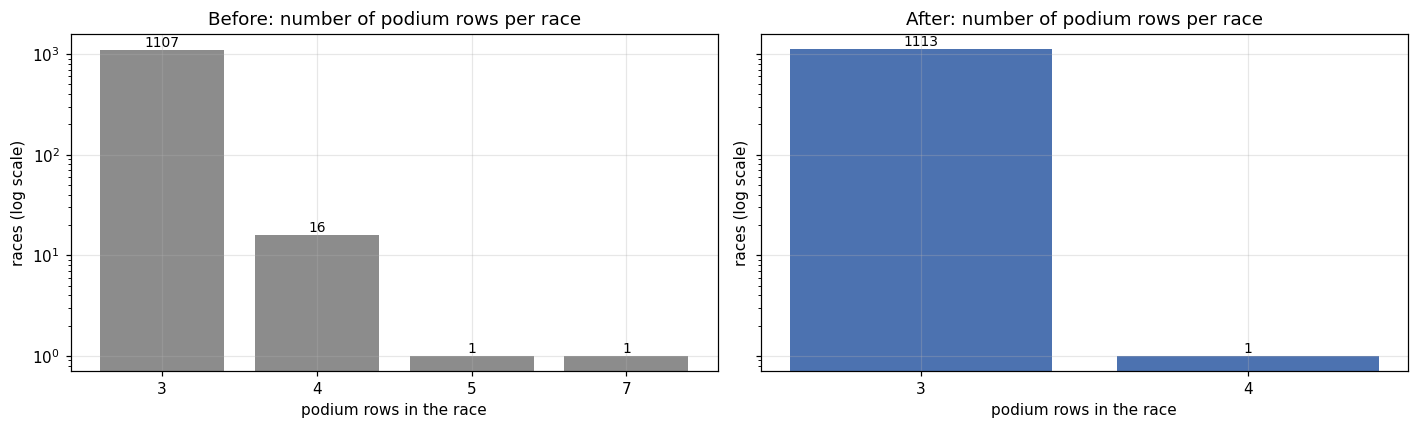

In [43]:
raw_res = RAW["results"].assign(grid=lambda d: d["grid"].astype(int), positionOrder=lambda d: d["positionOrder"].astype(int))
raw_res["podium"] = (raw_res["positionOrder"] <= 3).astype(int)
raw_res = raw_res.merge(RAW["races"][["raceId", "year"]], on="raceId").assign(year=lambda d: d["year"].astype(int))
BEFORE_COLOR, AFTER_COLOR = "#8C8C8C", "#4C72B0"


def before_after(title, figsize=(13, 4), sharey=True):
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=sharey)
    axes[0].set_title(f"Before: {title}")
    axes[1].set_title(f"After: {title}")
    return fig, axes


fig, axes = before_after("number of podium rows per race")
for ax, df, color in [(axes[0], raw_res, BEFORE_COLOR), (axes[1], results_full, AFTER_COLOR)]:
    counts = df.groupby("raceId")["podium"].sum().value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=color)
    ax.bar_label(bars, fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel("podium rows in the race")
    ax.set_ylabel("races (log scale)")
plt.tight_layout()
plt.show()

**Podium rows per race:** before cleaning, 18 races had 4, 5 or 7 "podium" rows (shared drives counted the same driver twice); after the non-starter and duplicate rules and removing the Indianapolis 500, 1,113 of the 1,114 races have exactly 3. The one left with 4 is the 1955 Argentine GP, where two *different* drivers share one car's 3rd place.

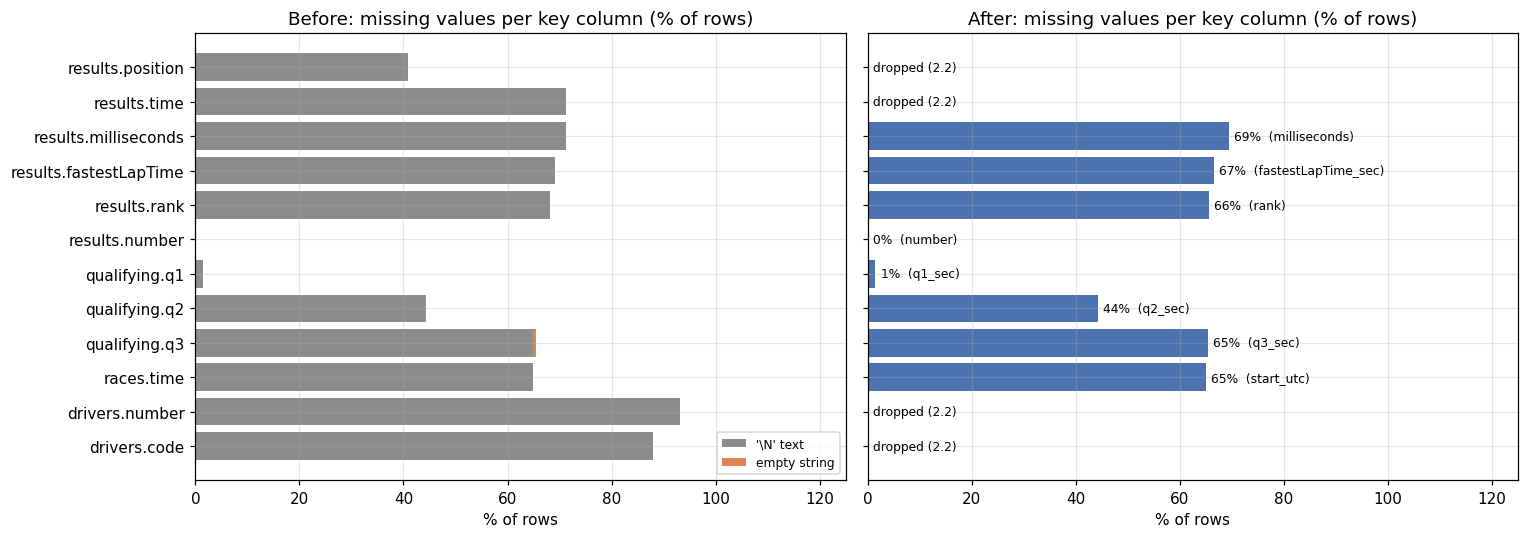

,column,raw '\N',raw empty string,raw missing %,clean column,clean NaN,clean NaN %
0,results.position,10953,0,40.9,dropped,NaN,NaN
1,results.time,19079,0,71.3,dropped,NaN,NaN
2,results.milliseconds,19079,0,71.3,milliseconds,17100.0,69.4
3,results.fastestLapTime,18507,0,69.2,fastestLapTime_sec,16393.0,66.5
4,results.rank,18249,0,68.2,rank,16156.0,65.6
5,results.number,6,0,0.0,number,0.0,0.0
6,qualifying.q1,156,0,1.5,q1_sec,157.0,1.5
7,qualifying.q2,4625,22,44.3,q2_sec,4647.0,44.3
8,qualifying.q3,6819,46,65.4,q3_sec,6865.0,65.4
9,races.time,731,0,65.0,start_utc,731.0,65.0


In [44]:
KEY_COLUMNS = [  # (table, raw column, cleaned column; None = dropped in 2.2)
    ("results", "position", None), ("results", "time", None), ("results", "milliseconds", "milliseconds"),
    ("results", "fastestLapTime", "fastestLapTime_sec"), ("results", "rank", "rank"), ("results", "number", "number"),
    ("qualifying", "q1", "q1_sec"), ("qualifying", "q2", "q2_sec"), ("qualifying", "q3", "q3_sec"),
    ("races", "time", "start_utc"), ("drivers", "number", None), ("drivers", "code", None),
]
rows = []
for t, raw_col, clean_col in KEY_COLUMNS:
    s = RAW[t][raw_col].str.strip()
    rows.append({"column": f"{t}.{raw_col}",
                 "raw '\\N'": int((s == SENTINEL).sum()), "raw empty string": int((s == "").sum()),
                 "raw rows": len(s),
                 "clean column": clean_col or "dropped",
                 "clean NaN": np.nan if clean_col is None else int(CLEAN[t][clean_col].isna().sum()),
                 "clean rows": len(CLEAN[t])})
missing_tbl = pd.DataFrame(rows)
missing_tbl["raw missing %"] = 100 * (missing_tbl["raw '\\N'"] + missing_tbl["raw empty string"]) / missing_tbl["raw rows"]
missing_tbl["clean NaN %"] = 100 * missing_tbl["clean NaN"] / missing_tbl["clean rows"]

fig, axes = before_after("missing values per key column (% of rows)", figsize=(14, 5))
y = np.arange(len(missing_tbl))
sent_pct = 100 * missing_tbl["raw '\\N'"] / missing_tbl["raw rows"]
empty_pct = 100 * missing_tbl["raw empty string"] / missing_tbl["raw rows"]
axes[0].barh(y, sent_pct, color=BEFORE_COLOR, label="'\\N' text")
axes[0].barh(y, empty_pct, left=sent_pct, color="#DD8452", label="empty string")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].barh(y, missing_tbl["clean NaN %"].fillna(0), color=AFTER_COLOR, label="NaN")
for yy, (pct, col) in enumerate(zip(missing_tbl["clean NaN %"], missing_tbl["clean column"])):
    axes[1].text(1 if np.isnan(pct) else pct + 1, yy, "dropped (2.2)" if col == "dropped" else f"{pct:.0f}%  ({col})",
                 va="center", fontsize=8)
axes[0].set_yticks(y, missing_tbl["column"])
axes[0].invert_yaxis()
for ax in axes:
    ax.set_xlim(0, 125)
    ax.set_xlabel("% of rows")
plt.tight_layout()
plt.show()
display(missing_tbl[["column", "raw '\\N'", "raw empty string", "raw missing %", "clean column", "clean NaN", "clean NaN %"]].round(1))

**Missing values:** before cleaning, pandas sees **none** of these gaps because they are the text `\N` (or an empty string in 68 `q2`/`q3` cells); after cleaning they are real `NaN` (for `qualifying` and `races` the counts are identical, plus the 1002.6 s Q1 lap set to NaN), sparse columns like `drivers.number/code` and `results.position/time` are dropped, and the `results` percentages fall slightly because non-starters, who had no times, were removed.

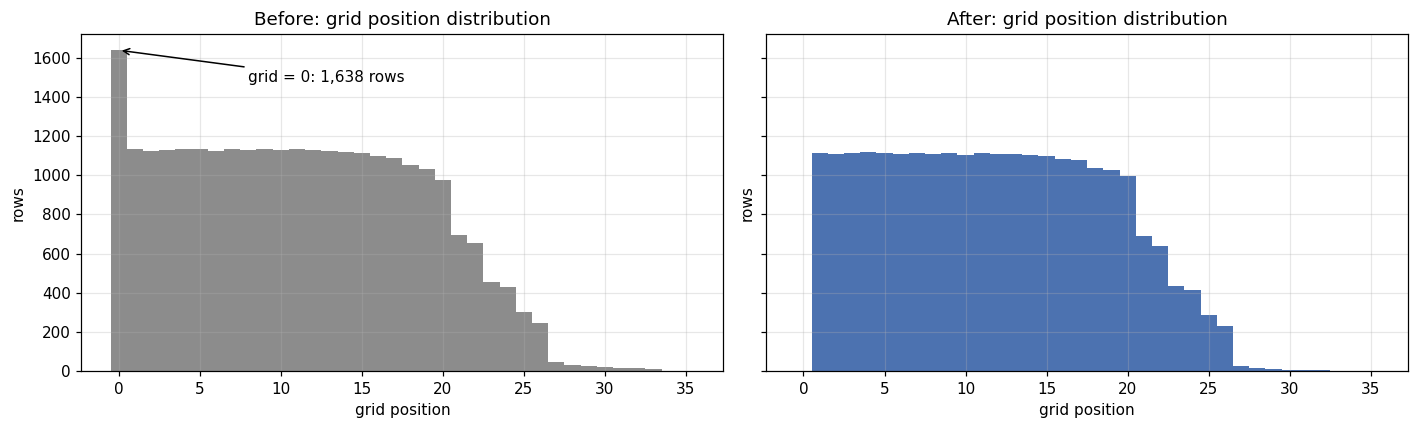

grid = 0 rows: 1,638 before, 0 after; pit-lane starters recoded and flagged: 72


In [45]:
fig, axes = before_after("grid position distribution")
bins = np.arange(-0.5, 36.5, 1)
axes[0].hist(raw_res["grid"], bins=bins, color=BEFORE_COLOR)
axes[1].hist(results_full["grid"].astype(int), bins=bins, color=AFTER_COLOR)
n_zero = int((raw_res["grid"] == 0).sum())
axes[0].annotate(f"grid = 0: {n_zero:,} rows", xy=(0, n_zero), xytext=(8, n_zero * 0.9), arrowprops={"arrowstyle": "->"})
for ax in axes:
    ax.set_xlabel("grid position")
    ax.set_ylabel("rows")
plt.tight_layout()
plt.show()
print(f"grid = 0 rows: {n_zero:,} before, {int((results_full['grid'] == 0).sum())} after; "
      f"pit-lane starters recoded and flagged: {int(results_full['pit_lane_start'].sum())}")

**Grid:** the spike of 1,638 rows at `grid = 0` is gone: 1,566 of them were non-starters and were removed, and the 72 pit-lane starters now sit behind the last car of their race (with `pit_lane_start = True`), so `grid` is a clean ordinal feature where 1 is always the best.

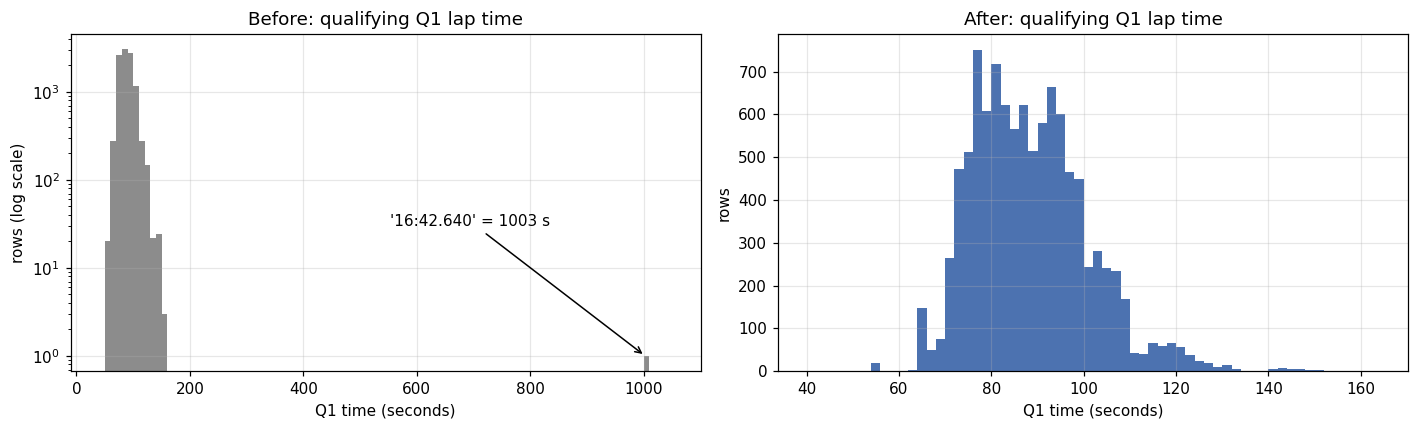

Q1 range before: 53.9-1002.6 s; after: 53.9-153.9 s


In [46]:
q1_raw = RAW["qualifying"]["q1"].map(duration_to_seconds)   # '\N' and '' parse to NaN
q1_clean = CLEAN["qualifying"]["q1_sec"]
outlier = RAW["qualifying"].loc[q1_raw.idxmax()]
fig, axes = before_after("qualifying Q1 lap time", sharey=False)
axes[0].hist(q1_raw.dropna(), bins=np.arange(40, 1060, 10), color=BEFORE_COLOR)
axes[0].set_yscale("log")
axes[0].annotate(f"'{outlier['q1']}' = {q1_raw.max():.0f} s", xy=(q1_raw.max(), 1), xytext=(q1_raw.max() - 450, 30),
                 arrowprops={"arrowstyle": "->"})
axes[1].hist(q1_clean.dropna(), bins=np.arange(40, 165, 2), color=AFTER_COLOR)
axes[0].set_ylabel("rows (log scale)")
axes[1].set_ylabel("rows")
for ax in axes:
    ax.set_xlabel("Q1 time (seconds)")
plt.tight_layout()
plt.show()
print(f"Q1 range before: {q1_raw.min():.1f}-{q1_raw.max():.1f} s; after: {q1_clean.min():.1f}-{q1_clean.max():.1f} s")

**Q1 times:** before cleaning, one Q1 time of `16:42.640` (1002.6 s, Japan 1995) stretches the range to over 16 minutes; after setting it to NaN (2.7) every Q1 time lies between 53.9 and 153.9 s, a plausible range for a flying lap.

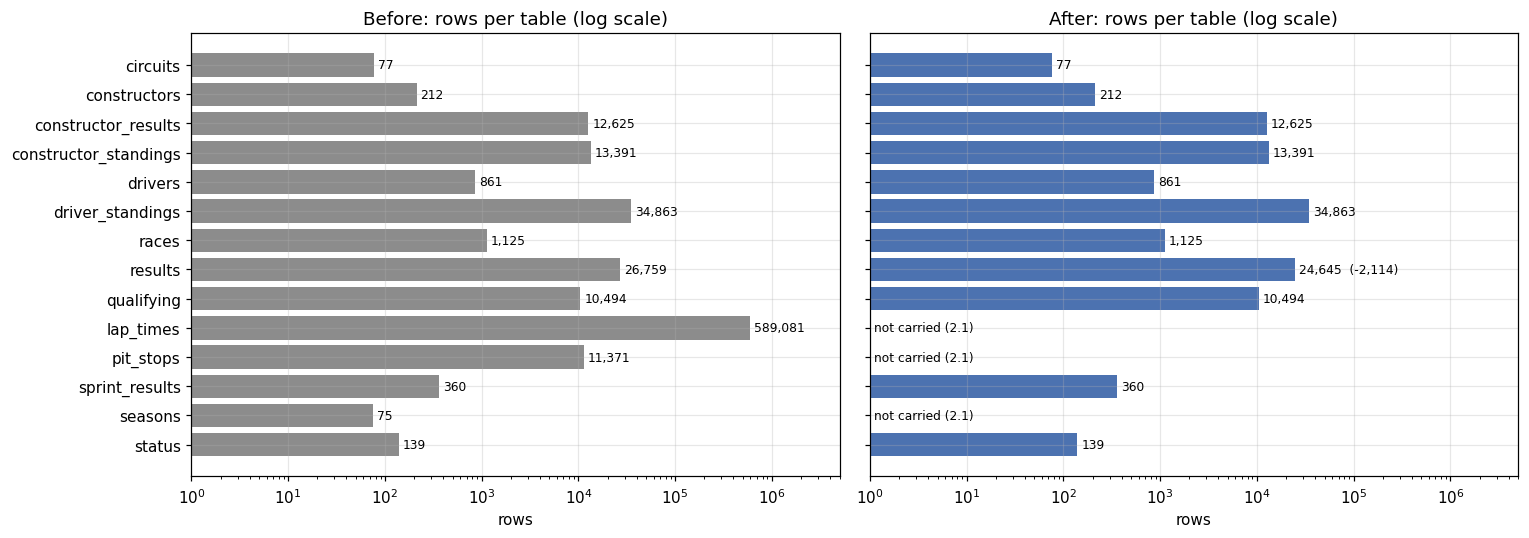

,raw rows,clean rows,removed,note
circuits,77,77,0,
constructors,212,212,0,
constructor_results,12625,12625,0,"cleaned, not used (2.1)"
constructor_standings,13391,13391,0,
drivers,861,861,0,
driver_standings,34863,34863,0,
races,1125,1125,0,
results,26759,24645,2114,
qualifying,10494,10494,0,
lap_times,589081,0,589081,not carried (2.1)


,step,table,rows before,rows after,rows removed,note
0,remove non-starters,results,26759,25114,1645,"non-start status with 0 laps, or grid = 0 with 0 laps"
1,rule B: one row per driver per race,results,25114,25026,88,88 extra rows
2,remove Indianapolis 500 (1950-1960),results,25026,24645,381,"separate US race in the championship: own drivers, 33-ca..."
3,modeling window 2003+,model_base,24645,8934,15711,qualifying coverage ~100% from 2003


In [47]:
rows_tbl = pd.DataFrame({"raw rows": {t: len(RAW[t]) for t in TABLES},
                         "clean rows": {t: len(CLEAN[t]) if t in CLEAN else 0 for t in TABLES}})
rows_tbl["removed"] = rows_tbl["raw rows"] - rows_tbl["clean rows"]
rows_tbl["note"] = ["not carried (2.1)" if t in UNUSED_TABLES else ("cleaned, not used (2.1)" if t in DEFERRED_TABLES else "")
                    for t in rows_tbl.index]

fig, axes = before_after("rows per table (log scale)", figsize=(14, 5))
y = np.arange(len(rows_tbl))
axes[0].barh(y, rows_tbl["raw rows"], color=BEFORE_COLOR)
axes[1].barh(y, rows_tbl["clean rows"].replace(0, np.nan), color=AFTER_COLOR)
for yy, (t, r) in enumerate(rows_tbl.iterrows()):
    axes[0].text(r["raw rows"] * 1.1, yy, f"{r['raw rows']:,}", va="center", fontsize=8)
    label = r["note"] if t in UNUSED_TABLES else f"{r['clean rows']:,}" + (f"  (-{r['removed']:,})" if r["removed"] else "")
    axes[1].text(max(r["clean rows"], 1) * 1.1, yy, label, va="center", fontsize=8)
axes[0].set_yticks(y, rows_tbl.index)
axes[0].invert_yaxis()
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlim(1, 5e6)
    ax.set_xlabel("rows")
plt.tight_layout()
plt.show()
display(rows_tbl)
display(pd.DataFrame(cleaning_log))

**Rows per table:** only `results` loses rows (26,759 → 24,645: 1,645 non-starters, 88 duplicate rows and 381 Indianapolis 500 rows, see the step table); `seasons`, `lap_times` and `pit_stops` are not carried, and every other table keeps all its rows (only values and types changed).

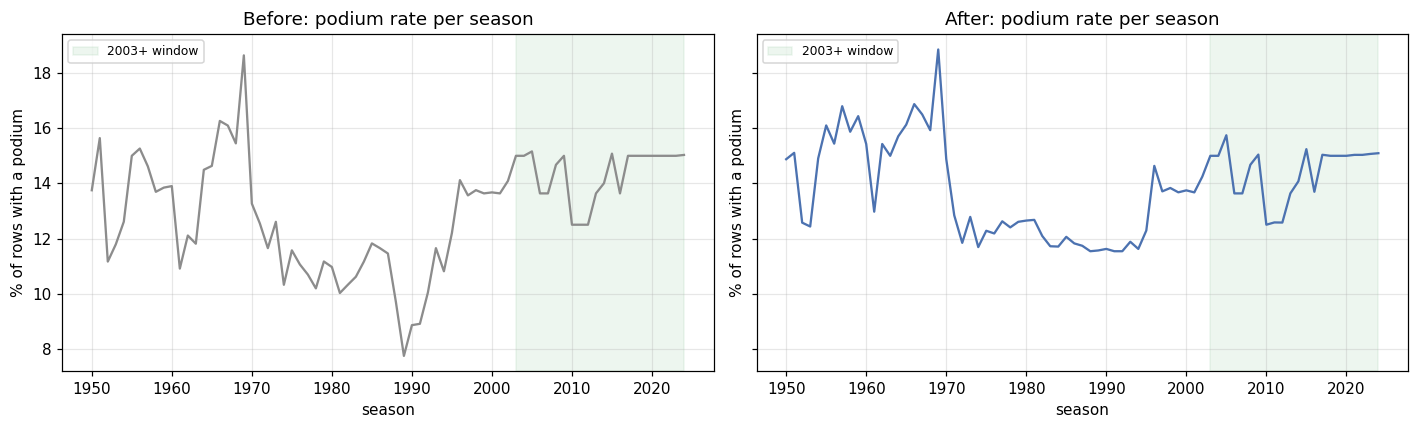

In [48]:
fig, axes = before_after("podium rate per season")
for ax, df, color in [(axes[0], raw_res, BEFORE_COLOR), (axes[1], results_full, AFTER_COLOR)]:
    rate = 100 * df.groupby("year")["podium"].mean()
    ax.plot(rate.index, rate.values, color=color)
    ax.axvspan(MODEL_START_YEAR, 2024, color="#55A868", alpha=0.1, label="2003+ window")
    ax.set_xlabel("season")
    ax.set_ylabel("% of rows with a podium")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Podium rate per season:** before cleaning, seasons with many non-qualifiers (late 1980s, as low as ~8%) look artificially weak because cars that never started sit in the denominator; after cleaning the rate follows 3 ÷ number of starters (about 11.5–19%), and inside the 2003+ window it barely changes, so the modeling data was mostly clean already.

## 2.12 Raw data still untouched

In [49]:
after = {t: hashlib.sha256(read_raw_bytes(t)).hexdigest() for t in TABLES}
assert all(after[t] == RAW_FINGERPRINT[t] for t in TABLES), "A raw file changed during cleaning!"
print(f"All {len(TABLES)} raw files are still byte-identical after cleaning (SHA-256).")

All 14 raw files are still byte-identical after cleaning (SHA-256).


## 2.13 Export: the cleaned dataset

The cleaned tables are written to `outputs/clean_data/`, so the next steps (and teammates) can start from them without re-running the cleaning. The raw files are not touched: these are new files.
- **One CSV per table**, missing values written as empty cells.
- **`schema.json`**: the type of every column. CSV loses types (e.g. nullable integers, dates), so `load_clean()` below uses it to restore them exactly.
- **`manifest.csv`**: rows, columns and SHA-256 of every file, so anyone can check they have the same data.
- **`README.md`**: what each file is, its key, and what cleaning did to it.

The code reads every file back and checks it is **identical** to the in-memory table (values and types).

In [50]:
import json

CLEAN_DATA_DIR = Path("outputs/clean_data")
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

# file -> (table, key, description)
EXPORT = {
    "model_base": (model_base, "raceId + driverId",
                   "Modeling base, 2003+: one row per driver per race, pre-race columns + target `podium` only."),
    "results_full": (results_full, "raceId + driverId",
                     "All cleaned driver-races 1950-2024 (no Indianapolis 500), with race info and post-race columns. "
                     "Used by the data-engineering questions. Post-race columns are never features."),
    "results": (CLEAN["results"], "resultId (and raceId + driverId)",
                "Cleaned results: target, non-starters removed, rule B, pit-lane grid recode, status + category."),
    "qualifying": (CLEAN["qualifying"], "qualifyId (and raceId + driverId)",
                   "q1/q2/q3 as seconds (`*_sec`); empty strings and the 1002.6 s outlier are NaN. Missing q2/q3 = knocked out."),
    "races": (CLEAN["races"], "raceId", "date as a date; start_utc where the start time is recorded (2005+)."),
    "drivers": (CLEAN["drivers"], "driverId", "dob as a date; nationality fixed; home_country for Q2."),
    "constructors": (CLEAN["constructors"], "constructorId", "Teams."),
    "circuits": (CLEAN["circuits"], "circuitId", "'United States' merged into 'USA'."),
    "status": (CLEAN["status"], "statusId", "status_category: finished / mechanical / accident / regulation / driver / unclear."),
    "driver_standings": (CLEAN["driver_standings"], "driverStandingsId (and raceId + driverId)",
                         "Standings AFTER each race (post-race, leakage!). Use driver_standings_prerace for features."),
    "constructor_standings": (CLEAN["constructor_standings"], "constructorStandingsId (and raceId + constructorId)",
                              "Standings AFTER each race (post-race, leakage!). Use constructor_standings_prerace for features."),
    "driver_standings_prerace": (CLEAN["driver_standings_prerace"], "raceId + driverId",
                                 "Leakage-safe: standings after the previous round, keyed by the race being predicted. Round 1 has no row."),
    "constructor_standings_prerace": (CLEAN["constructor_standings_prerace"], "raceId + constructorId",
                                      "Leakage-safe: standings after the previous round, keyed by the race being predicted. Round 1 has no row."),
    "sprint_results": (CLEAN["sprint_results"], "resultId (and raceId + driverId)",
                       "Cleaned but not used yet (optional feature later)."),
    "constructor_results": (CLEAN["constructor_results"], "constructorResultsId", "Cleaned but not used."),
}

schema, manifest = {}, []
for name, (df, key, desc) in EXPORT.items():
    path = CLEAN_DATA_DIR / f"{name}.csv"
    df.to_csv(path, index=False)   # dates without a time are written as YYYY-MM-DD
    schema[name] = {c: str(d) for c, d in df.dtypes.items()}
    manifest.append({"file": path.name, "rows": len(df), "columns": df.shape[1], "key": key, "description": desc,
                     "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
(CLEAN_DATA_DIR / "schema.json").write_text(json.dumps(schema, indent=1), encoding="utf-8")
manifest = pd.DataFrame(manifest)
manifest.to_csv(CLEAN_DATA_DIR / "manifest.csv", index=False)


def load_clean(name, folder=CLEAN_DATA_DIR):
    """Read one exported table back with its original column types."""
    types = json.loads((Path(folder) / "schema.json").read_text(encoding="utf-8"))[name]
    dates = [c for c, t in types.items() if t.startswith("datetime")]
    df = pd.read_csv(Path(folder) / f"{name}.csv", dtype={c: t for c, t in types.items() if c not in dates},
                     parse_dates=dates, keep_default_na=False, na_values=[""],
                     float_precision="round_trip")   # the default fast parser can be off in the last digit
    for c in dates:
        df[c] = df[c].astype(types[c])
    return df


# Round trip: every file must read back identical to the in-memory table.
for name, (df, _, _) in EXPORT.items():
    pd.testing.assert_frame_equal(load_clean(name), df.reset_index(drop=True), check_exact=True)
print(f"{len(EXPORT)} tables written to {CLEAN_DATA_DIR}/ and read back identical (values and types).")
display(manifest[["file", "rows", "columns", "key"]])

15 tables written to outputs\clean_data/ and read back identical (values and types).


,file,rows,columns,key
0,model_base.csv,8934,10,raceId + driverId
1,results_full.csv,24645,24,raceId + driverId
2,results.csv,24645,19,resultId (and raceId + driverId)
3,qualifying.csv,10494,8,qualifyId (and raceId + driverId)
4,races.csv,1125,7,raceId
5,drivers.csv,861,7,driverId
6,constructors.csv,212,4,constructorId
7,circuits.csv,77,4,circuitId
8,status.csv,139,3,statusId
9,driver_standings.csv,34863,6,driverStandingsId (and raceId + driverId)


In [51]:
lines = ["# Cleaned F1 dataset", "",
         "Written by section 2.13 of `f1_podium_prediction.ipynb` (do not edit by hand; re-run the notebook instead).",
         "Raw source: Kaggle / Ergast *Formula 1 World Championship (1950-2024)*. The raw CSVs are unchanged.", "",
         "Load a table with its original types (nullable integers, dates):", "",
         "```python", "df = load_clean(\"model_base\")   # defined in section 2.13 of the notebook", "```",
         "or with plain pandas: `pd.read_csv(path, keep_default_na=False, na_values=[\"\"], float_precision=\"round_trip\")`, "
         "then apply the types in `schema.json`.", "",
         "## Files", "", "| file | rows | key | what it is |", "|---|---|---|---|"]
lines += [f"| `{r.file}` | {r.rows:,} | {r.key} | {r.description} |" for r in manifest.itertuples()]
lines += ["", "## What cleaning did (details in notebook section 2)", "",
          "- `\\N` and empty strings -> missing values; text stripped; columns typed (IDs/counts integer, points float, dates as dates, lap times as seconds).",
          "- `results`: target `podium = positionOrder <= 3` created first; 1,645 non-starters removed; one row per (raceId, driverId) by rule B "
          "(lowest resultId as a proxy for the starting car, 3 verified overrides); `grid = 0` pit-lane starts -> last slot + 1 with `pit_lane_start`; "
          "the Indianapolis 500 (1950-1960, 381 rows) removed.",
          "- `qualifying`: times in seconds; the 1002.6 s Q1 lap set to missing.",
          "- Labels: 'Argentinian ' -> 'Argentine', 'United States' -> 'USA', `drivers.home_country` added; every status has a category.",
          "- `*_prerace` standings: leakage-safe standings from the previous round.",
          "- Not exported: `seasons`, `lap_times`, `pit_stops` (not used).", "",
          "**Leakage reminder:** post-race columns (`positionOrder`, `points`, `laps`, `status*`, `milliseconds`, `fastestLap*`, `rank`) "
          "and the non-prerace standings must never be used as features."]
(CLEAN_DATA_DIR / "README.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("README.md written:", len(lines), "lines")

README.md written: 42 lines


**What this did.** The cleaned dataset now exists as files in `outputs/clean_data/`: 15 CSVs, plus `schema.json`, `manifest.csv` and a `README.md` describing each file. Reading every file back gives exactly the in-memory tables, so later sections (or a teammate) can start from `load_clean("model_base")` instead of re-running the cleaning. The files are rewritten on every run, so they always match the notebook.

# 3. Data-Engineering Questions

Each question is answered from the **cleaned dataset files** in `outputs/clean_data/` (written in 2.13), read back with `load_clean()`, using multi-table joins. The questions don't use the in-memory tables, so they show that the exported files alone are enough. For every question we state:
- **Tables & joins:** which tables are combined, and on which keys.
- **Grain:** what one row represents.
- **Missingness:** what is missing and how it is handled.
- **Cutoff:** whether the pre-race cutoff matters.

Then come the result, a plot, and a plain-language answer.

In [52]:
# Section 3 reads the cleaned dataset from its files (written in 2.13), not from the in-memory tables.
CLEAN_DIR_CANDIDATES = [os.environ.get("F1_CLEAN"), str(CLEAN_DATA_DIR),
                        *map(str, Path("/kaggle/input").glob("*/clean_data"))]
QA_CLEAN_DIR = next(Path(c) for c in filter(None, CLEAN_DIR_CANDIDATES)
                    if (Path(c) / "results_full.csv").exists())
print("Cleaned data source:", QA_CLEAN_DIR.resolve())

results_full_c = load_clean("results_full", QA_CLEAN_DIR)
races_c = load_clean("races", QA_CLEAN_DIR)
qualifying_c = load_clean("qualifying", QA_CLEAN_DIR)
drivers_c = load_clean("drivers", QA_CLEAN_DIR)
circuits_c = load_clean("circuits", QA_CLEAN_DIR)[["circuitId", "name", "country"]].rename(columns={"name": "circuit"})
constructors_c = (load_clean("constructors", QA_CLEAN_DIR)[["constructorId", "name"]]
                  .rename(columns={"name": "constructor"}))
race_info_c = races_c[["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})
quali_pos = qualifying_c[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})

# Checks on what we loaded: keys unique and non-null, and every foreign key found.
for name, df, key in [("results_full", results_full_c, ["raceId", "driverId"]), ("races", races_c, ["raceId"]),
                      ("qualifying", qualifying_c, ["raceId", "driverId"]), ("drivers", drivers_c, ["driverId"]),
                      ("circuits", circuits_c, ["circuitId"]), ("constructors", constructors_c, ["constructorId"])]:
    assert df[key].notna().all().all() and not df.duplicated(key).any(), name
for col, parent in [("circuitId", circuits_c), ("driverId", drivers_c), ("constructorId", constructors_c)]:
    assert results_full_c[col].isin(parent[col]).all(), col
assert results_full_c["raceId"].isin(races_c["raceId"]).all()
assert results_full_c["status_category"].notna().all()

display(pd.DataFrame({"rows": [len(results_full_c), len(races_c), len(qualifying_c), len(drivers_c),
                               len(circuits_c), len(constructors_c)]},
                     index=["results_full", "races", "qualifying", "drivers", "circuits", "constructors"]))

Cleaned data source: D:\semster 9\ACL Project\ACL-2\outputs\clean_data


,rows
results_full,24645
races,1125
qualifying,10494
drivers,861
circuits,77
constructors,212


## 3.1 Q1: Which circuits convert a front-row start into a podium most often, and did that change in the hybrid era (2014+)?

**In simple words:** if a driver starts in the first two places, how often does he finish in the top three, and at which tracks is that most likely?

- **Tables & joins:** `clean_data/results_full.csv` (grid, podium, circuit, year) ⟶ `clean_data/qualifying.csv` on `raceId + driverId` (qualifying position) ⟶ `clean_data/circuits.csv` on `circuitId` (circuit name).
- **Grain:** one row = one driver in one race.
- **Two definitions of "front row"**, because they differ (penalties):
  - **started** on the front row = `grid` 1 or 2 (the main answer: it's where the car actually lined up);
  - **qualified** on the front row = qualifying position 1 or 2 (shown for comparison).
- **Missingness:** qualifying is complete only from 2003 (1.7), so the comparison is **2003–2013 (pre-hybrid) vs 2014–2024 (hybrid)**. Circuits need **≥ 8 front-row starts in each era** (about 4 races) so a single race doesn't decide the ranking.
- **Cutoff:** grid and qualifying are known before the race, so both are valid "starting" information.

In [53]:
ERAS = ["2003-2013 (pre-hybrid)", "2014-2024 (hybrid)"]
q1 = (results_full_c[results_full_c["year"] >= 2003]
      .merge(quali_pos, on=["raceId", "driverId"], how="left", validate="one_to_one")
      .merge(circuits_c, on="circuitId", how="left", validate="many_to_one"))
q1["era"] = np.where(q1["year"] >= 2014, ERAS[1], ERAS[0])

started_fr = q1[q1["grid"] <= 2]
qualified_fr = q1[q1["quali_pos"] <= 2]
print(f"Front-row qualifiers who did NOT start on the front row (penalties): {int((qualified_fr['grid'] > 2).sum())}")
print(f"Front-row starters who did NOT qualify on the front row (moved up):  {int((started_fr['quali_pos'] > 2).sum())}")

overall = pd.DataFrame({
    "front-row starts": started_fr.groupby("era").size(),
    "podium % (started front row)": (100 * started_fr.groupby("era")["podium"].mean()).round(1),
    "podium % (qualified front row)": (100 * qualified_fr.groupby("era")["podium"].mean()).round(1),
})
display(overall)

MIN_STARTS = 8
by_start = started_fr.groupby(["circuit", "era"])["podium"].agg(["size", "mean"]).unstack("era")
by_quali = qualified_fr.groupby(["circuit", "era"])["podium"].mean().unstack("era")
keep = (by_start["size"].reindex(columns=ERAS) >= MIN_STARTS).all(axis=1)

rates = (100 * by_start["mean"].loc[keep, ERAS]).round(1)
q1_table = pd.concat({
    "podium % (started FR)": rates,
    "rank": rates.rank(ascending=False, method="min").astype(int),
    "podium % (qualified FR)": (100 * by_quali.loc[keep, ERAS]).round(1),
    "front-row starts": by_start["size"].loc[keep, ERAS].astype(int),
}, axis=1).sort_values(("podium % (started FR)", ERAS[1]), ascending=False)
display(q1_table)

rank_corr = rates[ERAS[0]].corr(rates[ERAS[1]], method="spearman")
print(f"{keep.sum()} circuits compared. Rank correlation between eras (Spearman): {rank_corr:.2f}  (1 = same order, 0 = unrelated)")

Front-row qualifiers who did NOT start on the front row (penalties): 36
Front-row starters who did NOT qualify on the front row (moved up):  36


,front-row starts,podium % (started front row),podium % (qualified front row)
era,,,
2003-2013 (pre-hybrid),398,68.3,67.6
2014-2024 (hybrid),454,76.0,74.0


podium % (started FR)                                      rank                    podium % (qualified FR)                          front-row starts                   
era                            2003-2013 (pre-hybrid) 2014-2024 (hybrid) 2003-2013 (pre-hybrid) 2014-2024 (hybrid)  2003-2013 (pre-hybrid) 2014-2024 (hybrid) 2003-2013 (pre-hybrid) 2014-2024 (hybrid)
circuit                                                                                                                                                                                                
Suzuka Circuit                                   72.2               88.9                      4                  1                    72.2               88.9                     18                 18
Yas Marina Circuit                               60.0               86.4                     12                  2                    60.0               81.8                     10                 22
Circuit de Monaco                                77.3               85.0                      1                  3                    68.2               85.0                     22                 20
Circuit de Barcelona-Catalunya                   68.2               81.8                      7                  4                    63.6               81.8                     22                 22
Circuit de Spa-Francorchamps                     72.2               81.8                      4                  4                    72.2               81.8                     18                 22
Autódromo José Carlos Pace                       59.1               78.9                     14                  6                    59.1               68.4                     22                 19
Shanghai International Circuit                   65.0               78.6                      9                  7                    70.0               78.6                     20                 14
Circuit Gilles Villeneuve                        60.0               77.8                     12                  8                    60.0               72.2                     20                 18
Silverstone Circuit                              72.7               75.0                      3                  9                    77.3               75.0                     22                 24
Autodromo Enzo e Dino Ferrari                    62.5               75.0                     11                  9                    62.5               62.5                      8                  8
Autodromo Nazionale di Monza                     77.3               72.7                      1                 11                    72.7               72.7                     22                 22
Albert Park Grand Prix Circuit                   59.1               72.2                     14                 12                    59.1               72.2                     22                 18
Marina Bay Street Circuit                        58.3               72.2                     16                 12                    58.3               72.2                     12                 18
Bahrain International Circuit                    66.7               66.7                      8                 14                    66.7               66.7                     18                 24
Hockenheimring                                   71.4               62.5                      6                 15                    71.4               62.5                     14                  8
Hungaroring                                      63.6               59.1                     10                 16                    59.1               59.1                     22                 22

16 circuits compared. Rank correlation between eras (Spearman): 0.21  (1 = same order, 0 = unrelated)


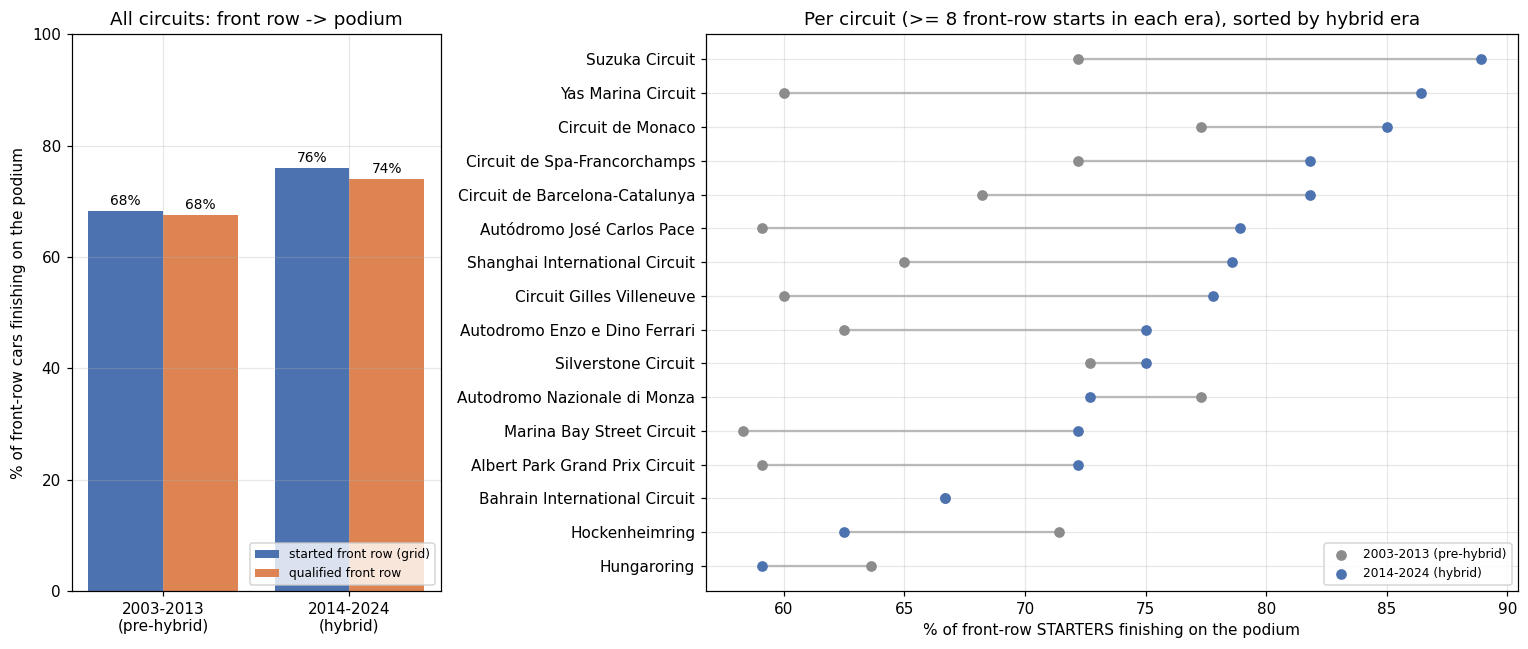

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 2.2]})

x = np.arange(len(ERAS))
axes[0].bar(x - 0.2, overall["podium % (started front row)"], 0.4, label="started front row (grid)", color="#4C72B0")
axes[0].bar(x + 0.2, overall["podium % (qualified front row)"], 0.4, label="qualified front row", color="#DD8452")
for i, (a, b) in enumerate(zip(overall["podium % (started front row)"], overall["podium % (qualified front row)"])):
    axes[0].text(i - 0.2, a + 1, f"{a:.0f}%", ha="center", fontsize=9)
    axes[0].text(i + 0.2, b + 1, f"{b:.0f}%", ha="center", fontsize=9)
axes[0].set_xticks(x, [e.replace(" (", "\n(") for e in ERAS])
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("% of front-row cars finishing on the podium")
axes[0].set_title("All circuits: front row -> podium")
axes[0].legend(fontsize=8, loc="lower right")

plot_rates = rates.sort_values(ERAS[1])
y = np.arange(len(plot_rates))
axes[1].hlines(y, plot_rates[ERAS[0]], plot_rates[ERAS[1]], color="#BBBBBB", zorder=1)
axes[1].scatter(plot_rates[ERAS[0]], y, color="#8C8C8C", label=ERAS[0], zorder=2)
axes[1].scatter(plot_rates[ERAS[1]], y, color="#4C72B0", label=ERAS[1], zorder=3)
axes[1].set_yticks(y, plot_rates.index)
axes[1].set_xlabel("% of front-row STARTERS finishing on the podium")
axes[1].set_title(f"Per circuit (>= {MIN_STARTS} front-row starts in each era), sorted by hybrid era")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Answer to Q1.**
- **Overall:** a front-row start turns into a podium about **7 times out of 10**. It became **more reliable in the hybrid era** (≈ 68% → 76%): with dominant teams and more reliable cars, the drivers at the front usually stay there.
- **Most "converting" circuits in the hybrid era:** **Suzuka, Yas Marina (Abu Dhabi) and Monaco** (≈ 85–89%). Monaco makes sense because overtaking there is almost impossible.
- **Before 2014** the top three were **Monaco, Monza and Silverstone**.
- **The ranking did change a lot:** the rank correlation between the two eras is only about **0.2**, so a circuit's position in the list before 2014 says little about its position after. Monza and Hockenheim dropped, and Yas Marina and Interlagos rose sharply. Monaco stays near the top in both.
- **Qualifying position vs grid:** 36 front-row qualifiers started further back (grid penalties), and 36 others were promoted onto the front row. Counting by qualifying instead of grid changes the overall rate only slightly (71% vs 72%), but it changes some individual circuits, which is why both columns are shown.

*Caution:* each circuit has only ~10–24 front-row starts per era, so one race can move a circuit's rate by 5–10 points. Treat close rankings as ties.

### 3.1.1 Robustness check: starting position only, all seasons (1950–2024)

`grid` exists for every season, so Q1 could be answered from grid alone, with "before 2014" meaning **1950–2013** instead of 2003–2013.
Does that give a different (or better) answer?

Front-row conversion 1950-2013: 56.0%  vs 2003-2013: 68.3%
Rank correlation, 1950-2013 vs hybrid era: -0.07
Rank correlation between the two 'pre-2014' versions (16 common circuits): -0.14


**Top 5 circuits before 2014, under each definition**

,"1950-2013 (grid only, all years)",2003-2013 (main answer)
0,Suzuka Circuit,Autodromo Nazionale di Monza
1,Hungaroring,Circuit de Monaco
2,Bahrain International Circuit,Silverstone Circuit
3,Circuit de Barcelona-Catalunya,Circuit de Spa-Francorchamps
4,Shanghai International Circuit,Suzuka Circuit


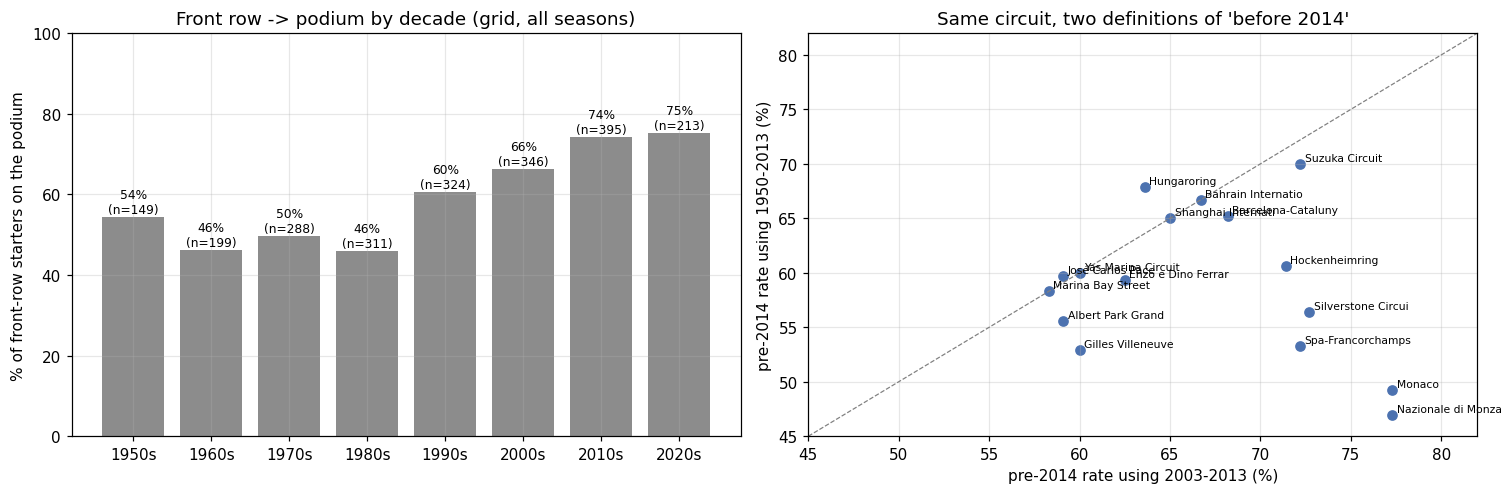

In [55]:
ERAS_ALL = ["1950-2013 (all pre-hybrid)", "2014-2024 (hybrid)"]
q1_all = results_full_c.merge(circuits_c, on="circuitId", how="left", validate="many_to_one")
q1_all["era"] = np.where(q1_all["year"] >= 2014, ERAS_ALL[1], ERAS_ALL[0])
fr_all = q1_all[q1_all["grid"] <= 2]

by_decade = fr_all.assign(decade=fr_all["year"] // 10 * 10).groupby("decade")["podium"].agg(["size", "mean"])
by_all = fr_all.groupby(["circuit", "era"])["podium"].agg(["size", "mean"]).unstack("era")
keep_all = (by_all["size"].reindex(columns=ERAS_ALL) >= MIN_STARTS).all(axis=1)
rates_all = (100 * by_all["mean"].loc[keep_all, ERAS_ALL]).round(1)

pre_compare = pd.concat({"pre-2014 = 1950-2013": rates_all[ERAS_ALL[0]],
                         "pre-2014 = 2003-2013": rates[ERAS[0]]}, axis=1).dropna()
print(f"Front-row conversion 1950-2013: {100 * fr_all.loc[fr_all['era'] == ERAS_ALL[0], 'podium'].mean():.1f}%  "
      f"vs 2003-2013: {overall.loc[ERAS[0], 'podium % (started front row)']}%")
print(f"Rank correlation, 1950-2013 vs hybrid era: {rates_all[ERAS_ALL[0]].corr(rates_all[ERAS_ALL[1]], method='spearman'):.2f}")
print(f"Rank correlation between the two 'pre-2014' versions ({len(pre_compare)} common circuits): "
      f"{pre_compare.iloc[:, 0].corr(pre_compare.iloc[:, 1], method='spearman'):.2f}")

display(Markdown("**Top 5 circuits before 2014, under each definition**"))
display(pd.DataFrame({
    "1950-2013 (grid only, all years)": rates_all[ERAS_ALL[0]].sort_values(ascending=False).head(5).index,
    "2003-2013 (main answer)": rates[ERAS[0]].sort_values(ascending=False).head(5).index,
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].bar(by_decade.index.astype(str) + "s", 100 * by_decade["mean"], color="#8C8C8C")
for i, (v, n) in enumerate(zip(by_decade["mean"], by_decade["size"])):
    axes[0].text(i, 100 * v + 1, f"{100 * v:.0f}%\n(n={n})", ha="center", fontsize=8)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("% of front-row starters on the podium")
axes[0].set_title("Front row -> podium by decade (grid, all seasons)")

axes[1].scatter(pre_compare.iloc[:, 1], pre_compare.iloc[:, 0], color="#4C72B0")
for name, (v_all, v_modern) in pre_compare.iterrows():
    short = name.replace("Circuit de ", "").replace("Circuit ", "").replace("Autodromo ", "").replace("Autódromo ", "")[:18]
    axes[1].annotate(short, (v_modern, v_all), fontsize=7, xytext=(3, 2), textcoords="offset points")
lims = [45, 82]
axes[1].plot(lims, lims, ls="--", color="grey", lw=0.8)
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_xlabel("pre-2014 rate using 2003-2013 (%)")
axes[1].set_ylabel("pre-2014 rate using 1950-2013 (%)")
axes[1].set_title("Same circuit, two definitions of 'before 2014'")
plt.tight_layout()
plt.show()

**What the robustness check shows.**
- **The conversion rate depends strongly on the decade:** about **46–54%** from the 1950s to the 1980s, rising to **74–75%** since 2010. Older cars broke down far more often, so even a front-row car often didn't finish.
- Because of this, **"before 2014" = 1950–2013 mostly measures how old a circuit is**:
  - Classic circuits (Monza, Silverstone, Monaco) carry decades of unreliable-era races, which pulls their rate down.
  - Newer circuits (Bahrain, Shanghai) only have modern races, so they look better.

  That's why the two "before 2014" rankings disagree (rank correlation about **−0.1**). The all-years version would also exaggerate the hybrid-era change (56% → 76% instead of 68% → 76%).
- **The hybrid-era (2014–2024) answer barely depends on this choice:** Suzuka, Yas Marina and Monaco stay at the top. Zandvoort also appears, because its 1950s–80s races let it pass the minimum-sample rule.
- **Decision:** the main answer keeps **2003–2013 vs 2014–2024**. Both periods are modern, comparable, and have qualifying data, which the question explicitly asks us to distinguish from grid. The all-years version is reported as a limitation: it compares eras more than circuits.

### 3.1.2 Why the qualifying table is still needed (beyond the brief asking for it)

Grid is the starting position, so it's the primary measure. The question is whether **qualifying adds information that grid hides**.

Since 2003, grid differs from qualifying position in 27% of rows.


,podium %
"qualified top 3, started 6th+ (n=47)",31.9
others starting from the same slots (n=5084),3.4


,faster half,slower half,n
grid,,,
2,69.5,60.8,425
3,50.9,51.2,427
4,37.4,27.7,427
5,26.6,15.0,428


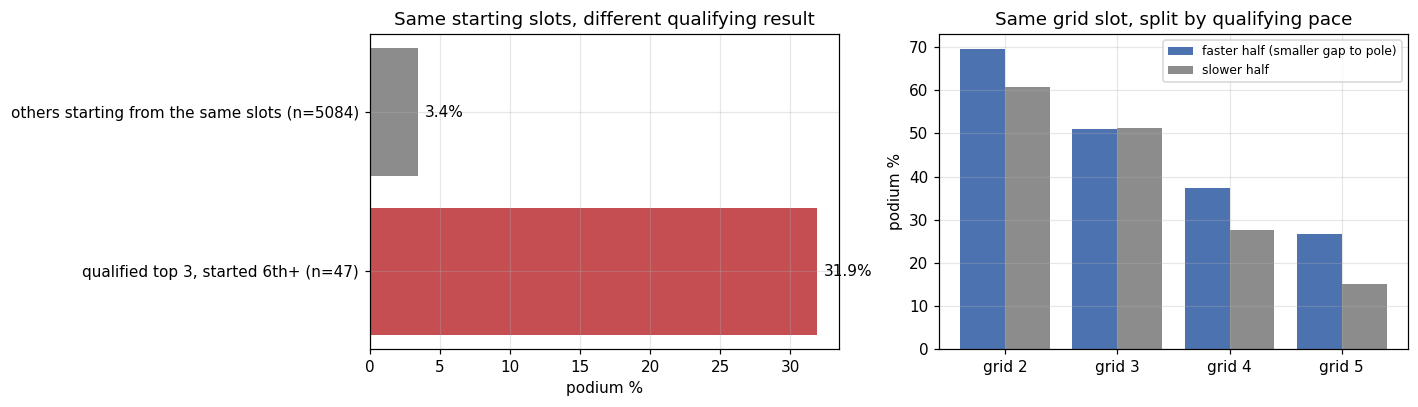

In [56]:
q_best = qualifying_c[["raceId", "driverId", "position", "q1_sec", "q2_sec", "q3_sec"]].copy()
q_best["best_sec"] = q_best[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
q_best["gap_to_pole_pct"] = 100 * (q_best["best_sec"] / q_best.groupby("raceId")["best_sec"].transform("min") - 1)
qg = results_full_c[results_full_c["year"] >= 2003].merge(q_best[["raceId", "driverId", "position", "gap_to_pole_pct"]],
                                                      on=["raceId", "driverId"], how="left", validate="one_to_one")
print(f"Since 2003, grid differs from qualifying position in {100 * (qg['grid'] != qg['position'])[qg['position'].notna()].mean():.0f}% of rows.")

# (1) Penalised fast cars: qualified top 3, started 6th or worse
penalised = qg[(qg["position"] <= 3) & (qg["grid"] >= 6)]
same_slots = qg[qg["grid"].isin(penalised["grid"].unique()) & (qg["position"] > 3)]
penalty_view = pd.Series({
    f"qualified top 3, started 6th+ (n={len(penalised)})": 100 * penalised["podium"].mean(),
    f"others starting from the same slots (n={len(same_slots)})": 100 * same_slots["podium"].mean(),
}).round(1)

# (2) Same grid slot, faster vs slower half by gap to pole
gap_rows = []
for slot in [2, 3, 4, 5]:
    s = qg[(qg["grid"] == slot) & qg["gap_to_pole_pct"].notna()]
    fast = s["gap_to_pole_pct"] <= s["gap_to_pole_pct"].median()
    gap_rows.append({"grid": slot, "faster half": 100 * s.loc[fast, "podium"].mean(),
                     "slower half": 100 * s.loc[~fast, "podium"].mean(), "n": len(s)})
gap_view = pd.DataFrame(gap_rows).set_index("grid").round(1)
display(penalty_view.to_frame("podium %"))
display(gap_view)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(penalty_view.index, penalty_view.values, color=["#C44E52", "#8C8C8C"])
for i, v in enumerate(penalty_view.values):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va="center")
axes[0].set_xlabel("podium %")
axes[0].set_title("Same starting slots, different qualifying result")
x = np.arange(len(gap_view))
axes[1].bar(x - 0.2, gap_view["faster half"], 0.4, label="faster half (smaller gap to pole)", color="#4C72B0")
axes[1].bar(x + 0.2, gap_view["slower half"], 0.4, label="slower half", color="#8C8C8C")
axes[1].set_xticks(x, [f"grid {g}" for g in gap_view.index])
axes[1].set_ylabel("podium %")
axes[1].set_title("Same grid slot, split by qualifying pace")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What this shows.**
- **Penalties hide fast cars.** Drivers who qualified in the **top 3** but started **6th or worse** (grid penalties) still reached the podium about **32%** of the time. Other drivers starting from the same slots managed only about **3%**. Using grid alone, those fast cars look like midfield cars.
- **Qualifying shows how fast a car is, not just its order.** Among drivers starting from the same slot, the faster half (smaller gap to pole) reaches the podium more often from grid 2, 4 and 5 (e.g. **27% vs 15%** from grid 5). Grid 3 is the exception, with no difference. Grid is only a rank, while qualifying times measure the gap.
- **So we use both:** `grid` as the starting position (the main measure, all seasons), and qualifying for the information grid loses. Since 2003, grid and qualifying position differ in about a quarter of rows.
- **Planned modeling experiment:** *Attempt A* = grid only, all seasons vs *Attempt B* = grid + qualifying, 2003+. Both are evaluated on the same recent test seasons. If A is as good as B, the simpler data choice wins. This comparison will be reported in the modeling section.

## 3.2 Q2: Do drivers finish on the podium more often at home, once we account for where they start?

**In simple words:** a British driver at Silverstone, a Dutch driver at Zandvoort... do they do better than usual? To be fair, we must compare drivers who **started from similar places**. Otherwise "home advantage" could just mean "the home driver qualified well".

- **Tables & joins:** `clean_data/results_full.csv` ⟶ `clean_data/drivers.csv` on `driverId` (`home_country`, built in 2.4) ⟶ `clean_data/circuits.csv` on `circuitId` (`country`). **Home race** = `home_country == circuit country`.
- **Grain:** one row = one driver starting one race (all seasons; non-starters were removed in 2.6, and the Indianapolis 500 in 2.6.1).
- **Why no Indianapolis 500:** in 1950–1960 it was a separate American race. Almost every starter was an American at a US circuit (a "home" start), with no away drivers in the same race to compare with. It would have made up 16% of all home starts. The result with Indy put back is shown as a robustness column. Those rows are removed by cleaning, so they are not in the clean files: this one column takes them from memory (`INDY500_RESULTS`, 2.6.1).
- **Controlling for starting position:** drivers are grouped into **grid bands** (1–3, 4–6, 7–10, 11+). Home and away drivers are compared **inside the same band**. The band differences are then averaged, weighted by how many home starts fall in each band ("grid-adjusted difference").
- **Uncertainty:** a bootstrap (resampling the rows 500 times) gives a 95% interval for the adjusted difference.
- **Missingness:** none. Every driver has a `home_country`, and every cleaned row has a valid grid.
- **Cutoff:** grid is pre-race information, so it's a valid control.

In [57]:
nat = drivers_c[["driverId", "home_country"]]
GRID_BANDS = ["1-3", "4-6", "7-10", "11+"]


def home_table(res):
    df = (res.merge(nat, on="driverId", how="left", validate="many_to_one")
          .merge(circuits_c, on="circuitId", how="left", validate="many_to_one"))
    df["home"] = df["home_country"] == df["country"]
    df["grid_band"] = pd.cut(df["grid"].astype(float), [0, 3, 6, 10, 99], labels=GRID_BANDS)
    return df


q2 = home_table(results_full_c)
# Robustness only: put back the Indianapolis 500 rows removed in 2.6.1.
q2_with_indy = home_table(pd.concat([results_full_c, INDY500_RESULTS.merge(race_info_c, on="raceId", how="left")]))


def adjusted_home_diff(df):
    """Home minus away podium rate inside each grid band, averaged with weights = home starts per band."""
    t = df.groupby(["grid_band", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home")
    diff = t[("mean", True)] - t[("mean", False)]
    weights = t[("size", True)]
    return (diff * weights).sum() / weights.sum()


def summarize(df):
    rng = np.random.default_rng(42)
    boot = [adjusted_home_diff(df.sample(frac=1, replace=True, random_state=rng)) for _ in range(500)]
    return {
        "home starts": int(df["home"].sum()),
        "podium % home": round(100 * df.loc[df["home"], "podium"].mean(), 1),
        "podium % away": round(100 * df.loc[~df["home"], "podium"].mean(), 1),
        "avg grid home": round(df.loc[df["home"], "grid"].mean(), 1),
        "avg grid away": round(df.loc[~df["home"], "grid"].mean(), 1),
        "raw difference (pts)": round(100 * (df.loc[df["home"], "podium"].mean() - df.loc[~df["home"], "podium"].mean()), 2),
        "grid-adjusted difference (pts)": round(100 * adjusted_home_diff(df), 2),
        "95% interval (pts)": f"[{100 * np.percentile(boot, 2.5):.2f}, {100 * np.percentile(boot, 97.5):.2f}]",
    }


q2_summary = pd.DataFrame({"all seasons (1950-2024)": summarize(q2),
                           "2003-2024 only": summarize(q2[q2["year"] >= 2003]),
                           "robustness: + Indianapolis 500": summarize(q2_with_indy)})
display(q2_summary)

band_table = (q2.groupby(["grid_band", "home"], observed=True)["podium"].agg(["mean", "size"]).unstack("home"))
band_table = pd.DataFrame({
    "podium % away": (100 * band_table[("mean", False)]).round(1),
    "podium % home": (100 * band_table[("mean", True)]).round(1),
    "away starts": band_table[("size", False)],
    "home starts": band_table[("size", True)],
})
display(band_table)

,all seasons (1950-2024),2003-2024 only,robustness: + Indianapolis 500
home starts,1934,365,2314
podium % home,11.6,14.2,11.2
podium % away,13.7,14.4,13.7
avg grid home,12.7,10.7,13.4
avg grid away,11.7,11.0,11.7
raw difference (pts),-2.1,-0.13,-2.49
grid-adjusted difference (pts),-0.6,-1.55,-0.59
95% interval (pts),"[-1.76, 0.56]","[-4.37, 1.32]","[-1.73, 0.59]"


,podium % away,podium % home,away starts,home starts
grid_band,,,,
1-3,55.4,55.8,3109,231
4-6,26.0,26.5,3112,226
7-10,9.3,7.2,4102,334
11+,1.7,1.0,12388,1143


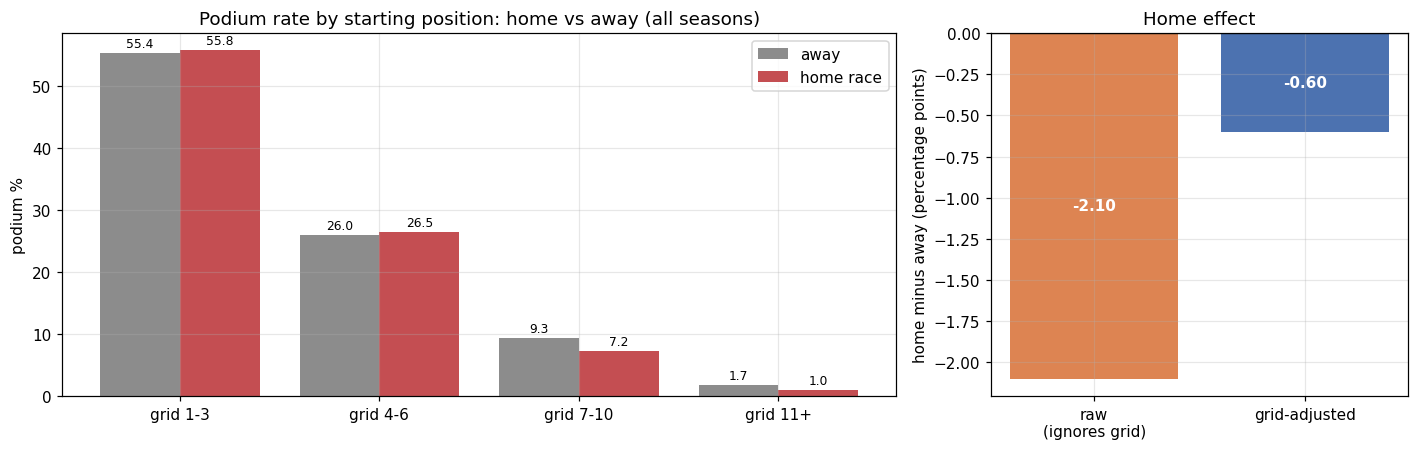

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(GRID_BANDS))
axes[0].bar(x - 0.2, band_table["podium % away"], 0.4, label="away", color="#8C8C8C")
axes[0].bar(x + 0.2, band_table["podium % home"], 0.4, label="home race", color="#C44E52")
for i, (a, h) in enumerate(zip(band_table["podium % away"], band_table["podium % home"])):
    axes[0].text(i - 0.2, a + 1, f"{a:.1f}", ha="center", fontsize=8)
    axes[0].text(i + 0.2, h + 1, f"{h:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(x, [f"grid {b}" for b in GRID_BANDS])
axes[0].set_ylabel("podium %")
axes[0].set_title("Podium rate by starting position: home vs away (all seasons)")
axes[0].legend()

s = q2_summary["all seasons (1950-2024)"]
vals = [s["raw difference (pts)"], s["grid-adjusted difference (pts)"]]
axes[1].bar(["raw\n(ignores grid)", "grid-adjusted"], vals, color=["#DD8452", "#4C72B0"])
axes[1].axhline(0, color="black", lw=0.8)
for i, v in enumerate(vals):
    axes[1].text(i, v / 2, f"{v:+.2f}", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
axes[1].set_ylabel("home minus away (percentage points)")
axes[1].set_title("Home effect")
plt.tight_layout()
plt.show()

**Answer to Q2: No, there is no home advantage once starting position is taken into account.**
- **Without controlling for grid**, home drivers even look *worse* (≈ 11.6% vs 13.7% podiums). That's misleading, because home drivers start further back on average (grid ≈ 12.7 vs 11.7). In older seasons many local drivers entered only their home race in weaker cars.
- **Comparing drivers who started from the same grid band**, the home rate is almost identical to the away rate in **every** band: slightly higher at the front (grid 1–3: ≈ 55.8% home vs 55.4% away; grid 4–6: 26.5% vs 26.0%) and slightly lower further back (grid 7–10: 7.2% vs 9.3%).
- The **grid-adjusted difference is close to zero** (about −0.6 points), and the 95% interval includes 0, so the small gap is consistent with chance. The modern era (2003+) points the same way, and so does the robustness version with the Indianapolis 500 put back (−0.59 points, interval also includes 0).
- **Takeaway:** what looks like a "home effect" is really a **starting-position effect**. Where you start matters a lot; whether you're at home doesn't. For the model this suggests a "home race" feature will add little.

*Note:* controlling with grid bands is a simple, transparent method. Within a band, small grid differences remain, but the per-band rates are so close that a finer control wouldn't change the conclusion.

## 3.3 Q3: Which constructors had the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**In simple words:** out of all the races a team's cars started, how often did one stop because something on the car broke?

- **Data source:** this question reads the **cleaned CSVs directly from the clean-data folder** (`outputs/clean_data/`, written in 2.13, loaded at the start of section 3), not the raw files and not the in-memory tables. `results_full.csv` there already has the cleaning applied: non-starters, duplicate rows and the Indianapolis 500 removed, and every status mapped to a `status_category` (2.5–2.6).
- **Tables & joins:** `clean_data/results_full.csv` ⟶ `clean_data/races.csv` on `raceId` (for `year`) ⟶ `clean_data/constructors.csv` on `constructorId` (team name).
- **Grain:** one row = one car starting one race. **Rate = mechanical retirements ÷ race starts** for that team in that period.
- **Mechanical retirement:** `status_category == "mechanical"` (engine, gearbox, hydraulics, power unit, ...; 2.5). Crashes, driver problems and regulation decisions are excluded, as the brief defines. Statuses whose cause is unclear (`Retired`, `Wheel`, `Puncture`, `Damage`, ...) are excluded from the main (**strict**) rate and added in the **broad** rate (mechanical + unclear, an upper bound).
- **Missingness:** none. Every status has a category, and non-starters were removed, so the denominator counts real starts only (checked below).
- **Small teams:** only teams with **≥ 40 starts** in a period are ranked. Team names follow the dataset: renamed teams (e.g. Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin) appear as separate entries.
- **Cutoff:** not relevant. This is a historical post-race analysis, not a feature.

In [59]:
# Same clean-data folder as the rest of section 3.
q3_results = results_full_c[["raceId", "driverId", "constructorId", "status", "status_category"]]
q3_races = races_c[["raceId", "year"]]
q3_teams = constructors_c

# Checks on what we loaded: unique grain, no missing categories, every key found.
assert not q3_results.duplicated(["raceId", "driverId"]).any()
assert q3_results["status_category"].notna().all()
assert q3_results["raceId"].isin(q3_races["raceId"]).all()
assert q3_results["constructorId"].isin(q3_teams["constructorId"]).all()

PERIODS = ["2014-2021", "2022-2024"]
q3 = (q3_results
      .merge(q3_races, on="raceId", how="left", validate="many_to_one")
      .merge(q3_teams, on="constructorId", how="left", validate="many_to_one"))
q3 = q3[q3["year"] >= 2014].copy()
q3["period"] = np.where(q3["year"] <= 2021, PERIODS[0], PERIODS[1])
q3["mechanical"] = q3["status_category"] == "mechanical"
q3["mechanical_or_unclear"] = q3["status_category"].isin(["mechanical", "unclear"])
print(f"Race starts 2014-2024: {len(q3):,}")

MIN_TEAM_STARTS = 40
q3_rates = (q3.groupby(["period", "constructor"])
            .agg(starts=("mechanical", "size"), mechanical_DNFs=("mechanical", "sum"),
                 mech_rate=("mechanical", "mean"), upper_bound=("mechanical_or_unclear", "mean"))
            .reset_index())
q3_rates = q3_rates[q3_rates["starts"] >= MIN_TEAM_STARTS]
q3_rates[["mech_rate", "upper_bound"]] = (100 * q3_rates[["mech_rate", "upper_bound"]]).round(1)
q3_rates = q3_rates.rename(columns={"mech_rate": "mechanical %", "upper_bound": "mechanical + unclear %"})

print("Field-wide mechanical-retirement rate:",
      {p: f"{100 * q3.loc[q3['period'] == p, 'mechanical'].mean():.1f}%" for p in PERIODS})
for p in PERIODS:
    display(Markdown(f"**{p}: top 5 constructors**"))
    display(q3_rates[q3_rates["period"] == p].sort_values("mechanical %", ascending=False)
            .head(5).drop(columns="period").reset_index(drop=True))

Race starts 2014-2024: 4,611
Field-wide mechanical-retirement rate: {'2014-2021': '9.1%', '2022-2024': '5.5%'}


**2014-2021: top 5 constructors**

,constructor,starts,mechanical_DNFs,mechanical %,mechanical + unclear %
0,Lotus F1,75,13,17.3,24.0
1,Toro Rosso,242,39,16.1,18.2
2,McLaren,319,43,13.5,16.3
3,Renault,200,27,13.5,16.5
4,Sauber,200,22,11.0,13.5


**2022-2024: top 5 constructors**

,constructor,starts,mechanical_DNFs,mechanical %,mechanical + unclear %
0,Alfa Romeo,88,11,12.5,12.5
1,Alpine F1 Team,136,15,11.0,11.0
2,AlphaTauri,88,6,6.8,8.0
3,Ferrari,135,7,5.2,7.4
4,Williams,134,7,5.2,8.2


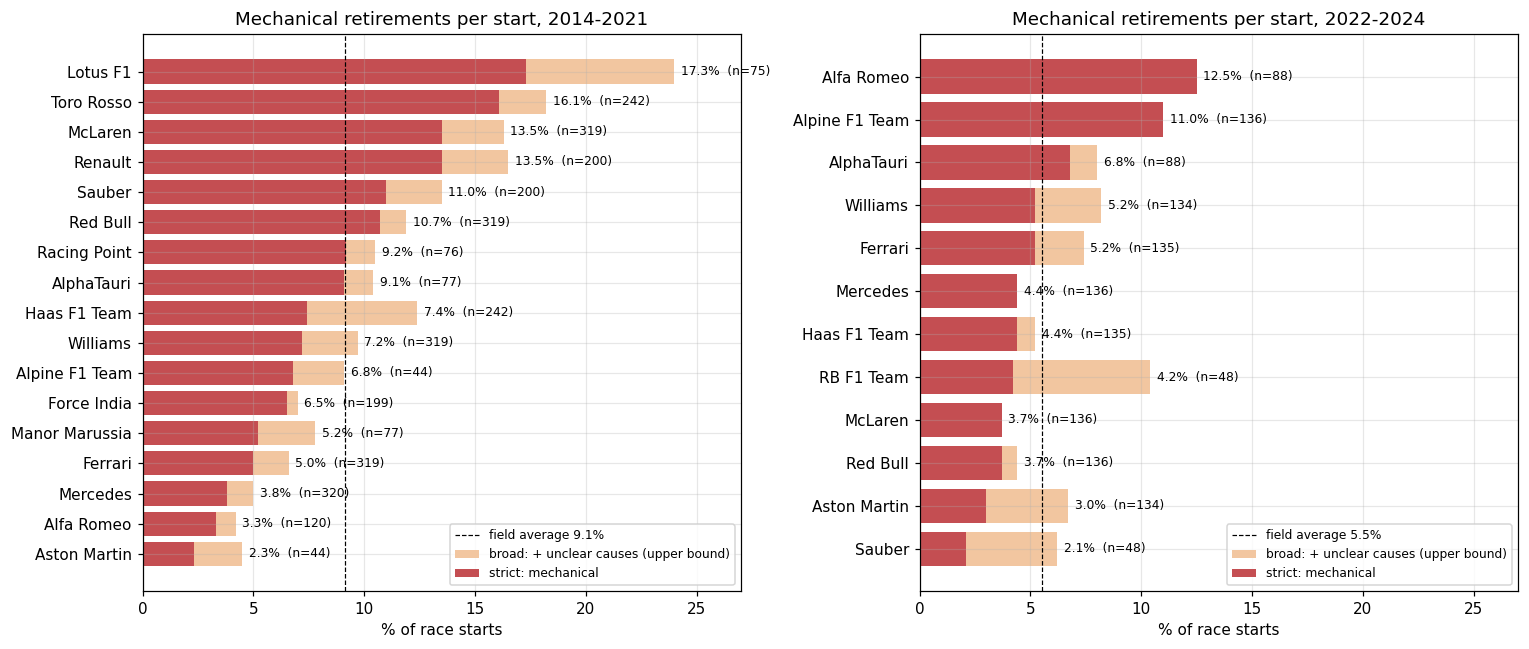

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, p in zip(axes, PERIODS):
    d = q3_rates[q3_rates["period"] == p].sort_values("mechanical %")
    ax.barh(d["constructor"], d["mechanical + unclear %"], color="#F2C6A0", label="broad: + unclear causes (upper bound)")
    ax.barh(d["constructor"], d["mechanical %"], color="#C44E52", label="strict: mechanical")
    for yy, (v, ub, n) in enumerate(zip(d["mechanical %"], d["mechanical + unclear %"], d["starts"])):
        ax.text(max(v, ub) + 0.3, yy, f"{v:.1f}%  (n={n})", va="center", fontsize=8)
    field = 100 * q3.loc[q3["period"] == p, "mechanical"].mean()
    ax.axvline(field, color="black", ls="--", lw=0.8, label=f"field average {field:.1f}%")
    ax.set_title(f"Mechanical retirements per start, {p}")
    ax.set_xlabel("% of race starts")
    ax.set_xlim(0, 27)
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Answer to Q3.**
- **2014–2021 (first hybrid engines):** the least reliable teams were **Lotus F1 (≈ 17% of starts ended with a car failure), Toro Rosso (≈ 16%) and McLaren (≈ 13.5%, tied with Renault)**. McLaren's years with the early Honda engine (2015–2017) are a well-known cause.
- **2022–2024 (new car rules):** the highest rates belong to **Alfa Romeo (≈ 12.5%) and Alpine (≈ 11%)**, then AlphaTauri (≈ 7%).
- **Big picture:** cars became **much more reliable**. The field-wide mechanical-retirement rate fell from about **9% to 5.5%** of starts, and the top teams in 2022–2024 (Red Bull, McLaren, Mercedes) retired from mechanical failures in only about 4% of starts.
- **Strict vs broad (2.5):** the strict ranking counts only *mechanical* statuses (dark bars). The broad ranking also counts *unclear* ones (`Retired`, `Wheel`, `Puncture`, ...; light bars). That raises some rates by up to ~7 points but doesn't change the top two in either period.

*Caution:* in 2022–2024 each team has at most ~136 starts, so one extra failure moves the rate by ~0.7 points. The differences between the middle teams are small.